# Human Influence in Rural Wildfire Ignitions

## Group: 02
### Name(s) & ID(s) of Group Members:
- Benedita Barreto da Costa Gonçalves - 202205903
- Isabela Moreira Merelles - 202602764
- Maria Leonor Soares Carvalho - 202307522
- Mariana Vale de Oliveira Coelho de Pinho - 202306234

## Table of Contents

1. [Research Question](#1-research-question)
2. [Collect Data](#2-collect-data)
   - 2.1 Dataset Source
   - 2.2 Dataset Details
   - 2.3 Data Preparation
3. [Explore Data](#3-explore-data)
   - 3.1 Q1: Changes in negligent causes
   - 3.2 Q2: Daily negligent ignitions on weekends and weekdays
   - 3.3 Q3: Burnt area across municipalities
   - 3.4 Q4: Burnt area by cause type and period
4. [Draw Inferences](#4-draw-inferences)
   - 4.1 Q1: Z-test for proportions and chi-square tests
   - 4.2 Q2: Welch's two-sample t-test
   - 4.3 Q3: One-way ANOVA
   - 4.4 Q4: Two-way ANOVA
5. [Formulate Conclusions](#5-formulate-conclusions)
   - 5.1 to 5.4: one conclusion per question (Q1 to Q4)
   - 5.5 Overall answer
6. [Look Back and Ahead](#6-look-back-and-ahead)
   - 6.1 Limitations
   - 6.2 Alternative Approaches and Future Work

---

## 1) Research Question

How did initial response times and burnt areas change before and after 2017, and how are these two variables associated across four Portuguese municipalities?

### Secondary Research Questions

1. **Q1.** Did the proportion of negligent fires among human-caused fires change between the pre-2017 and post-2017 periods, and was the change the same in the critical summer period and in the non-critical months?

    Difference in proportions (Variables: `Cause_Type`, `Period`, `Season_Risk_Period`). Tests: two-proportion Z-test run separately for each season; Breslow-Day chi-square test of homogeneity of odds ratios to compare the two seasons.

2. **Q2.** Did the mean number of daily negligent wildfire ignitions differ significantly between weekends and weekdays in the post-2017 period across the municipalities of Chaves, Montalegre, Ourém and Tomar?

    Mean comparison (Variables: `Daily_Ignitions_Count`, `Day_Type`, `Period`). Test: Welch's two-sample t-test.

3. **Q3.** Does the mean log-transformed burnt area per fire (equivalently, the geometric mean burnt area per fire) differ significantly across Chaves, Montalegre, Ourém and Tomar during 2018–2025?

    ANOVA (Variables: ln(`Total_Burnt_Area`), `Municipality`). Test: one-way ANOVA with Tukey HSD.

4. **Q4.** Did the disparity in final burnt area between intentional and negligent causes narrow in the post-2017 period in the municipalities under study?

    ANOVA (Variables: `Log_Total_Burnt_Area`, `Cause_Type`, `Period`). Test: two-way ANOVA.

---

## 2) Collect Data

### 2.1 Dataset Source

The dataset used in this project was sourced from the Institute for Nature Conservation and Forests (ICNF), specifically the wildfire statistics published under the Information Management section of [their website](https://www.icnf.pt/florestas/gfr/gfrgestaoinformacao/estatisticas). This dataset contains data on human influenced wildfire ignitions from 2001 until 2025. The records are split across three ICNF files (2001-2010, 2011-2020 and 2021-2025), and were combined into a single dataset before analysis.

The raw file contains 40 columns covering fire identifiers, location, timestamps, burnt area by land cover, fire weather indices, and cause classification. Only a subset of these columns was used in the analysis, and several variables were derived from them. The full mapping is described below so that the variables can be reproduced from the raw file.

### 2.2 Dataset Details

#### Qualitative Variables

- **Cause_Type**: Intentional vs. Negligent. Derived from the cause classification column (`TipoCausa`), keeping only validated human causes. Fires with an unclassified or unknown cause were excluded.

- **Period**: Pre-2017 (2001–2016) vs. Post-2017 (2018–2025). Derived from `Ano`. In practice, the law was only implemented in 2021, so the post-2017 group mixes pre-law and post-law years (see limitations).

- **Municipality**: Chaves, Montalegre, Ourém, Tomar. Taken from `Concelho`.

- **Season_Risk_Period**: Critical Period vs. Non-Critical Period. Derived from `Mes`, with the critical period defined as 1 June to 30 September.

- **Day_Type**: Weekend vs. Weekday. Derived from the fire alert date (`DataHoraAlerta`), with Saturday and Sunday classified as weekend.

- **Cause_Type_Period**: Combined factor of `Cause_Type` and `Period`, used for the pairwise comparisons in Q4.

#### Quantitative Variables

- **Daily_Ignitions_Count**: Number of negligent ignitions per municipality per day, computed by counting records grouped by `Date` and `Concelho`.

- **Total_Burnt_Area**: Total surface burnt per occurrence, in hectares, from `AreaTotal_ha`.

- **Log_Total_Burnt_Area**: log10(`Total_Burnt_Area`) for fires with a burnt area above 0 ha (missing for fires with 0 ha, see Section 2.3), the response variable of Q4. Q3 uses the natural logarithm ln(`Total_Burnt_Area`), computed in Section 3.3. The base of the logarithm only rescales the values and does not affect the tests.

- **Initial_Response_Time**: Time in minutes between `DataHoraAlerta` and `DataHora_PrimeiraIntervencao`.

- **Fire_Duration**: Total duration from fire alert to final extinction, in hours, from `Duracao_Horas`.

### 2.3 Data Preparation

#### Setup

All libraries, file paths and plotting conventions are defined once in the cell below and reused in every section. Each factor level keeps the same colour in all figures.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
from scipy.stats import norm
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.proportion as smp
from statsmodels.stats.contingency_tables import StratifiedTable, Table2x2
from IPython.display import display

%matplotlib inline
%config InlineBackend.figure_format = "retina"

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| statsmodels", statsmodels.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

# ---------------------------------------------------------------- paths
project_path = Path.cwd()
raw = project_path / "01_dataset/raw"
processed = project_path / "01_dataset/processed"
processed.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------- fixed factor orders
MUNICIPALITIES = ["Chaves", "Montalegre", "Ourém", "Tomar"]
PERIOD_ORDER = ["Pre-2017", "Post-2017"]
CAUSE_ORDER = ["Intentional", "Negligent"]
SEASON_ORDER = ["Critical", "Non-Critical"]
DAY_ORDER = ["Weekday", "Weekend"]

# ---------------------------------- colours (colour-blind-safe set)
BLUE, ORANGE, GREEN, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"

PAL_PERIOD = dict(zip(PERIOD_ORDER, [BLUE, ORANGE]))
PAL_CAUSE = dict(zip(CAUSE_ORDER, [BLUE, ORANGE]))
PAL_SEASON = dict(zip(SEASON_ORDER, [BLUE, ORANGE]))
PAL_DAY = dict(zip(DAY_ORDER, [BLUE, ORANGE]))
PAL_MUN = dict(zip(MUNICIPALITIES, [BLUE, ORANGE, GREEN, YELLOW]))

# ------------------------------------------------ common plot style
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "font.sans-serif": ["DejaVu Sans"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})


def fig_title(fig, text):
    """Figure-level title for multi-panel figures, same look as the axes titles."""
    fig.suptitle(text, x=0.01, ha="left", fontsize=12, fontweight="bold")


def qq_panel(ax, values, color, title, ylabel="Sample quantiles"):
    """Normal Q-Q plot with a reference line through the quartiles."""
    (osm, osr), _ = stats.probplot(values, dist="norm")
    ax.scatter(osm, osr, s=6, color=color, alpha=.5, edgecolor="none")
    lo, hi = np.percentile(values, [25, 75])
    z_lo, z_hi = stats.norm.ppf([.25, .75])
    slope = (hi - lo) / (z_hi - z_lo)
    ax.plot(osm, lo + slope * (osm - z_lo), color=INK, linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Theoretical quantiles")
    ax.set_ylabel(ylabel)

Python 3.11.1 | numpy 1.23.5 | pandas 1.5.3 | scipy 1.10.1 | statsmodels 0.15.0 | matplotlib 3.7.1 | seaborn 0.12.2


#### Loading the raw files

In [2]:
needed_cols = [
    "Ano", "Mes", "Dia", "Hora", "AreaTotal_ha", "Duracao_Horas",
    "DataHoraAlerta", "DataHora_PrimeiraIntervencao", "DataHora_Extincao",
    "Concelho", "Freguesia", "TipoCausa", "Codigo_SGIF",
]

df1 = pd.read_excel(raw / "Registos_Incendios_SGIF_2021_2025.xlsx", usecols=needed_cols)
df2 = pd.read_excel(raw / "Registos_Incendios_SGIF_2011_2020.xlsx", usecols=needed_cols)
df3 = pd.read_excel(raw / "Registos_Incendios_SGIF_2001_2010.xlsx", usecols=needed_cols)

# confirm that the raw files share the same schema
print("df1 vs df2:", df1.columns.equals(df2.columns))
print("df2 vs df3:", df2.columns.equals(df3.columns))

/var/folders/n2/bvvvs5j937xbw0hlvdr0s4c80000gn/T/ipykernel_1326/1916978677.py:9: FutureWarning: Inferring datetime64[ns] from data containing strings is deprecated and will be removed in a future version. To retain the old behavior explicitly pass Series(data, dtype=datetime64[ns])
  df3 = pd.read_excel(raw / "Registos_Incendios_SGIF_2001_2010.xlsx", usecols=needed_cols)


df1 vs df2: True
df2 vs df3: True


Before deriving variables, the sample size was checked by municipality and year to confirm that all four municipalities are represented across the full period.

In [3]:
# Concatenate the three files (2001 to 2025)
df = pd.concat([df1, df2, df3], ignore_index=True)

# Keep the four municipalities and the full 2001-2025 window
df_final = df[df["Concelho"].isin(MUNICIPALITIES)].copy()
df_final = df_final[df_final["Ano"].between(2001, 2025)].copy()

print(df_final["Concelho"].value_counts())
print(pd.crosstab(df_final["Concelho"], df_final["Ano"], margins=True))

Montalegre    5635
Chaves        3914
Ourém         2691
Tomar         2280
Name: Concelho, dtype: int64
Ano         2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  ...  \
Concelho                                                                ...   
Chaves       259   307   127   188   326   167   130   139   308   127  ...   
Montalegre   262   283   177   194   390   147   238   149   475   177  ...   
Ourém        118   159   116   166   293   188   136   144    99    97  ...   
Tomar         58   115    86   166   186   125   130   108   110    95  ...   
All          697   864   506   714  1195   627   634   540   992   496  ...   

Ano         2017  2018  2019  2020  2021  2022  2023  2024  2025    All  
Concelho                                                                 
Chaves       132    67    66    73    46   105    36    68    94   3914  
Montalegre   314   119   168   134   191   192   117    94   131   5635  
Ourém         96    82    63    97    64    8

#### Derived variables

In [4]:
# Quantitative variables

# Initial_Response_Time
for col in ["DataHoraAlerta", "DataHora_PrimeiraIntervencao", "DataHora_Extincao"]:
    df_final[col] = pd.to_datetime(df_final[col], errors="coerce")

df_final["Initial_Response_Time"] = (
    df_final["DataHora_PrimeiraIntervencao"] - df_final["DataHoraAlerta"]
).dt.total_seconds() / 60

# Fire_Duration
df_final["Fire_Duration"] = df_final["Duracao_Horas"]

# Total_Burnt_Area
df_final["Total_Burnt_Area"] = df_final["AreaTotal_ha"]

# Log scale used in the two-way ANOVA (Q4): fires with 0 ha are left as missing (rule below)
df_final["Log_Total_Burnt_Area"] = np.log10(
    df_final["Total_Burnt_Area"].where(df_final["Total_Burnt_Area"] > 0)
)

In [5]:
# Qualitative variables

# Period (2017 is a transition year and is excluded from every question)
df_final["Period"] = np.where(df_final["Ano"] <= 2016, "Pre-2017",
                       np.where(df_final["Ano"] >= 2018, "Post-2017", "Transition"))

# Season_Risk_Period
df_final["Season_Risk_Period"] = np.where(
    df_final["Mes"].isin([6, 7, 8, 9]),
    "Critical", "Non-Critical"
)

# Day_Type
df_final["Day_Type"] = np.where(
    df_final["DataHoraAlerta"].dt.dayofweek >= 5,
    "Weekend", "Weekday"
)

In [6]:
# Cause_Type: keep only validated human causes
cause_map = {
    "Negligente": "Negligent",
    "Intencional": "Intentional",
}

df_final["Cause_Type"] = df_final["TipoCausa"].map(cause_map)

df_final["Cause_Type_Period"] = np.where(
    df_final["Cause_Type"].isna(),
    np.nan,
    df_final["Cause_Type"].astype(str) + "_" + df_final["Period"].astype(str),
)

# Daily count of negligent ignitions (2017 excluded), used in Q2
df_final["Date"] = df_final["DataHoraAlerta"].dt.date

df_neg = df_final[
    (df_final["Cause_Type"] == "Negligent")
    & (df_final["Period"] != "Transition")
].copy()

daily = (
    df_neg.groupby(["Concelho", "Date", "Period"])
    .size()
    .reset_index(name="Daily_Ignitions_Count")
)

daily["Day_Type"] = np.where(
    pd.to_datetime(daily["Date"]).dt.dayofweek >= 5, "Weekend", "Weekday"
)

#### Fires with 0 ha

Fires recorded with a burnt area of 0 ha are valid ignitions that were extinguished before burning a measurable area. They are kept in the analyses that count fires or ignitions (Q1 and Q2), because these questions concern whether a fire started, not how large it became. They are excluded from the analyses of burnt area on the logarithmic scale (Q3 and Q4), because the logarithm of 0 is undefined. This affects 1 of 2,739 fires in Q3 and 3 of 6,519 fires in Q4. No constant is added before taking the logarithm, so the back-transformed means are exact geometric means.

In [7]:
# Missing values in each column
print("Number of missing values for each column:")
print(df_final.isnull().sum())

Number of missing values for each column:
Codigo_SGIF                        0
Ano                                0
Mes                                0
Dia                                0
Hora                               0
AreaTotal_ha                       0
DataHoraAlerta                     0
DataHora_PrimeiraIntervencao    5583
DataHora_Extincao                 43
Duracao_Horas                     43
Concelho                           0
Freguesia                          0
TipoCausa                       6043
Initial_Response_Time           5583
Fire_Duration                     43
Total_Burnt_Area                   0
Log_Total_Burnt_Area             293
Period                             0
Season_Risk_Period                 0
Day_Type                           0
Cause_Type                      7357
Cause_Type_Period               7357
Date                               0
dtype: int64


In [8]:
df_final.describe()

,Ano,Mes,Dia,Hora,AreaTotal_ha,Duracao_Horas,Initial_Response_Time,Fire_Duration,Total_Burnt_Area,Log_Total_Burnt_Area
count,14520.000000,14520.000000,14520.000000,14520.000000,14520.000000,14477.000000,8937.000000,14477.000000,14520.000000,14227.000000
mean,2011.001446,6.891116,15.793595,14.687190,9.087475,2.433111,18.117153,2.433111,9.087475,-0.767152
std,6.668413,2.635995,8.666318,5.363572,116.325010,6.112195,30.905899,6.112195,116.325010,1.241346
min,2001.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-4.301030
25%,2005.000000,5.000000,8.000000,12.000000,0.010000,0.616667,9.000000,0.616667,0.010000,-2.000000
50%,2010.000000,8.000000,16.000000,15.000000,0.200000,1.250000,14.000000,1.250000,0.200000,-0.602060
75%,2016.000000,9.000000,23.000000,18.000000,1.130000,2.533333,20.000000,2.533333,1.130000,0.136725
max,2025.000000,12.000000,31.000000,23.000000,6379.000000,244.550000,1456.000000,244.550000,6379.000000,3.804753


#### Saving the processed data

The processed data are saved so that each question can be analysed from its own file.

In [9]:
df_final.to_excel(processed / "wildfires_processed.xlsx", index=False)
daily.to_excel(processed / "daily_ignitions.xlsx", index=False)

In [10]:
# Q1: Negligent vs Intentional, Pre vs Post, Critical vs Non-Critical (Z-test)
q1 = df_final[
    (df_final["Cause_Type"].notna()) & (df_final["Period"] != "Transition")
].copy()
q1.to_excel(processed / "q1_cause_period_season.xlsx", index=False)

# Q2: Daily negligent ignitions, Weekend vs Weekday (t-test)
q2 = daily.dropna(subset=["Date", "Daily_Ignitions_Count"]).copy()
q2.to_excel(processed / "q2_daily_ignitions.xlsx", index=False)

# Q3: Burnt area by municipality (one-way ANOVA; restricted to 2018-2025 in Section 3.3)
q3 = df_final[
    (df_final["Total_Burnt_Area"].notna())
    & (df_final["Period"] != "Transition")
].copy()
q3.to_excel(processed / "q3_burnt_area_municipality.xlsx", index=False)

# Q4: Burnt area by Cause_Type and Period (two-way ANOVA)
q4 = df_final[
    (df_final["Cause_Type"].notna())
    & (df_final["Period"] != "Transition")
    & (df_final["Total_Burnt_Area"] > 0)      # rule for fires with 0 ha (Section 2.3)
].copy()
q4.to_excel(processed / "q4_burnt_area_cause_period.xlsx", index=False)

#### Missing values

| Question | Variables used | Rows dropped where |
|---|---|---|
| Q1 | `Cause_Type`, `Period`, `Season_Risk_Period` | `Cause_Type` is missing or `Period == 'Transition'` (2017) |
| Q2 | `Daily_Ignitions_Count`, `Day_Type`, `Period` | Non-negligent causes, date is missing, or `Period == 'Transition'` |
| Q3 | ln(`Total_Burnt_Area`), `Municipality` | `Total_Burnt_Area` is missing or `Period == 'Transition'`; the analysis then keeps 2018–2025 only (Section 3.3) |
| Q4 | `Log_Total_Burnt_Area`, `Cause_Type`, `Period` | `Cause_Type` is missing, `Total_Burnt_Area` is missing or 0 ha, or `Period == 'Transition'` |

In [11]:
log = pd.DataFrame({
    "dataset": ["pooled", "q1", "q2", "q3", "q4"],
    "n_rows": [len(df_final), len(q1), len(q2), len(q3), len(q4)],
    "exclusion": [
        "Initial 4-municipality cohort (2001-2025)",
        "Missing Cause_Type and Transition year (2017) excluded",
        "Negligent daily counts (2017 excluded)",
        "Missing Burnt Area and 2017 excluded",
        "Missing Cause_Type, missing or 0 ha Burnt Area, and 2017 excluded",
    ],
})
log.to_excel(processed / "sample_sizes.xlsx", index=False)
log

,dataset,n_rows,exclusion
0,pooled,14520,Initial 4-municipality cohort (2001-2025)
1,q1,6519,Missing Cause_Type and Transition year (2017) ...
2,q2,2897,Negligent daily counts (2017 excluded)
3,q3,13816,Missing Burnt Area and 2017 excluded
4,q4,6516,"Missing Cause_Type, missing or 0 ha Burnt Area..."


---

## 3) Explore Data

### 3.1 Q1: Changes in Negligent Causes

In this first phase, we focused on Q1: testing whether the change in the proportion of negligent causes was concentrated in the critical summer period or if it also affected autumn and winter burning months.

#### Counts by period and season

In [12]:
q1_counts = pd.crosstab(
    [q1["Period"], q1["Season_Risk_Period"]],
    q1["Cause_Type"],
    margins=True
)
q1_counts

Cause_Type                    Intentional  Negligent   All
Period    Season_Risk_Period                              
Post-2017 Critical                    639        576  1215
          Non-Critical                150       1120  1270
Pre-2017  Critical                   1120       1411  2531
          Non-Critical                261       1242  1503
All                                  2170       4349  6519

The total sample for Q1 consists of 6,519 fires due to human cause.

All four combinations have more than 1,200 observations. This means the sample is large enough to trust the Z-test on proportions, and we do not need to worry about small-cell bias.

In the critical period, the counts show intentional fires dropped (from 1,120 to 639), but negligent fires dropped even more (from 1,411 to 576).

#### Proportion of negligent fires

In [13]:
q1_props = (
    q1.groupby(["Period", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)
q1_props

,Period,Season_Risk_Period,negligent_share
0,Post-2017,Critical,0.474074
1,Post-2017,Non-Critical,0.881890
2,Pre-2017,Critical,0.557487
3,Pre-2017,Non-Critical,0.826347


In the Critical period, negligent ignitions dropped from 55.7% to 47.4% post-2017.

In the Non-Critical period, the negligent share actually went up from 82.6% to 88.2%. This is because the counts show that intentional fires in this season fell (261 down to 150), while negligent fires stayed relatively stable (1,242 down to 1,120). Because intentional fires dropped faster than negligent ones, the overall proportion of negligent fires went up.

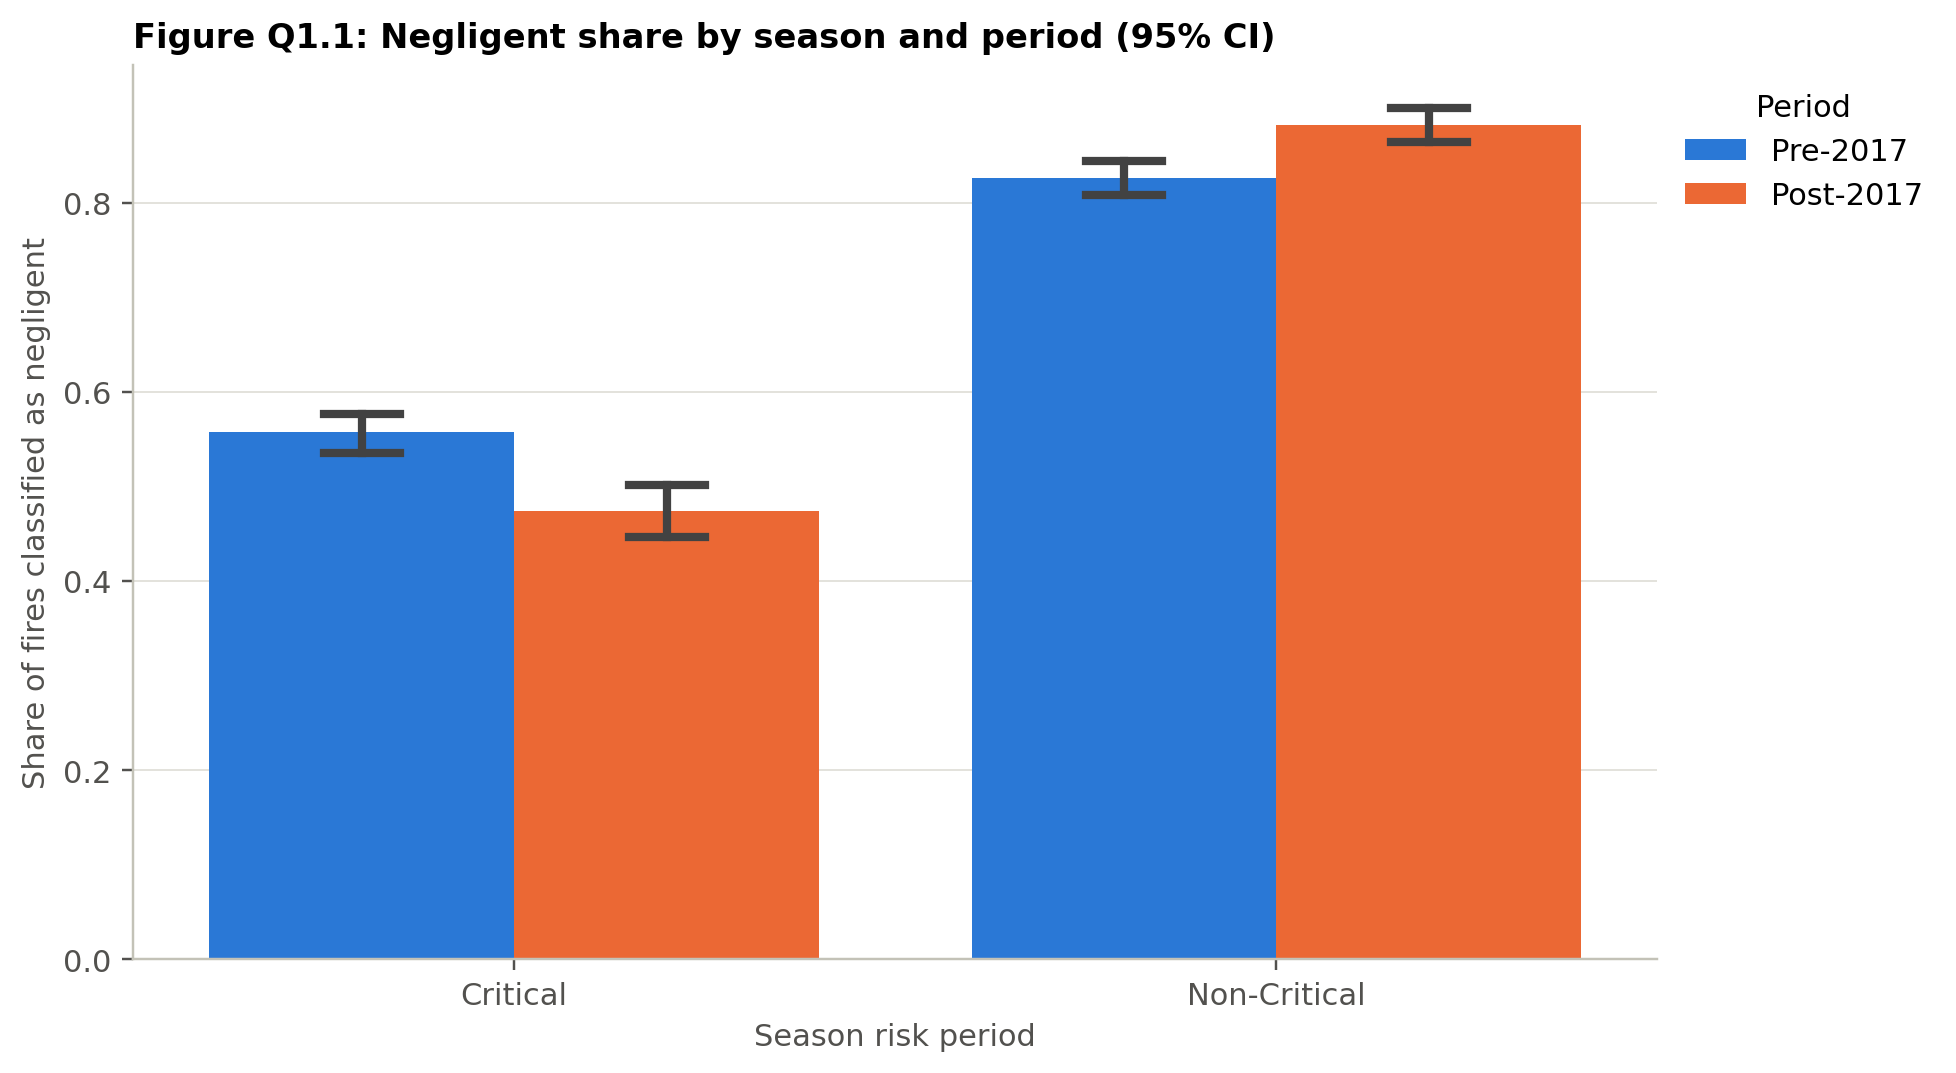

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=q1, x="Season_Risk_Period", y=(q1["Cause_Type"] == "Negligent").astype(int),
    hue="Period", order=SEASON_ORDER, hue_order=PERIOD_ORDER, palette=PAL_PERIOD,
    saturation=1, errorbar="ci", capsize=0.1, ax=ax
)
ax.set_title("Figure Q1.1: Negligent share by season and period (95% CI)")
ax.set_xlabel("Season risk period")
ax.set_ylabel("Share of fires classified as negligent")
ax.legend(title="Period", loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

Figure Q1.1 shows the share of negligent fires among human-caused fires before and after 2017, split by season.

In the **Critical** period, the negligent share fell from 55.7% to 47.4%. The 95% confidence intervals do not overlap, which agrees with the significant Z-test in Section 4.1.

In the **Non-Critical** period the share was already very high and rose from 82.6% to 88.2%. The change is smaller in percentage points (+5.6 vs −8.3), but the intervals also do not overlap, and the test in Section 4.1 confirms that this increase is statistically significant.

The two seasons therefore moved in opposite directions.

#### Negligence over time

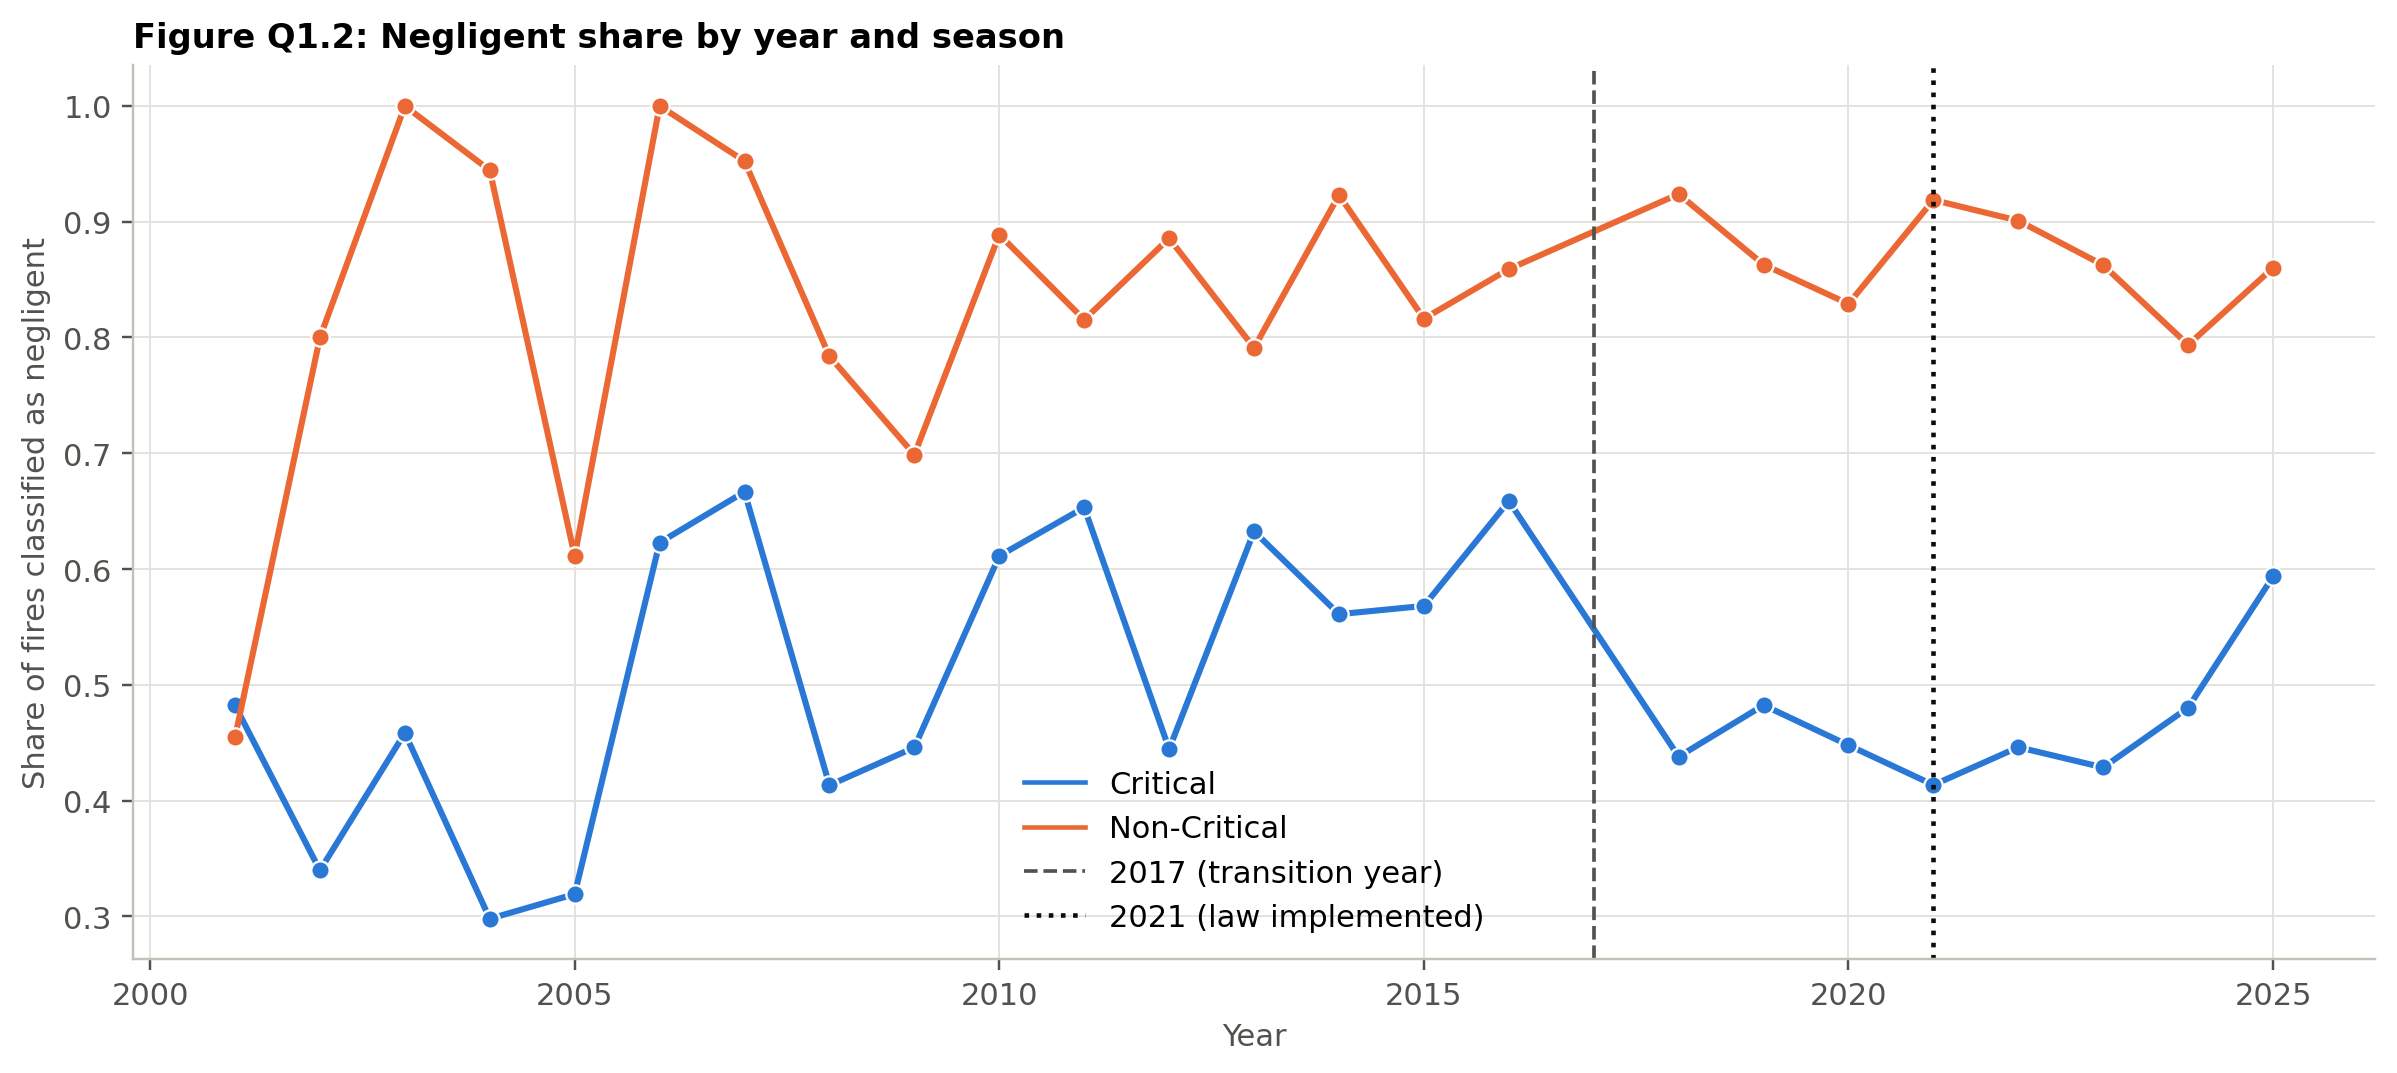

In [15]:
year_season = (
    q1.groupby(["Ano", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=year_season, x="Ano", y="negligent_share",
             hue="Season_Risk_Period", hue_order=SEASON_ORDER, palette=PAL_SEASON,
             marker="o", linewidth=2, ax=ax)
ax.axvline(2017, color=MUTED, linestyle="--", linewidth=1.2, label="2017 (transition year)")
ax.axvline(2021, color=INK, linestyle=":", linewidth=1.5, label="2021 (law implemented)")
ax.set_title("Figure Q1.2: Negligent share by year and season")
ax.set_xlabel("Year")
ax.set_ylabel("Share of fires classified as negligent")
ax.legend(title="")
plt.tight_layout()
plt.show()

#### Summary

To explore this question, we split the data into pre-2017 and post-2017 periods and compared the share of negligent fires among human-caused fires between the critical (June to September) and non-critical months. The two seasons moved in opposite directions. In the critical period, the negligent share fell from 55.7% to 47.4%. In the non-critical months, where negligence was already the dominant cause, it rose from 82.6% to 88.2%. The reduction in negligent ignitions therefore did not affect the whole year: it appeared only in the summer, while in the other months negligent fires became an even larger share of the total. Whether these changes, and the difference between them, are statistically significant is tested in Section 4.1.

Figure Q1.2 does not show a clear break at the 2021 law. If the law had deterred negligent ignitions, we would expect a sharp drop right after that year. Instead, the non-critical line shows no visible change, and the critical line dips slightly in 2021 but is back up by 2024 and 2025. Yearly shares are based on few fires per year in some groups, so this is only a visual impression, and the data cannot attribute any change to a specific policy.

---

### 3.2 Q2: Daily Negligent Ignitions on Weekends and Weekdays

In this section we address Q2, which asks whether the mean number of daily negligent wildfire ignitions differed significantly between weekends and weekdays in the post-2017 period across the municipalities of Chaves, Montalegre, Ourém and Tomar.

Before conducting inferential testing, we examine the sample distribution of daily negligent ignitions conditional on active fire days ($Y \ge 1$) across weekdays and weekends, contrasting the pre-2017 and post-2017 cohorts.

**Methodological note on zero-area records ($0\text{ ha}$).** All validated negligent wildfire occurrences recorded in the SGIF database, including those with a final burnt area of $0\text{ ha}$ (such as immediate extinguishments), are explicitly **retained** in the daily count aggregation (`Daily_Ignitions_Count`), as the research question evaluates ignition incidence rather than fire size. Because count variables present positive skewness, both robust measures (median, IQR) and parametric metrics (mean, standard deviation) are reported to fully assess central tendency and dispersion.

#### Data

In [16]:
q2 = pd.read_excel(processed / "q2_daily_ignitions.xlsx")

# fixed data types and factor orders
q2["Date"] = pd.to_datetime(q2["Date"])
q2["Period"] = pd.Categorical(q2["Period"], categories=PERIOD_ORDER, ordered=True)
q2["Day_Type"] = pd.Categorical(q2["Day_Type"], categories=DAY_ORDER, ordered=True)

q2.info()
q2.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2897 entries, 0 to 2896
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Concelho               2897 non-null   object        
 1   Date                   2897 non-null   datetime64[ns]
 2   Period                 2897 non-null   category      
 3   Daily_Ignitions_Count  2897 non-null   int64         
 4   Day_Type               2897 non-null   category      
dtypes: category(2), datetime64[ns](1), int64(1), object(1)
memory usage: 73.9+ KB


,Concelho,Date,Period,Daily_Ignitions_Count,Day_Type
0,Chaves,2001-07-21,Pre-2017,1,Weekend
1,Chaves,2001-07-29,Pre-2017,1,Weekend
2,Chaves,2001-08-10,Pre-2017,1,Weekday
3,Chaves,2001-08-13,Pre-2017,1,Weekday
4,Chaves,2001-08-16,Pre-2017,1,Weekday


#### Descriptive statistics

In [17]:
# Summary statistics by Period and Day_Type
summary_stats = (
    q2.groupby(["Period", "Day_Type"], observed=False)["Daily_Ignitions_Count"]
    .agg(
        n="count",
        mean="mean",
        std="std",
        median="median",
        iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
        min="min",
        max="max",
    )
    .reset_index()
)

# standard error of the mean (SEM)
summary_stats["sem"] = summary_stats["std"] / np.sqrt(summary_stats["n"])

print("Summary statistics for daily negligent ignitions:")
display(summary_stats.round(3))

Summary statistics for daily negligent ignitions:


,Period,Day_Type,n,mean,std,median,iqr,min,max,sem
0,Pre-2017,Weekday,1253,1.505,1.056,1.0,1.0,1,10,0.030
1,Pre-2017,Weekend,505,1.519,1.067,1.0,1.0,1,8,0.047
2,Post-2017,Weekday,802,1.455,1.161,1.0,0.0,1,11,0.041
3,Post-2017,Weekend,337,1.570,1.402,1.0,1.0,1,12,0.076


#### Distribution of daily negligent ignitions

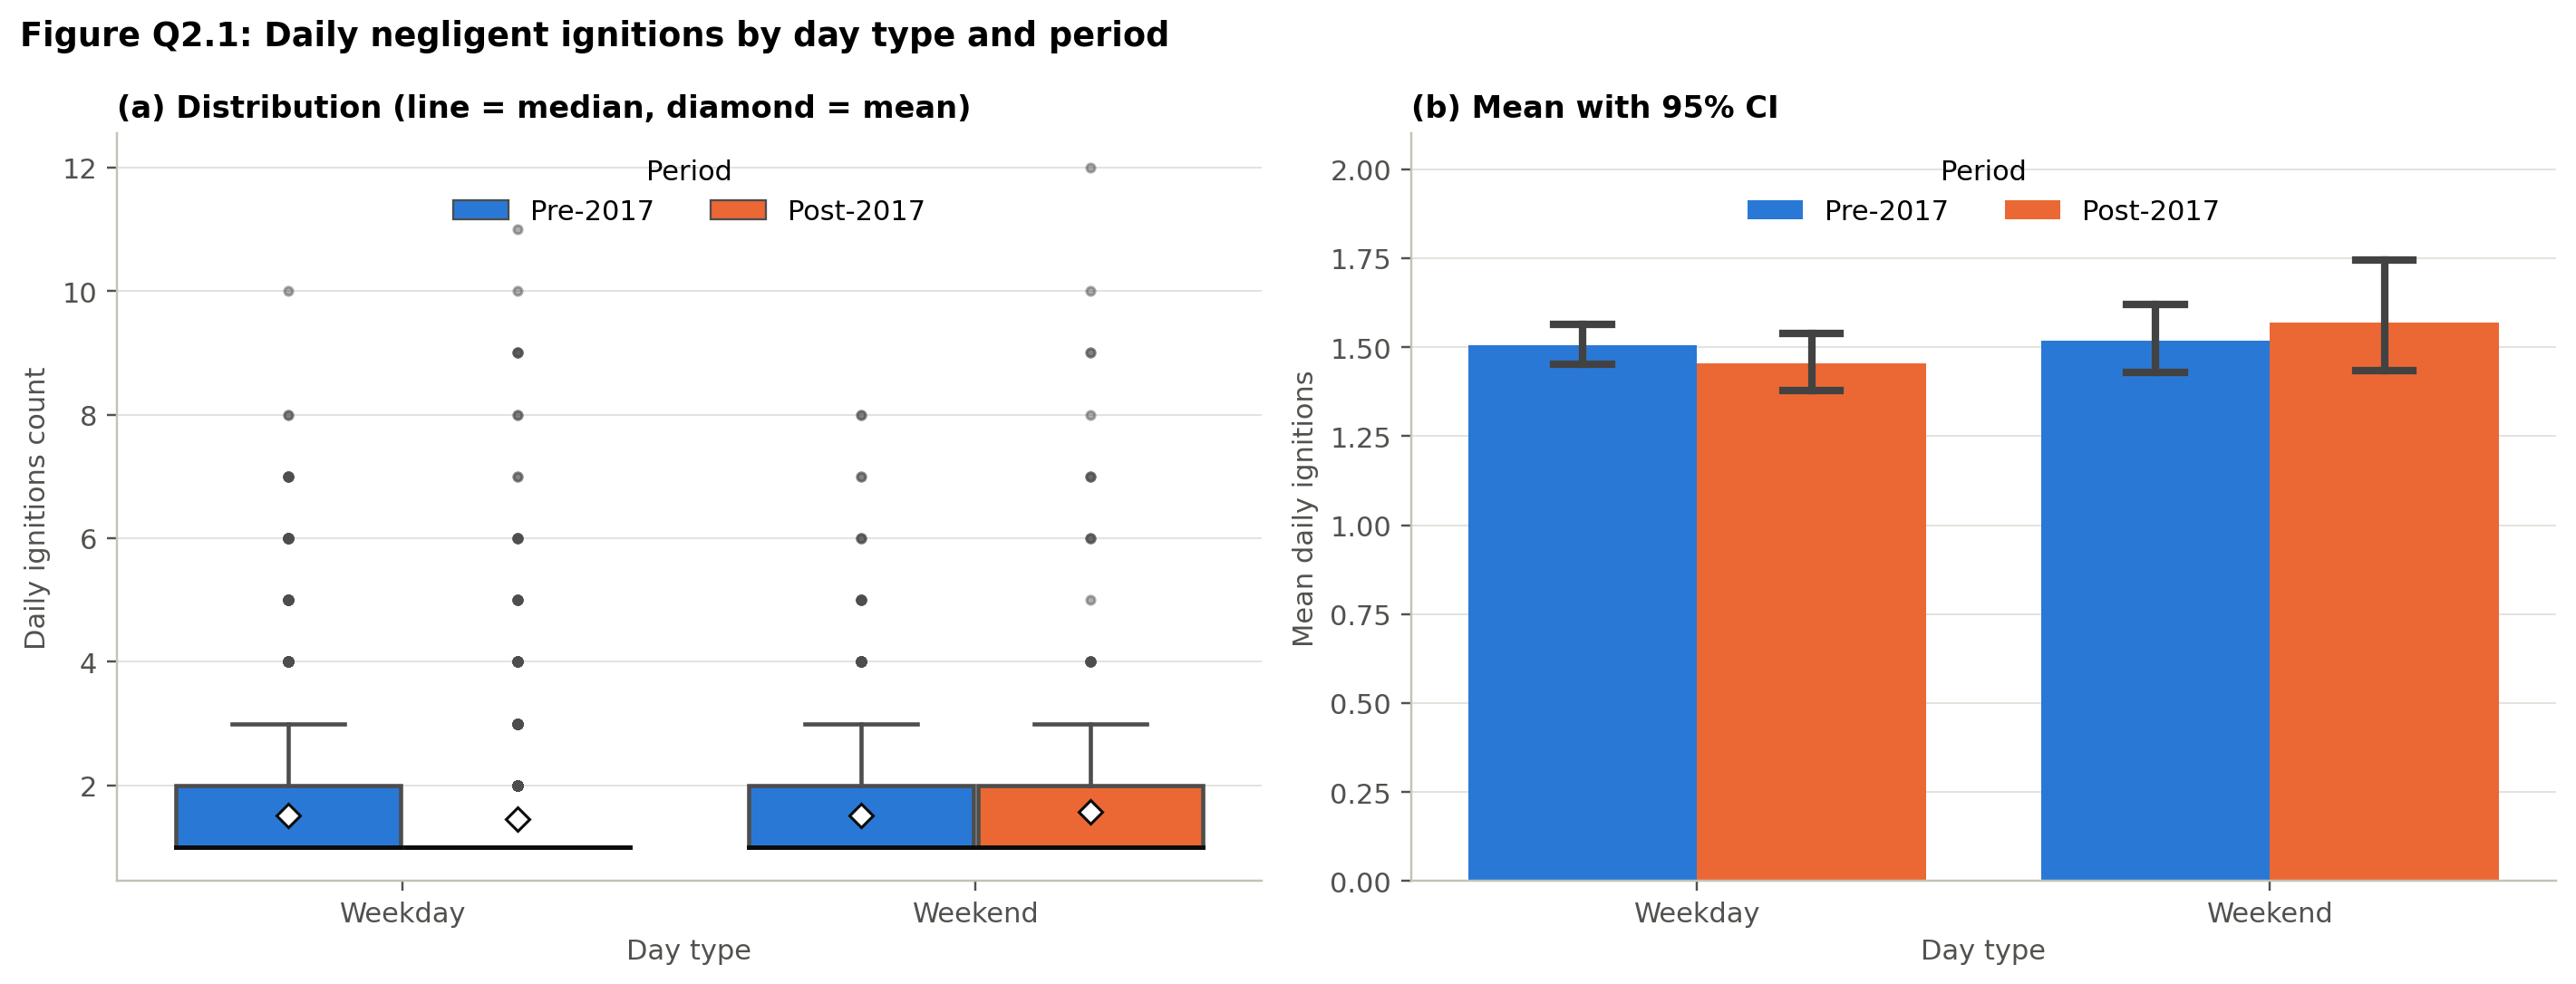

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Boxplot
sns.boxplot(
    data=q2, x="Day_Type", y="Daily_Ignitions_Count", hue="Period",
    order=DAY_ORDER, hue_order=PERIOD_ORDER, palette=PAL_PERIOD, saturation=1,
    ax=axes[0], showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": INK, "markersize": 6},
    medianprops={"color": INK, "linewidth": 1.6},
    flierprops={"marker": "o", "markersize": 3, "alpha": .45},
)
axes[0].set_title("(a) Distribution (line = median, diamond = mean)")
axes[0].set_xlabel("Day type")
axes[0].set_ylabel("Daily ignitions count")
axes[0].legend(title="Period", loc="upper center", ncol=2)

# (b) Means with 95% CI
sns.barplot(
    data=q2, x="Day_Type", y="Daily_Ignitions_Count", hue="Period",
    order=DAY_ORDER, hue_order=PERIOD_ORDER, palette=PAL_PERIOD, saturation=1,
    errorbar=("ci", 95), capsize=0.1, ax=axes[1]
)
axes[1].set_title("(b) Mean with 95% CI")
axes[1].set_xlabel("Day type")
axes[1].set_ylabel("Mean daily ignitions")
axes[1].set_ylim(0, 2.1)
axes[1].legend(title="Period", loc="upper center", ncol=2)

fig_title(fig, "Figure Q2.1: Daily negligent ignitions by day type and period")
plt.tight_layout()
plt.show()

---

### 3.3 Q3: Burnt Area across Municipalities

**Research question.** Does the mean log-transformed burnt area per fire (equivalently, the geometric mean burnt area per fire) differ significantly across Chaves, Montalegre, Ourém and Tomar during 2018–2025?

| Element | Definition |
|---|---|
| Unit of observation | One wildfire occurrence (SGIF record), all causes |
| Response | ln(`Total_Burnt_Area`), natural logarithm of the final burnt area in hectares |
| Factor | `Concelho` (municipality), 4 levels |
| Period | 2018–2025, filtered with `Ano` (2017 is the excluded transition year) |
| Method | Classical one-way ANOVA, Tukey HSD post-hoc comparisons, α = 0.05 |

**Scale of the conclusions.** For positive areas, exp(mean of ln area) is the **geometric mean** of the area. The test therefore compares geometric means, and pairwise differences on the log scale become **ratios of geometric means**. It does **not** test the equality of arithmetic mean burnt areas in hectares, which are reported only descriptively.

The data source, preprocessing and derived variables are documented in Section 2 and are not repeated here. Unlike the two-way ANOVA of burnt area by cause type and period, this analysis uses only the post-2017 period and has municipality as its single factor.

#### Data preparation and validation

The Q3 file saved in Section 2.3 covers both periods, so the sample is rebuilt here from the main processed file by keeping the four municipalities and the years 2018–2025 (`Ano`). The assertions stop the notebook if the processed file changes in a way that would invalidate the analysis.

In [19]:
from statsmodels.stats.oneway import anova_oneway    # Welch ANOVA (not in the shared setup cell)
STUDY_YEARS = (2018, 2025)
Y = "Total_Burnt_Area"                               # final burnt area per fire (ha)
DATA_DIR = processed                                 # path defined in the shared setup cell (Section 2.3)
COLORS = PAL_MUN                                     # same colours as the shared municipality palette

In [20]:
wf = pd.read_excel(DATA_DIR / "wildfires_processed.xlsx")
wf["Codigo_SGIF"] = wf["Codigo_SGIF"].astype(str)          # identifiers mix int and str in the Excel file

q3 = wf[wf["Concelho"].isin(MUNICIPALITIES) & wf["Ano"].between(*STUDY_YEARS)].copy()
q3["Concelho"] = pd.Categorical(q3["Concelho"], categories=MUNICIPALITIES)
q3_ln = q3[q3[Y] > 0].copy()                                  # ln(area) is undefined for 0 ha
q3_ln["ln_area"] = np.log(q3_ln[Y])

assert q3[Y].notna().all() and (q3[Y] >= 0).all(),           "missing or negative burnt areas"
assert q3["Codigo_SGIF"].is_unique,                           "duplicated SGIF identifiers"
assert (q3[Y] == q3["AreaTotal_ha"]).all(),                   "Total_Burnt_Area differs from AreaTotal_ha"
assert (q3["Period"] == "Post-2017").all(),                   "Period label inconsistent with Ano"
assert len(q3) == 2739, "sample size changed: the numbers reported in the Markdown cells must be updated"

print(f"Processed file: {len(wf):,} records ({wf['Ano'].min()}-{wf['Ano'].max()}) -> Q3 sample: {len(q3):,} "
      f"-> ANOVA sample (area > 0): {len(q3_ln):,}")
print("Fires per municipality:", q3["Concelho"].value_counts(sort=False).to_dict())
print("Causes (TipoCausa):", q3["TipoCausa"].value_counts(dropna=False).to_dict())
print(f"Areas: = 0 ha: {(q3[Y] == 0).sum()} | < 0.01 ha: {(q3[Y] < 0.01).sum()} | "
      f"exactly 0.01 ha: {np.isclose(q3[Y], 0.01).sum()} ({100 * np.isclose(q3[Y], 0.01).mean():.1f} %)")
print("Last alert in the data:", q3["DataHoraAlerta"].max())

# Recording precision of very small fires, by municipality
small = pd.DataFrame({"exactly 0.01 ha": np.isclose(q3[Y], 0.01), "below 0.01 ha": q3[Y] < 0.01})
print(small.groupby(q3["Concelho"], observed=True).sum().T.to_string())

Processed file: 14,520 records (2001-2025) -> Q3 sample: 2,739 -> ANOVA sample (area > 0): 2,738
Fires per municipality: {'Chaves': 555, 'Montalegre': 1146, 'Ourém': 620, 'Tomar': 418}
Causes (TipoCausa): {'Negligente': 1696, 'Intencional': 789, 'Reacendimento': 130, 'Desconhecida': 98, 'Natural': 14, nan: 12}
Areas: = 0 ha: 1 | < 0.01 ha: 312 | exactly 0.01 ha: 315 (11.5 %)
Last alert in the data: 2025-11-04 18:49:00
Concelho         Chaves  Montalegre  Ourém  Tomar
exactly 0.01 ha     126         181      5      3
below 0.01 ha        33          38    141    100


**Sample decisions.**

- **All causes are kept**, including reignitions (130 records). Q3 compares municipalities and does not depend on the cause of the fire, so all fires are included; Q4, which compares intentional and negligent fires, is restricted to those two causes. Each record has its own SGIF code and burnt area.
- **No outliers are removed.** Very large fires are a genuine feature of the distribution; the log scale limits their influence on the test.
- **One fire with 0 ha** is excluded from the log-scale analysis (n = 2,738); the descriptive statistics use all 2,739 fires.
- **0.01 ha** is the most frequent recorded value (315 fires, 11.5 %), but it is not a minimum recording threshold, since 312 fires have smaller areas.
- **Recording precision differs between municipalities.** Very small fires are mostly recorded as exactly 0.01 ha in Chaves and Montalegre (126 and 181 records, against 33 and 38 below 0.01 ha), whereas Ourém and Tomar record them more precisely, often below 0.01 ha (141 and 100 records, against 5 and 3 at exactly 0.01 ha). Because the log scale magnifies differences among very small areas, part of the gap in geometric means may reflect recording practice. The robustness checks in Section 4.3 therefore repeat the analysis with all areas below 0.01 ha set to 0.01 ha.
- **2025 is incomplete** (the last alert is in early November 2025); its influence is checked in the robustness checks of Section 4.3.

#### Descriptive statistics

Descriptive statistics use the original scale (hectares). The geometric mean, exp(mean of ln area), is the quantity compared by the ANOVA; it is computed from fires with area > 0 (in Ourém, 619 of 620). The share of area in the five largest fires is given per municipality only.

In [21]:
def describe(a):
    a = pd.Series(a)
    return pd.Series({"n": len(a), "mean": a.mean(), "sd": a.std(), "Q1": a.quantile(.25), "median": a.median(),
                      "Q3": a.quantile(.75), "max": a.max(), "geometric mean": np.exp(np.log(a[a > 0]).mean()),
                      "% fires < 1 ha": 100 * (a < 1).mean(),
                      "% of area in 5 largest fires": 100 * a.nlargest(5).sum() / a.sum()})

summary = pd.DataFrame({m: describe(q3.loc[q3["Concelho"] == m, Y]) for m in MUNICIPALITIES}).T
summary.loc["All"] = describe(q3[Y])
summary.loc["All", "% of area in 5 largest fires"] = np.nan      # not comparable with the per-municipality values
summary["n"] = summary["n"].astype(int)
display(summary.round(3))

areas = q3[Y].sort_values(ascending=False)
n_top = int(np.ceil(0.01 * len(areas)))
print(f"The largest 1 % of fires ({n_top}) account for {100 * areas.iloc[:n_top].sum() / areas.sum():.1f} % of the total "
      f"burnt area; overall mean / median = {areas.mean() / areas.median():.0f}")

,n,mean,sd,Q1,median,Q3,max,geometric mean,% fires < 1 ha,% of area in 5 largest fires
Chaves,555,18.125,191.871,0.010,0.158,0.962,3367.930,0.139,75.315,82.621
Montalegre,1146,13.682,130.046,0.100,0.772,3.038,4147.733,0.505,66.492,39.959
Ourém,620,13.869,159.285,0.012,0.054,0.196,2936.000,0.051,89.516,83.682
Tomar,418,3.172,35.486,0.010,0.045,0.202,606.525,0.041,93.780,91.268
All,2739,13.021,143.072,0.017,0.162,0.900,4147.733,0.158,77.656,NaN


The largest 1 % of fires (28) account for 71.2 % of the total burnt area; overall mean / median = 80


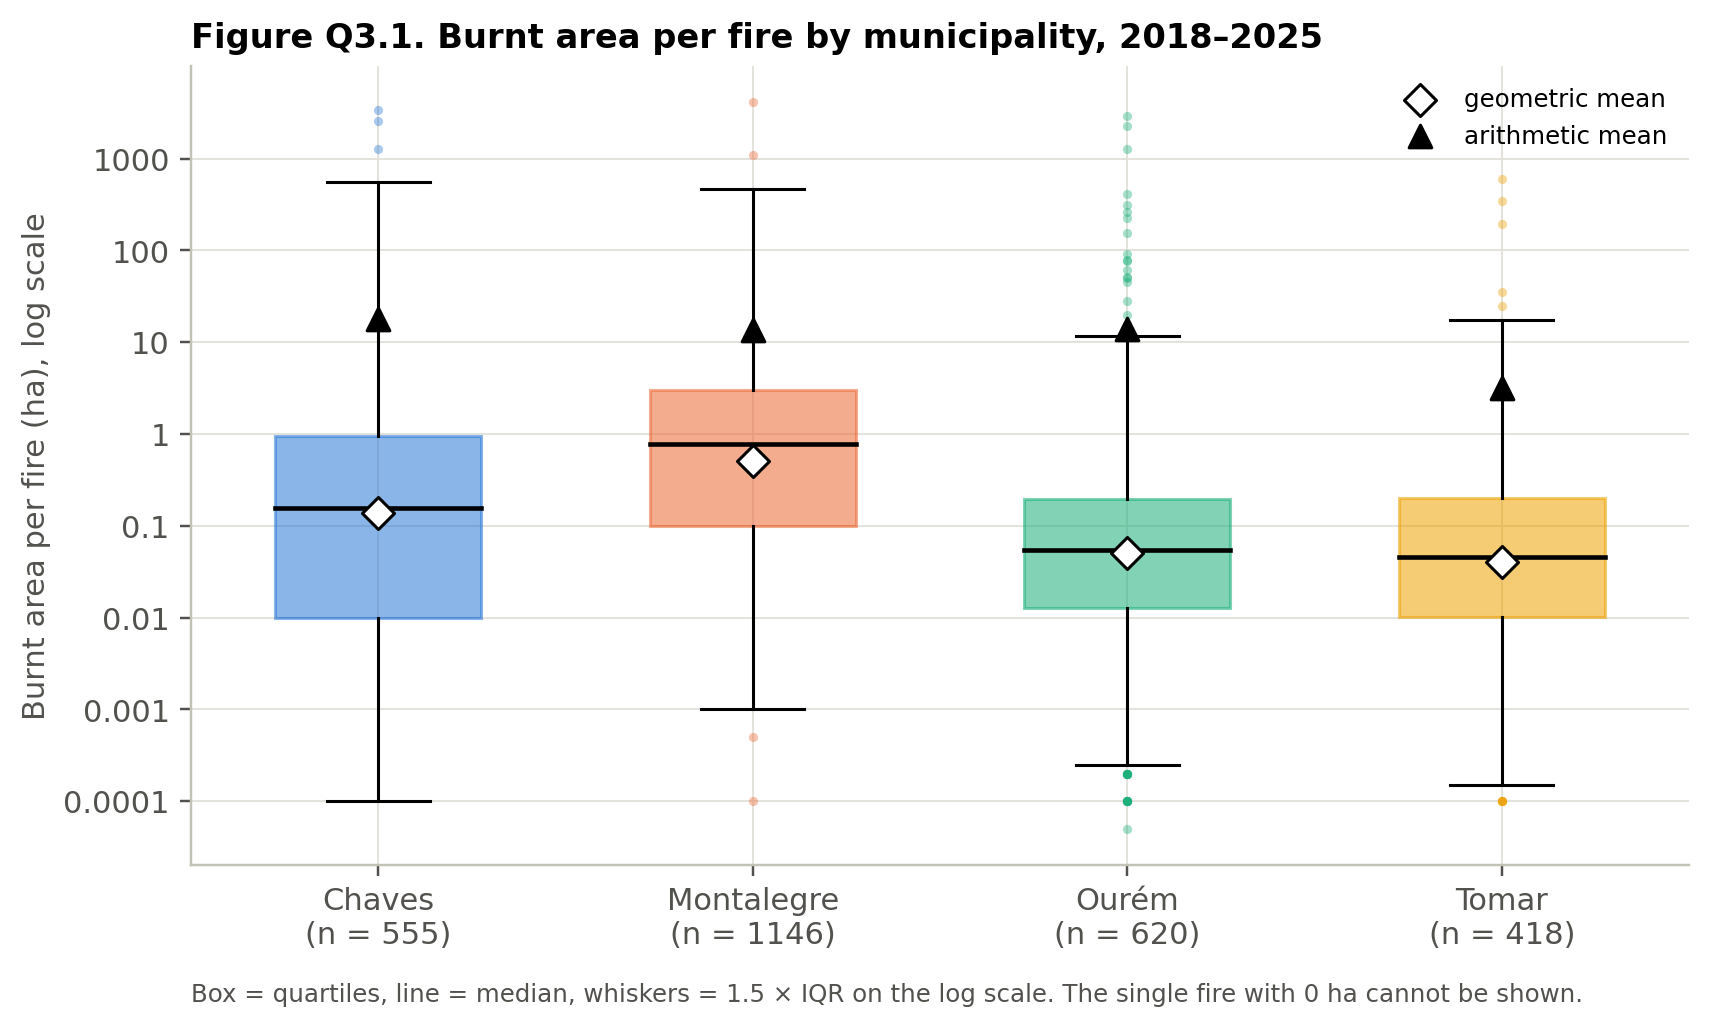

In [22]:
# Figure Q3.1 - distribution of burnt area per fire by municipality.
# The boxplot is computed on log10(area), so whiskers and outliers follow the scale of the analysis.
groups = [np.log10(q3.loc[(q3["Concelho"] == m) & (q3[Y] > 0), Y]) for m in MUNICIPALITIES]
fig, ax = plt.subplots(figsize=(8, 4.8))
bp = ax.boxplot(groups, patch_artist=True, widths=0.55, medianprops=dict(color="black", linewidth=1.5),
                flierprops=dict(marker="o", markersize=3, alpha=.4, markeredgewidth=0))
for patch, fl, m in zip(bp["boxes"], bp["fliers"], MUNICIPALITIES):
    patch.set(facecolor=COLORS[m], alpha=.55, edgecolor=COLORS[m]); fl.set(markerfacecolor=COLORS[m])
ax.scatter(range(1, 5), np.log10(summary.loc[MUNICIPALITIES, "geometric mean"]), marker="D", s=55,
           facecolor="white", edgecolor="black", zorder=4, label="geometric mean")
ax.scatter(range(1, 5), np.log10(summary.loc[MUNICIPALITIES, "mean"]), marker="^", s=55,
           color="black", zorder=4, label="arithmetic mean")
ax.set_xticks(range(1, 5), [f"{m}\n(n = {int(summary.loc[m, 'n'])})" for m in MUNICIPALITIES])
ticks = np.arange(-4, 4)
ax.set_yticks(ticks, [f"{10.0 ** t:g}" for t in ticks])
ax.set_ylabel("Burnt area per fire (ha), log scale")
ax.set_title("Figure Q3.1. Burnt area per fire by municipality, 2018–2025")
ax.legend(frameon=False, loc="upper right", fontsize=8)
ax.text(0, -0.17, "Box = quartiles, line = median, whiskers = 1.5 × IQR on the log scale. "
        "The single fire with 0 ha cannot be shown.", transform=ax.transAxes, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

**Interpretation.** Burnt area is extremely right-skewed: 77.7 % of the fires burnt less than 1 ha, while the largest 1 % (28 fires) account for 71.2 % of the total burnt area, and the overall arithmetic mean (13.0 ha) is about 80 times the median (0.16 ha). The arithmetic means rank the municipalities Chaves > Ourém > Montalegre > Tomar, whereas the medians and geometric means rank them Montalegre > Chaves > Ourém > Tomar. The difference arises because each arithmetic mean depends on a handful of fires: the five largest fires hold between 40 % (Montalegre) and 91 % (Tomar) of each municipality's burnt area (Figure Q3.1, triangles far above the boxes). A comparison of arithmetic means would therefore mostly reflect a few extreme events.

---

### 3.4 Q4: Burnt Area by Cause Type and Period

In this section we address Q4, which asks whether the gap in final burnt area between intentional and negligent fires became smaller after 2017 in the four municipalities under study.

The burnt area is analysed on a log10 scale because it is extremely right-skewed, with most fires below 1 ha and a few above 1,000 ha. Following the rule in Section 2.3, the 3 fires with 0 ha are excluded, so no constant is added before taking the logarithm. The back-transformed mean, 10^mean, is therefore the geometric mean of the burnt area, which describes the typical fire much better than the arithmetic mean.

#### Data

In [23]:
q4 = pd.read_excel(processed / "q4_burnt_area_cause_period.xlsx")

# fixed order of the factor levels for tables and plots
q4["Period"] = pd.Categorical(q4["Period"], categories=PERIOD_ORDER, ordered=True)
q4["Cause_Type"] = pd.Categorical(q4["Cause_Type"], categories=CAUSE_ORDER, ordered=True)

pd.crosstab(q4["Cause_Type"], q4["Period"], margins=True)

Period,Pre-2017,Post-2017,All
Cause_Type,,,
Intentional,1381,789,2170
Negligent,2651,1695,4346
All,4032,2484,6516


#### Descriptive statistics

In [24]:
q4_desc = (
    q4.groupby(["Period", "Cause_Type"], observed=True)
      .agg(n=("Log_Total_Burnt_Area", "size"),
           mean_log=("Log_Total_Burnt_Area", "mean"),
           sd_log=("Log_Total_Burnt_Area", "std"),
           median_ha=("Total_Burnt_Area", "median"),
           mean_ha=("Total_Burnt_Area", "mean"))
)
# geometric mean in hectares (back-transformation of the mean of log10(area))
q4_desc["geom_mean_ha"] = 10 ** q4_desc["mean_log"]
q4_desc.round(3)

n  mean_log  sd_log  median_ha  mean_ha  \
Period    Cause_Type                                                
Pre-2017  Intentional  1381    -0.580   1.272      0.260   24.761   
          Negligent    2651    -0.414   1.149      0.500    8.628   
Post-2017 Intentional   789    -0.991   1.281      0.085   23.227   
          Negligent    1695    -0.664   1.221      0.290    8.731   

                       geom_mean_ha  
Period    Cause_Type                 
Pre-2017  Intentional         0.263  
          Negligent           0.385  
Post-2017 Intentional         0.102  
          Negligent           0.217

The design is unbalanced (from 789 to 2,651 fires per group), but every group is large. The table also shows why the log scale is needed. Intentional fires have a much higher arithmetic mean (around 23 to 25 ha vs 9 ha), but a lower median (0.26 vs 0.50 ha before 2017), because a few very large intentional fires inflate the mean. The geometric means (0.10 to 0.39 ha) are of the same order of magnitude as the medians (0.09 to 0.50 ha) and, unlike the arithmetic means, show negligent fires as larger than intentional fires in both periods.

#### Distribution of burnt area by group

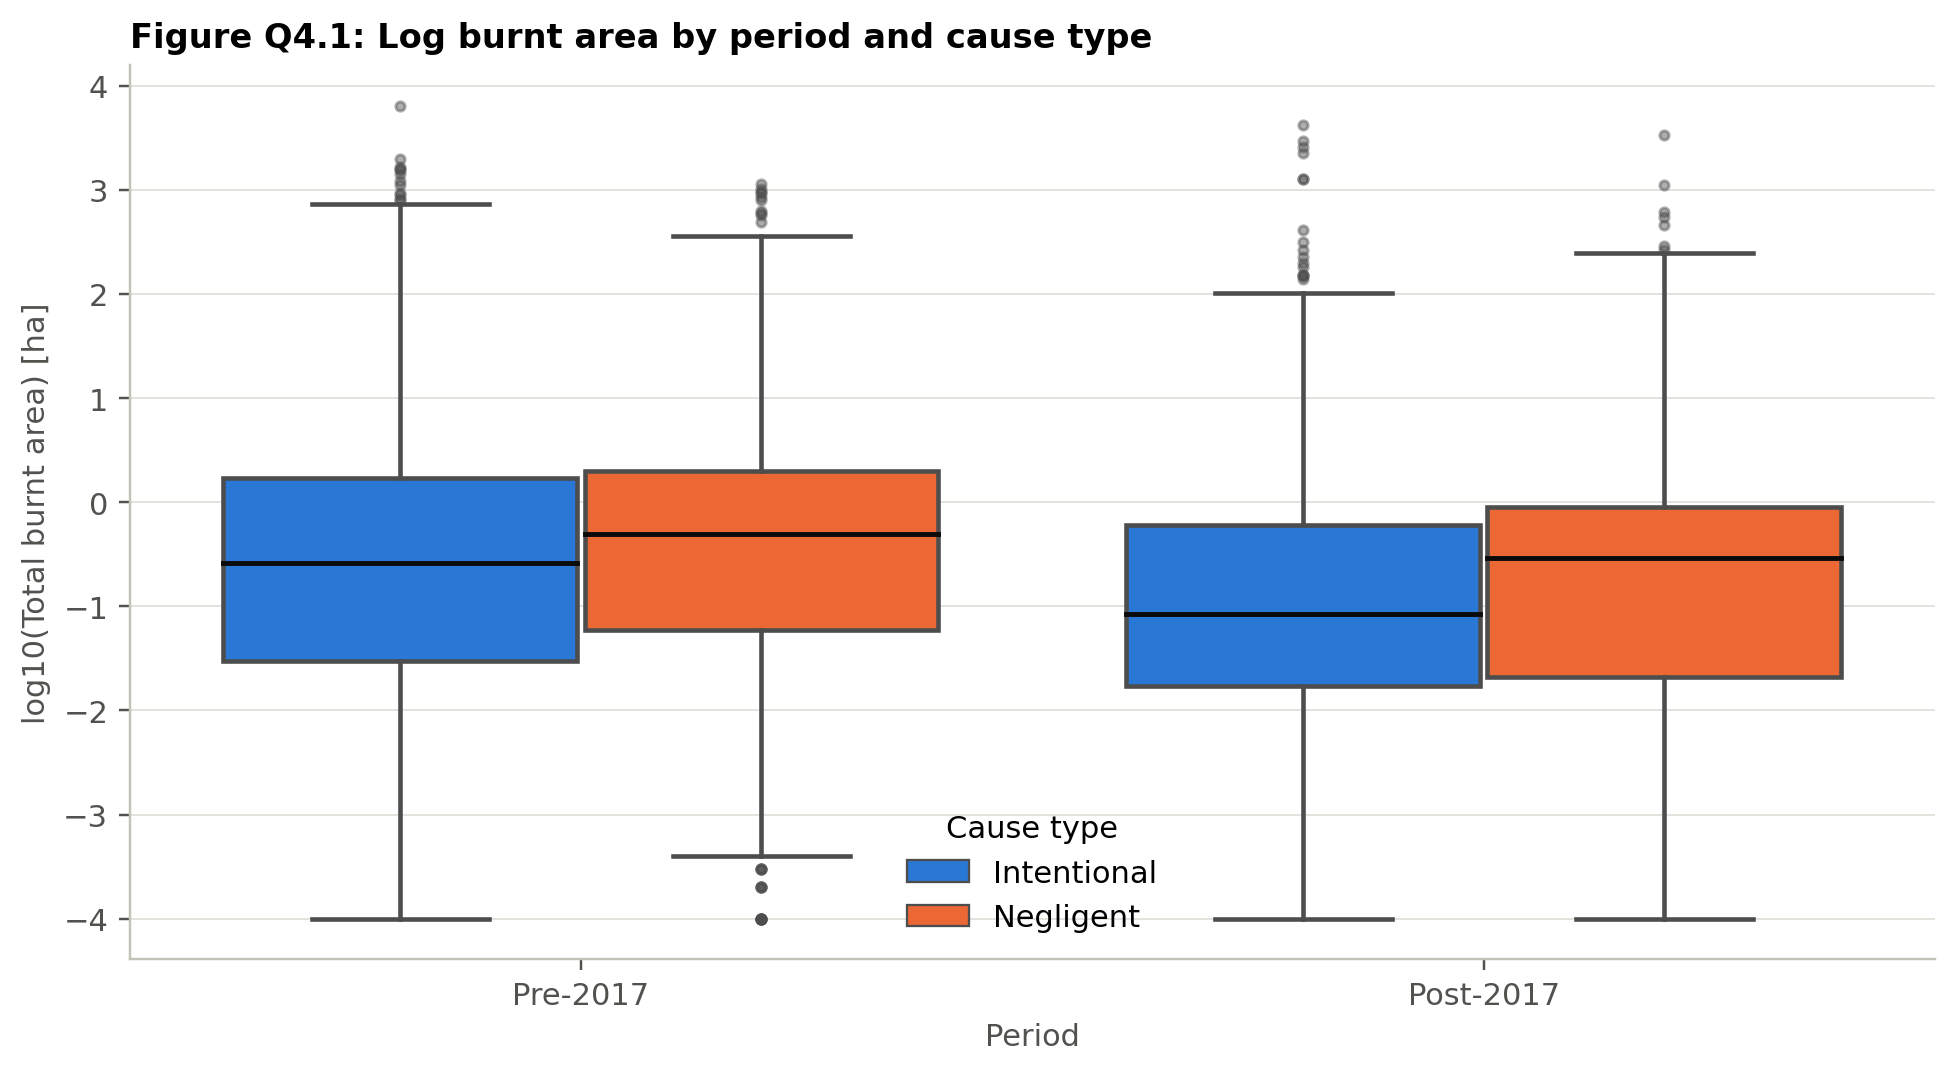

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=q4, x="Period", y="Log_Total_Burnt_Area", hue="Cause_Type",
            order=PERIOD_ORDER, hue_order=CAUSE_ORDER, palette=PAL_CAUSE, saturation=1,
            medianprops={"color": INK, "linewidth": 1.6},
            flierprops={"marker": "o", "markersize": 3, "alpha": .45}, ax=ax)
ax.set_title("Figure Q4.1: Log burnt area by period and cause type")
ax.set_ylabel("log10(Total burnt area) [ha]")
ax.set_xlabel("Period")
ax.legend(title="Cause type")
plt.tight_layout()
plt.show()

In [26]:
# Numbers behind Figure Q4.1 (boxplot statistics on the log scale)
box_rows = []
for (cause, period), g in q4.groupby(["Cause_Type", "Period"], observed=True):
    x = g["Log_Total_Burnt_Area"]
    area = g["Total_Burnt_Area"]
    lo, med, hi = x.quantile([0.25, 0.5, 0.75])
    iqr = hi - lo
    box_rows.append({
        "Cause_Type": cause,
        "Period": period,
        "min": x.min(),
        "lower_whisker": x[x >= lo - 1.5 * iqr].min(),
        "Q1": lo,
        "median": med,
        "Q3": hi,
        "upper_whisker": x[x <= hi + 1.5 * iqr].max(),
        "max": x.max(),
        "n_outliers_upper": (x > hi + 1.5 * iqr).sum(),
        "n_outliers_lower": (x < lo - 1.5 * iqr).sum(),
        "n_0.01_ha": (area == 0.01).sum(),
    })
pd.DataFrame(box_rows).round(3)

,Cause_Type,Period,min,lower_whisker,Q1,median,Q3,upper_whisker,max,n_outliers_upper,n_outliers_lower,n_0.01_ha
0,Intentional,Pre-2017,-4.0,-4.000,-1.523,-0.585,0.230,2.859,3.805,12,0,76
1,Intentional,Post-2017,-4.0,-4.000,-1.770,-1.071,-0.222,2.008,3.618,16,0,32
2,Negligent,Pre-2017,-4.0,-3.398,-1.228,-0.301,0.301,2.556,3.060,10,15,268
3,Negligent,Post-2017,-4.0,-4.000,-1.675,-0.538,-0.046,2.394,3.527,7,0,229


In [27]:
# Most frequent burnt area values (in ha)
q4["Total_Burnt_Area"].value_counts().head(6)

0.01    605
0.50    442
1.00    375
2.00    227
0.10    193
1.50    166
Name: Total_Burnt_Area, dtype: int64

Figure Q4.1 shows that the four distributions overlap heavily, as expected for a variable with high natural variability. Even so, the median of negligent fires is higher than that of intentional fires in both periods (-0.30 vs -0.59 before 2017 and -0.54 vs -1.07 after 2017), and all medians are lower after 2017. The lower whiskers reach -4 in three groups because of very small fires recorded with 0.0001 ha; among negligent fires before 2017, these fires appear as 15 lower outliers. Areas are often recorded as rounded values, and 0.01 ha is the most frequent value (605 fires).

#### Interaction plot

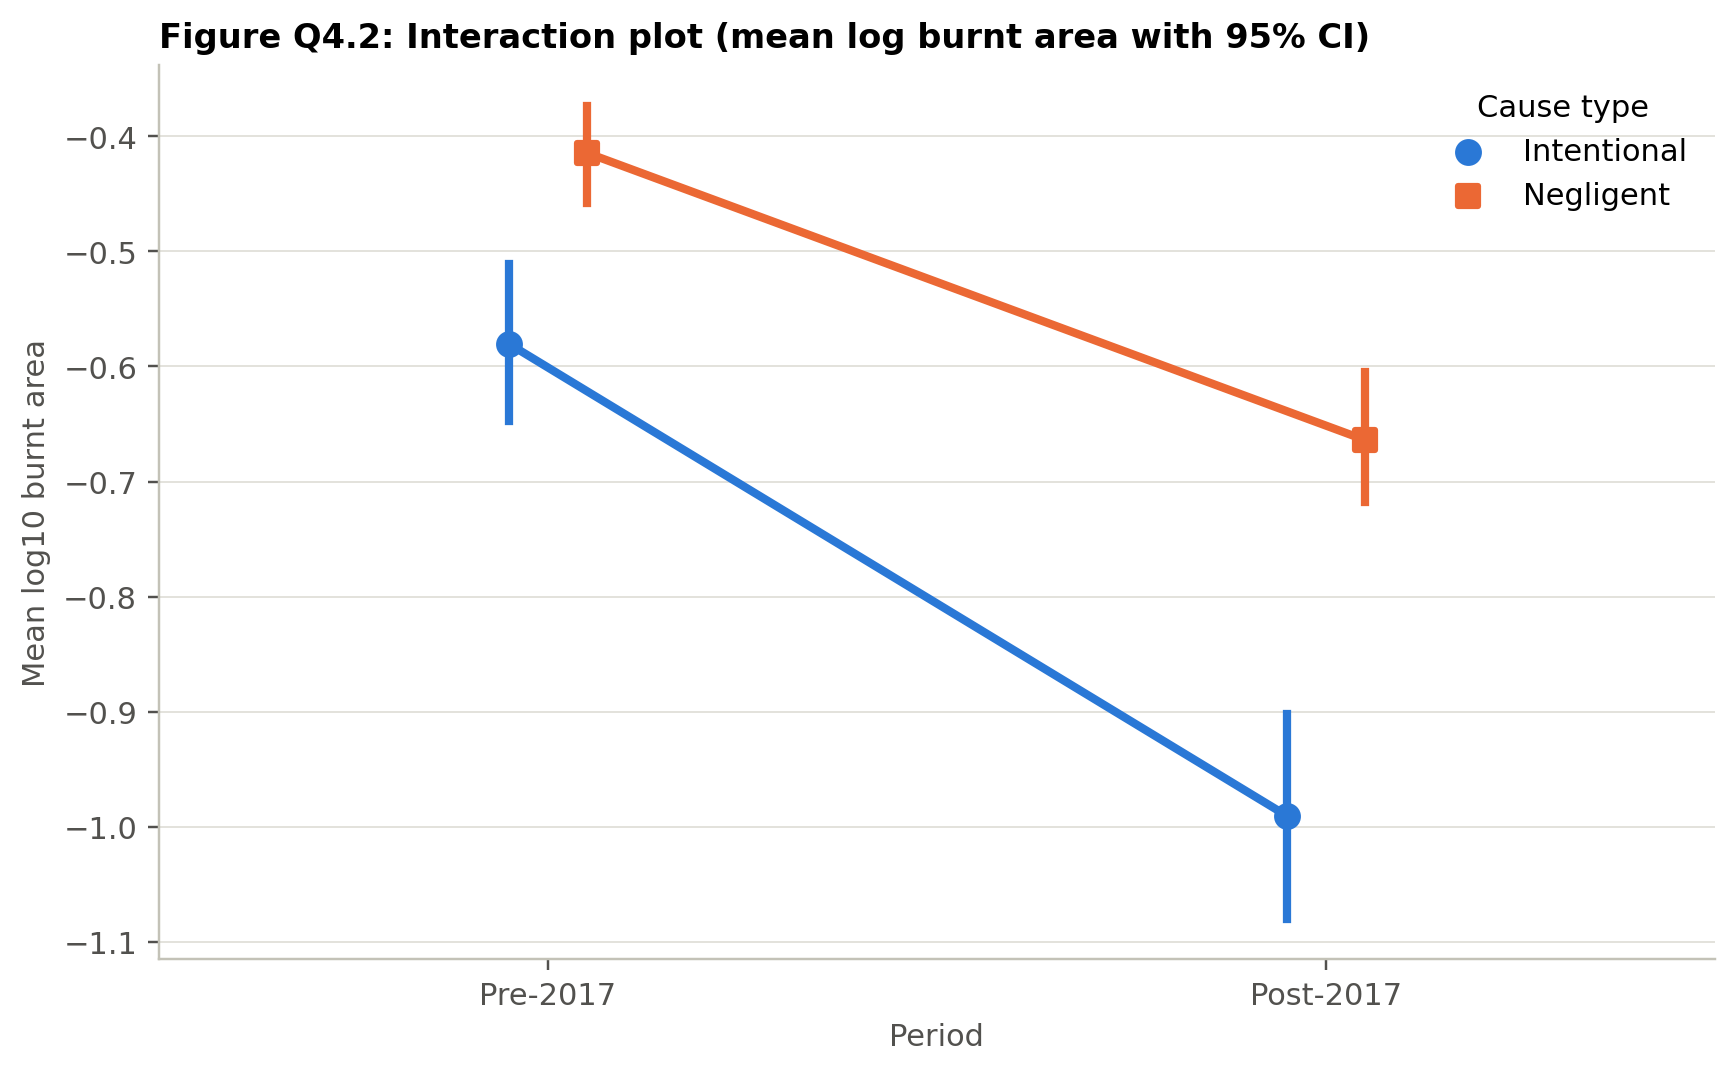

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.pointplot(data=q4, x="Period", y="Log_Total_Burnt_Area", hue="Cause_Type",
              order=PERIOD_ORDER, hue_order=CAUSE_ORDER, palette=PAL_CAUSE,
              errorbar=("ci", 95), dodge=0.1, markers=["o", "s"], ax=ax)
ax.set_title("Figure Q4.2: Interaction plot (mean log burnt area with 95% CI)")
ax.set_ylabel("Mean log10 burnt area")
ax.set_xlabel("Period")
ax.legend(title="Cause type")
plt.tight_layout()
plt.show()

In [29]:
# Numbers behind Figure Q4.2
q4_means = (
    q4.groupby(["Period", "Cause_Type"], observed=True)["Log_Total_Burnt_Area"]
      .agg(n="size", mean="mean", sd="std")
)
q4_means["se"] = q4_means["sd"] / np.sqrt(q4_means["n"])
t_crit_q4 = stats.t.ppf(0.975, q4_means["n"] - 1)
q4_means["ci_low"] = q4_means["mean"] - t_crit_q4 * q4_means["se"]
q4_means["ci_high"] = q4_means["mean"] + t_crit_q4 * q4_means["se"]
display(q4_means.round(3))

mean_tab = q4_means["mean"].unstack()
drop = mean_tab.loc["Pre-2017"] - mean_tab.loc["Post-2017"]
gap = mean_tab["Negligent"] - mean_tab["Intentional"]
print("Drop after 2017 (log units):")
print(drop.round(3))
print("\nGap Negligent - Intentional (log units):")
print(gap.round(3))
print(f"\nChange in the gap: {gap['Post-2017'] - gap['Pre-2017']:.3f}")

n   mean     sd     se  ci_low  ci_high
Period    Cause_Type                                             
Pre-2017  Intentional  1381 -0.580  1.272  0.034  -0.647   -0.513
          Negligent    2651 -0.414  1.149  0.022  -0.458   -0.371
Post-2017 Intentional   789 -0.991  1.281  0.046  -1.080   -0.901
          Negligent    1695 -0.664  1.221  0.030  -0.722   -0.606

Drop after 2017 (log units):
Cause_Type
Intentional    0.41
Negligent      0.25
dtype: float64

Gap Negligent - Intentional (log units):
Period
Pre-2017     0.166
Post-2017    0.327
dtype: float64

Change in the gap: 0.161


Figure Q4.2 is the most direct visual answer to the research question. If the gap between causes had narrowed after 2017, the two lines would converge. Instead, they move slightly apart. The mean for intentional fires drops by 0.41 log units (from -0.58 to -0.99), while the mean for negligent fires drops by 0.25 (from -0.41 to -0.66). As a result, the gap between causes goes from 0.17 to 0.33 log units, an increase of 0.16.

#### Summary

The descriptive analysis suggests that the gap between causes did not narrow after 2017. In both periods, the typical negligent fire burnt a larger area than the typical intentional fire, and all groups had smaller fires after 2017. Intentional fires decreased more, so the two lines in Figure Q4.2 move slightly apart. Whether these differences are statistically significant is tested in Section 4.4.

---

## 4) Draw Inferences

### 4.1 Q1: Z-test for Proportions and Chi-square Tests

To determine if the change post-2017 was concentrated in the critical period (1 June to 30 September) or also affected the traditional months, we ran a two-proportion Z-test separately for the Critical and Non-Critical periods.

If the reduction in negligent causes was concentrated in the critical period, we would expect a significant drop in the Critical period and no significant change (or an increase) in the Non-Critical period.

The Z-tests are followed by chi-square tests that compare the two seasons directly.

#### Terminology

* **$p_1$**: The proportion of negligent fires in the Pre-2017 period.
* **$p_2$**: The proportion of negligent fires in the Post-2017 period.
* **$n_1$**: The total number of human-caused fires in the Pre-2017 period.
* **$n_2$**: The total number of human-caused fires in the Post-2017 period.
* **$\alpha$**: The significance level, set at 0.05.

#### Hypotheses

* **$H_0$**: $p_1 = p_2$ (the proportion of negligent fires is the same before and after 2017).
* **$H_1$**: $p_1 \neq p_2$ (the proportion of negligent fires changed after 2017).

#### Methodology

The number of **negligent fires** is the number of successes. The total number of human-caused fires is the sample size for each period and season.

We use a two-proportion Z-test for each season separately:

* **Critical Period:** Pre-2017 ($n_1 = 2531$) vs. Post-2017 ($n_2 = 1215$).
* **Non-Critical Period:** Pre-2017 ($n_1 = 1503$) vs. Post-2017 ($n_2 = 1270$).

#### Checking the assumptions

1. **Independence:** The fires are independent observations.
2. **Large sample size:** The smallest cell count is 576 (Post-2017 Critical Negligent).

#### Z statistic and p-value

The pre-2017 period covers 16 years and the post-2017 period 8, so raw counts are not directly comparable. The Z-test compares proportions, rather than raw counts. So we calculated the proportions for each data set.

**Calculating the sample proportions**

$$
\hat p_{pre} = \frac{x_{pre}}{n_{pre}}
\qquad
\hat p_{post} = \frac{x_{post}}{n_{post}}
$$

In [44]:
# Aggregated counts
counts = (
    q1.assign(Negligent=(q1["Cause_Type"] == "Negligent"))
      .groupby(["Season_Risk_Period", "Period"])["Negligent"]
      .agg(negligent="sum", total="size")
)

SEASON_KEYS = {"Critical": "Critical", "Non-Critical": "Non-critical"}

data = {
    key: {
        "pre_negligent":  int(counts.loc[(season, "Pre-2017"),  "negligent"]),
        "pre_total":      int(counts.loc[(season, "Pre-2017"),  "total"]),
        "post_negligent": int(counts.loc[(season, "Post-2017"), "negligent"]),
        "post_total":     int(counts.loc[(season, "Post-2017"), "total"]),
    }
    for season, key in SEASON_KEYS.items()
}

# checking if the four groups cover every fire
assert sum(v["pre_total"] + v["post_total"] for v in data.values()) == len(q1)

# Observed proportions
summary_rows = []

for season, values in data.items():
    p_pre = values["pre_negligent"] / values["pre_total"]
    p_post = values["post_negligent"] / values["post_total"]

    summary_rows.append({
        "Season": season,
        "Pre-2017 proportion": p_pre,
        "Post-2017 proportion": p_post,
        "Change (percentage points)": (p_post - p_pre) * 100
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,Season,Pre-2017 proportion,Post-2017 proportion,Change (percentage points)
0,Critical,0.557487,0.474074,-8.341309
1,Non-critical,0.826347,0.881890,5.554246



The code below performs a **two-proportion z-test** using the following steps:

**Pooled proportion**

Under the null hypothesis, both periods have the same population proportion:

$$
\hat p = \frac{x_{pre} + x_{post}}{n_{pre} + n_{post}}
$$

**Standard error**

$$
SE = \sqrt{\hat p(1-\hat p)\left(\frac{1}{n_{pre}} + \frac{1}{n_{post}}\right)}
$$

**Z-statistic**

$$
Z = \frac{\hat p_{post} - \hat p_{pre}}{SE}
$$

The two-sided p-value is:

$$
p = 2\left[1 - \Phi(|Z|)\right]
$$

where $\Phi$ is the cumulative distribution function of the standard normal distribution.

In [31]:

def two_proportion_z_test(x_pre, n_pre, x_post, n_post):

    # Sample proportions
    p_pre = x_pre / n_pre
    p_post = x_post / n_post

    # Pooled proportion under H0: p_pre = p_post
    p_pooled = (x_pre + x_post) / (n_pre + n_post)

    # Pooled standard error
    standard_error = (
        p_pooled * (1 - p_pooled) *
        (1 / n_pre + 1 / n_post)
    ) ** 0.5

    # Z-statistic: post-2017 minus pre-2017
    z_stat = (p_post - p_pre) / standard_error

    # Two-sided p-value
    p_value = 2 * norm.sf(abs(z_stat))

    return {
        "Pre-2017 proportion": p_pre,
        "Post-2017 proportion": p_post,
        "Pooled proportion": p_pooled,
        "Standard error": standard_error,
        "Z-statistic": z_stat,
        "p-value": p_value
    }


# Run the test separately for each season
results = {}

for season, values in data.items():
    results[season] = two_proportion_z_test(
        x_pre=values["pre_negligent"],
        n_pre=values["pre_total"],
        x_post=values["post_negligent"],
        n_post=values["post_total"]
    )

results_df = pd.DataFrame(results).T
results_df

,Pre-2017 proportion,Post-2017 proportion,Pooled proportion,Standard error,Z-statistic,p-value
Critical,0.557487,0.474074,0.530432,0.017419,-4.788731,0.000002
Non-critical,0.826347,0.881890,0.851785,0.013543,4.101290,0.000041


In [32]:
alpha = 0.05

for season, result in results.items():
    print(f"--- {season} period ---")
    print(f"Z-statistic: {result['Z-statistic']:.4f}")
    print(f"p-value: {result['p-value']:.3e}")

    if result["p-value"] < alpha:
        print("Decision: Reject H0.")
        print("There is evidence that the proportion changed after 2017.")
    else:
        print("Decision: Fail to reject H0.")
        print("There is not enough evidence that the proportion changed.")

    print()

--- Critical period ---
Z-statistic: -4.7887
p-value: 1.678e-06
Decision: Reject H0.
There is evidence that the proportion changed after 2017.

--- Non-critical period ---
Z-statistic: 4.1013
p-value: 4.109e-05
Decision: Reject H0.
There is evidence that the proportion changed after 2017.



#### 4.1.2. Chi-square approach: was the change the same in both seasons?

The two Z-tests above show that the negligent share changed in each season, but they do not test the second half of Q1 directly: **was the change the same in the critical and in the non-critical months?** 

Two significant results (one down, one up) are not by themselves a test that the two changes differ. Chi-square methods on the 2 × 2 × 2 table (`Cause_Type` × `Period` × `Season_Risk_Period`) answer this.

The analysis has two parts:

1. **Chi-square test of independence** of `Cause_Type` and `Period` inside each season. For a 2 × 2 table without continuity correction, χ² = Z², so this reproduces the Z-tests and adds an **odds ratio** (OR) as effect size.

2. **Breslow-Day test of homogeneity of odds ratios** (χ², 1 df), the test of the interaction. H₀: the OR of Post-2017 vs Pre-2017 is the same in both seasons. A logistic regression with a `Period × Season` term is used as a cross-check and gives the **ratio of odds ratios**.

**Reading the odds ratio.** OR = odds of a fire being negligent after 2017 ÷ odds before 2017, where odds = negligent / intentional. OR < 1: negligent fires became relatively less common. OR > 1: more common.

#### Terminology and variables (chi-square tests)

**Variables** (all categorical, with two levels each):

* **`Cause_Type`**: Negligent or Intentional. This is the outcome of interest: a fire is a "success" when it is negligent.
* **`Period`**: Pre-2017 (2001–2016) or Post-2017 (2018–2025). The year 2017 is excluded as a transition year.
* **`Season_Risk_Period`**: Critical (1 June to 30 September) or Non-Critical (the other months). It is the stratifying variable: the analysis is done inside each season, and the two seasons are then compared.

**Unit of observation:** one human-caused fire (SGIF record) with a classified cause, in Chaves, Montalegre, Ourém and Tomar ($n = 6{,}519$).

**Notation.** For one season, the 2 × 2 table is laid out as follows (rows: period; columns: cause):

| | Negligent | Intentional |
|---|---|---|
| **Post-2017** | $a$ | $b$ |
| **Pre-2017** | $c$ | $d$ |

* **$n = a + b + c + d$**: the number of human-caused fires in the season.
* **$O_{ij}$ and $E_{ij}$**: the observed and the expected count of cell $(i, j)$ under independence.
* **$OR_s$**: the odds ratio of a fire being negligent, Post-2017 versus Pre-2017, in season $s$ (Critical or Non-Critical):

$$
OR_s = \frac{a / b}{c / d} = \frac{a\,d}{b\,c}
$$

* **$\alpha$**: the significance level, set at 0.05.

#### Chi-square test of independence inside each season

**Hypotheses** (tested separately inside each season $s$)

* **$H_0$**: `Cause_Type` and `Period` are independent in season $s$. The proportion of negligent fires is the same before and after 2017 ($p_1 = p_2$), which is equivalent to $OR_s = 1$.
* **$H_1$**: `Cause_Type` and `Period` are not independent in season $s$. The proportion of negligent fires changed after 2017 ($p_1 \neq p_2$), which is equivalent to $OR_s \neq 1$.

**Methodology**

We use Pearson's chi-square test of independence on the 2 × 2 table of each season, without continuity correction. Under $H_0$, the expected count of each cell is

$$
E_{ij} = \frac{(\text{row total}_i)\,(\text{column total}_j)}{n}
$$

and the test statistic is

$$
\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}
$$

which follows approximately a chi-square distribution with $(2-1)(2-1) = 1$ degree of freedom under $H_0$. We reject $H_0$ when $p < \alpha = 0.05$.

For a 2 × 2 table without continuity correction, $\chi^2 = Z^2$, so this test gives the same p-value as the two-sided Z-test of the previous section. What it adds is the **odds ratio** as an effect size, with a 95% confidence interval based on the normal approximation for $\ln(OR)$:

$$
\exp\left( \ln \widehat{OR} \pm 1.96 \sqrt{\frac{1}{a} + \frac{1}{b} + \frac{1}{c} + \frac{1}{d}} \right)
$$

Two tests are run, one per season, each for its own hypothesis. Both p-values are far below $0.05 / 2 = 0.025$, so a Bonferroni correction would not change the decisions.

**Checking the assumptions**

1. **Independence:** as in the Z-test, the fires are treated as independent observations. Fires in the same year or on the same day share weather conditions, so some clustering is possible. This cannot be tested with these data and, if present, would make the p-values somewhat too small (see the limitations in Section 6).
2. **Expected counts:** all expected counts must be at least 5. The smallest expected count is 188 (see the `min expected count` column below), so the chi-square approximation is reliable.

In [45]:
q1_chi = q1.copy()
ROWS_PP = ["Post-2017", "Pre-2017"]
COLS_NI = ["Negligent", "Intentional"]       


def table_pp(sub):
    """2 x 2 table: rows = Period (Post, Pre), columns = Cause_Type (Negligent, Intentional)."""
    return (pd.crosstab(sub["Period"], sub["Cause_Type"])
              .reindex(index=ROWS_PP, columns=COLS_NI, fill_value=0))


season_tables = {s: table_pp(q1_chi[q1_chi["Season_Risk_Period"] == s]) for s in SEASON_ORDER}

# the tables must reproduce the counts used in the Z-tests above
assert season_tables["Critical"].loc["Pre-2017", "Negligent"] == data["Critical"]["pre_negligent"]
assert season_tables["Critical"].loc["Post-2017"].sum() == data["Critical"]["post_total"]
assert season_tables["Non-Critical"].loc["Pre-2017", "Negligent"] == data["Non-critical"]["pre_negligent"]
assert season_tables["Non-Critical"].loc["Post-2017"].sum() == data["Non-critical"]["post_total"]

rows_chi = []
for s, t in season_tables.items():
    chi2, p, dof, expected = stats.chi2_contingency(t.values, correction=False)
    t22 = Table2x2(t.values)
    lo, hi = t22.oddsratio_confint()
    rows_chi.append({"Season": s, "chi2 (1 df)": chi2, "p-value": p,
                     "min expected count": expected.min(),
                     "OR (Post / Pre)": t22.oddsratio, "95% CI low": lo, "95% CI high": hi})
chi_season = pd.DataFrame(rows_chi).set_index("Season")
display(chi_season.round(8))

# consistency with the Z-tests (chi2 = Z^2)
for s, key in [("Critical", "Critical"), ("Non-Critical", "Non-critical")]:
    assert np.isclose(chi_season.loc[s, "chi2 (1 df)"], results[key]["Z-statistic"] ** 2), "chi2 differs from Z^2"
print("chi2 equals Z^2 in both seasons: the chi-square test reproduces the Z-tests.")

,chi2 (1 df),p-value,min expected count,OR (Post / Pre),95% CI low,95% CI high
Season,,,,,,
Critical,22.931943,0.000002,570.524560,0.715505,0.623753,0.820753
Non-Critical,16.820583,0.000041,188.232961,1.569082,1.263696,1.948269


chi2 equals Z^2 in both seasons: the chi-square test reproduces the Z-tests.


In the critical period, χ²(1) = 22.93, p < 0.001, OR = 0.72 (95% CI 0.62 to 0.82): the odds of a fire being negligent were about 28% lower after 2017. In the non-critical period, χ²(1) = 16.82, p < 0.001, OR = 1.57 (95% CI 1.26 to 1.95): the odds were about 57% higher. These are the same tests as the Z-tests (χ² = Z²), now with an effect size.

#### Do the odds ratios differ between seasons?

Testing the interaction between seasons

**Hypotheses**

* **$H_0$**: $OR_{Critical} = OR_{Non\text{-}Critical}$. The change in the odds of a fire being negligent after 2017 is the same in both seasons (no `Period × Season_Risk_Period` interaction).
* **$H_1$**: $OR_{Critical} \neq OR_{Non\text{-}Critical}$. The change in the odds of a fire being negligent after 2017 differs between seasons.

Equivalently, $H_0$ states that the ratio of odds ratios $OR_{Non\text{-}Critical} / OR_{Critical}$ equals 1.

**Methodology**

The question is answered with two complementary tests, both based on the chi-square distribution.

1. **Breslow-Day test of homogeneity of odds ratios (with Tarone's adjustment).** The two seasons are the $K = 2$ strata, each with its own 2 × 2 table. A common odds ratio $\widehat{OR}_{MH}$ is first estimated with the Mantel-Haenszel method. Then, in each season $k$, the expected count $\hat a_k$ of the top-left cell (Post-2017 and Negligent) is computed from the margins of the table and the common odds ratio. The statistic compares it with the observed count $a_k$:

$$
X^2_{BD} = \sum_{k=1}^{K} \frac{(a_k - \hat a_k)^2}{\widehat{\operatorname{Var}}(a_k)}
$$

Tarone's adjustment subtracts $\left(\sum_k a_k - \sum_k \hat a_k\right)^2 / \sum_k \widehat{\operatorname{Var}}(a_k)$, which corrects for the fact that the common odds ratio was estimated from the same data. Under $H_0$, the statistic follows approximately a chi-square distribution with $K - 1 = 1$ degree of freedom.

2. **Logistic regression with an interaction (cross-check).** The model is

$$
\ln\frac{P(\text{negligent})}{1 - P(\text{negligent})} = \beta_0 + \beta_1\,\text{Post} + \beta_2\,\text{NonCritical} + \beta_3\,(\text{Post} \times \text{NonCritical})
$$

with Pre-2017 and Critical as reference levels. Then $e^{\beta_1} = OR_{Critical}$ and $e^{\beta_1 + \beta_3} = OR_{Non\text{-}Critical}$, so $e^{\beta_3}$ is the **ratio of odds ratios** (Non-Critical / Critical). The hypothesis $H_0: \beta_3 = 0$ is tested with a likelihood-ratio test that compares the model with and without the interaction:

$$
LR = 2\,(\ell_{full} - \ell_{reduced}) \sim \chi^2_1 \quad \text{under } H_0
$$

We reject $H_0$ when $p < \alpha = 0.05$.

**Checking the assumptions**

1. **Independence:** the same as for the previous tests (see above).
2. **Large sample size:** both tests are asymptotic. All eight cells of the 2 × 2 × 2 table have at least 150 fires (the smallest is Post-2017, Non-Critical, Intentional, with 150), so the approximations are reliable.

In [46]:
strat_season = StratifiedTable([season_tables[s].values.astype(float) for s in SEASON_ORDER])
bd_season = strat_season.test_equal_odds(adjust=True)      # Breslow-Day with Tarone's adjustment
print("Breslow-Day (Tarone) test of equal odds ratios in the two seasons:")
print(f"  chi2(1) = {bd_season.statistic:.3f}, p = {bd_season.pvalue:.3e}")

# Cross-check: logistic regression with a Period x Season interaction (likelihood-ratio test)
q1_chi["Negligent"] = (q1_chi["Cause_Type"] == "Negligent").astype(int)
f_full = smf.logit("Negligent ~ C(Period, Treatment('Pre-2017')) * C(Season_Risk_Period, Treatment('Critical'))",
                   data=q1_chi).fit(disp=0)
f_red = smf.logit("Negligent ~ C(Period, Treatment('Pre-2017')) + C(Season_Risk_Period, Treatment('Critical'))",
                  data=q1_chi).fit(disp=0)
lr_stat = 2 * (f_full.llf - f_red.llf)
lr_p = stats.chi2.sf(lr_stat, 1)
inter_name = f_full.params.index[-1]                        # the Period x Season term
ror = np.exp(f_full.params[inter_name])
ror_lo, ror_hi = np.exp(f_full.conf_int().loc[inter_name])
print(f"Logistic regression, likelihood-ratio test of the interaction: chi2(1) = {lr_stat:.3f}, p = {lr_p:.3e}")
print(f"Ratio of odds ratios (Non-Critical / Critical) = {ror:.2f} (95% CI {ror_lo:.2f} to {ror_hi:.2f})")
print(f"OR Critical = {chi_season.loc['Critical', 'OR (Post / Pre)']:.2f}, "
      f"OR Non-Critical = {chi_season.loc['Non-Critical', 'OR (Post / Pre)']:.2f}")

Breslow-Day (Tarone) test of equal odds ratios in the two seasons:
  chi2(1) = 36.502, p = 1.525e-09
Logistic regression, likelihood-ratio test of the interaction: chi2(1) = 36.835, p = 1.286e-09
Ratio of odds ratios (Non-Critical / Critical) = 2.19 (95% CI 1.70 to 2.83)
OR Critical = 0.72, OR Non-Critical = 1.57


**The Breslow-Day test** rejects equal odds ratios (χ²(1) = 36.50, p < 0.001), and the likelihood-ratio test of the `Period × Season` interaction agrees (χ²(1) = 36.83, p < 0.001). 

The ratio of odds ratios (Non-Critical / Critical) is 2.19 (95% CI 1.70 to 2.83). So the change after 2017 **was not the same** in both seasons: it went in opposite directions, and the difference between the two changes is itself statistically significant.

The interaction is measured on the odds-ratio (multiplicative) scale. On the proportion scale used in the Z-tests, the same pattern appears as −8.3 percentage points in the critical period and +5.6 points in the non-critical period.

---

### 4.2 Q2: Welch's Two-Sample t-test

We aim to test whether the mean number of daily negligent ignitions differs significantly between weekends and weekdays in the post-2017 period.

#### Terminology

- **$\mu_{\text{Weekend}}$**: Population mean number of daily negligent ignitions on active weekend days in the post-2017 period ($n_1 = 337$).
- **$\mu_{\text{Weekday}}$**: Population mean number of daily negligent ignitions on active weekdays in the post-2017 period ($n_2 = 802$).
- **$\alpha$**: The significance level, set at 0.05.

#### Hypotheses

- **$H_0$**: $\mu_{\text{Weekend}} - \mu_{\text{Weekday}} = 0$ (there is no difference in the population mean daily negligent ignitions between weekends and weekdays).
- **$H_1$**: $\mu_{\text{Weekend}} - \mu_{\text{Weekday}} \neq 0$ (two-sided: the population mean daily negligent ignitions differ between weekends and weekdays).

#### Checking the assumptions

A two-sample $t$-test requires three conditions:

1. **Independence:** Each observation represents a distinct municipal active fire day (`Concelho` $\times$ `Date`). While synoptic weather conditions can induce spatial/temporal clustering (discussed in the limitations in Section 6), observations across weekdays and weekends are treated as independent samples.
2. **Normality:** Assessed below via histograms, normal Q-Q plots, skewness, excess kurtosis, and the Shapiro-Wilk test within each group. Because daily ignition counts are discrete and strongly right-skewed ($Y \ge 1$, skewness $\approx 4$, excess kurtosis $\approx 20$), normality of the raw observations is clearly rejected ($p < 0.001$ in both groups). However, given the large sample sizes ($n_{\text{Weekend}} = 337 \ge 30$ and $n_{\text{Weekday}} = 802 \ge 30$), the sampling distribution of the sample means is **approximately normal by the Central Limit Theorem (CLT)**, although the strong positive skewness may slow the rate of convergence.
3. **Homoscedasticity (equal variances):** Evaluated via the sample variance ratio and both mean-centred (Levene) and median-centred (Brown-Forsythe) tests. Notice that the two tests may disagree because mean-centred Levene is sensitive to the heavy right tail ($p < 0.05$), whereas median-centred Brown-Forsythe is more robust to skewness ($p > 0.05$). Regardless of whether equal variances hold, **Welch's two-sample $t$-test** (`equal_var=False`) is used as the primary parametric test because it adjusts the degrees of freedom (Welch-Satterthwaite) and remains valid in both cases.

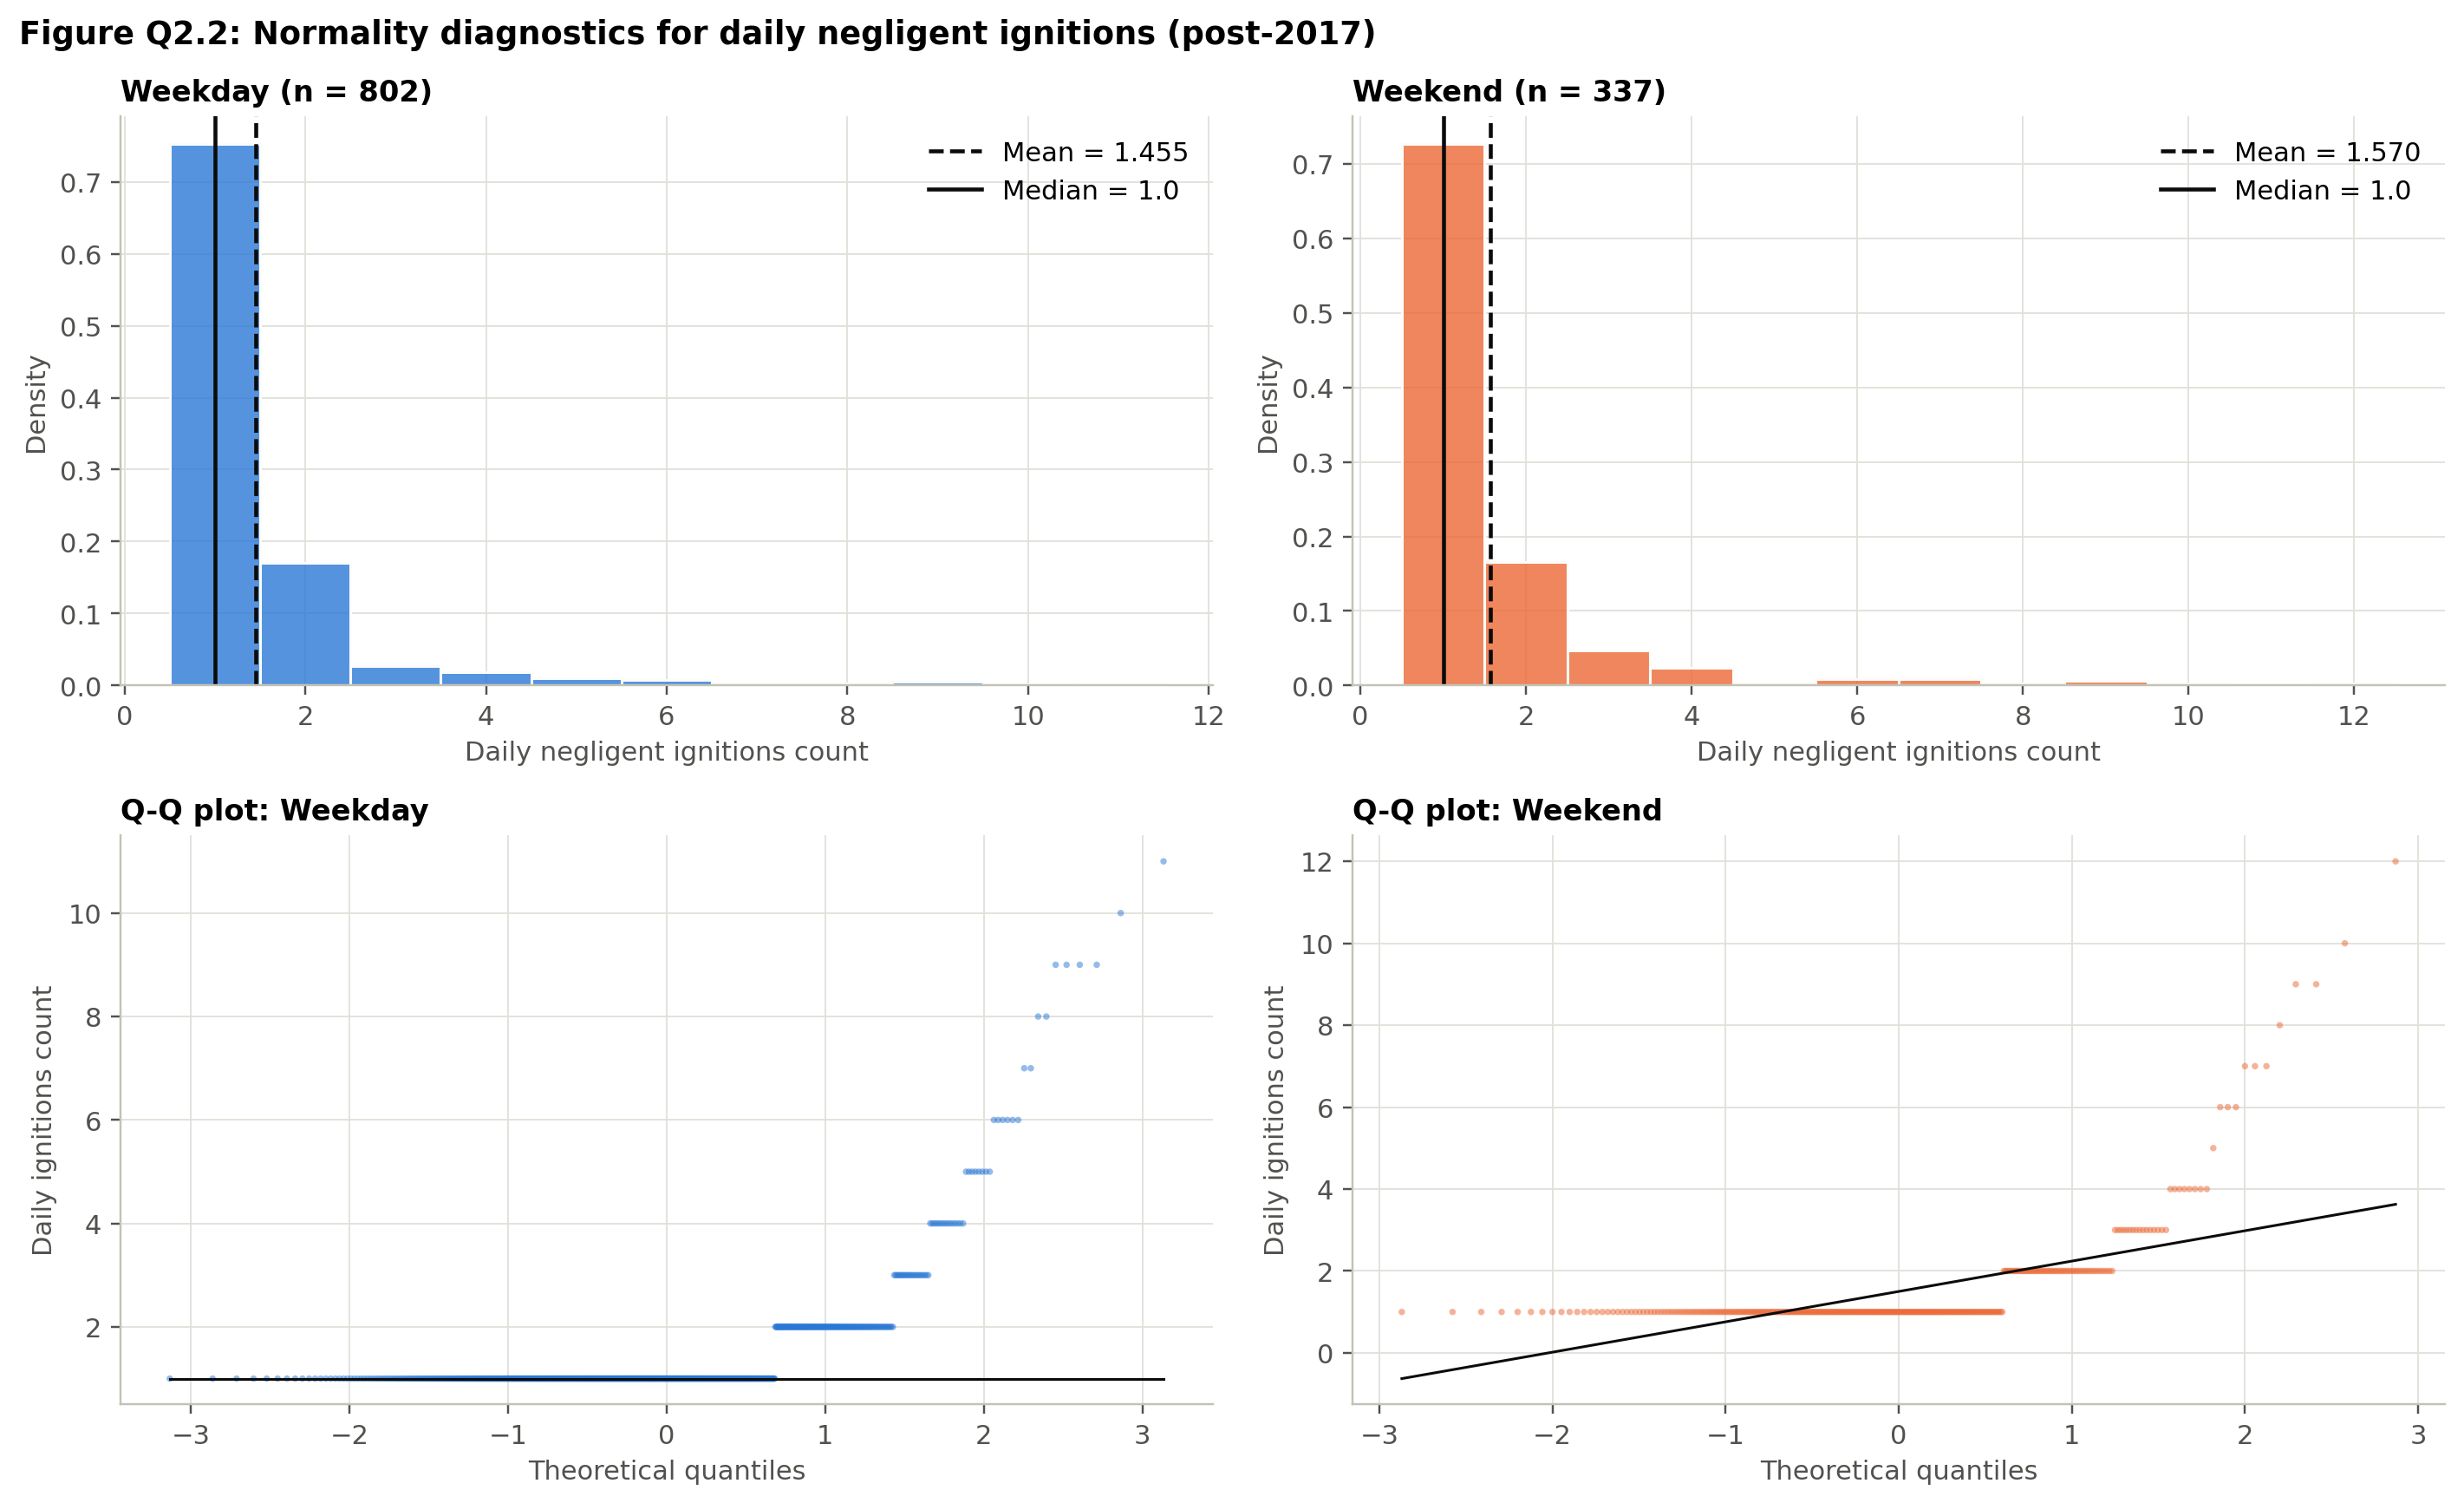

Normality and CLT diagnostics:


,Group (Post-2017),n,Mean,SD,Variance,Skewness,Excess_Kurtosis,Shapiro_W,Shapiro_p,CLT_Applies (n >= 30)
0,Weekday,802,1.4551,1.1606,1.3469,4.2565,22.3345,0.4379,< 0.001,True
1,Weekend,337,1.5697,1.4022,1.9661,4.0247,19.3698,0.4568,< 0.001,True



Homoscedasticity (equality of variances):
Variance ratio (max / min): 1.460 (SD ratio: 1.208)
Levene (centre = mean)           : W = 4.8690, p = 0.0275
Brown-Forsythe (centre = median) : W = 2.0377, p = 0.1537
Note: the two tests can disagree because of the strong right-skewness; Welch's t-test (equal_var=False) remains valid in both cases.


In [39]:
# Post-2017 subset
post_data = q2[q2["Period"] == "Post-2017"].copy()

weekday_post = post_data[post_data["Day_Type"] == "Weekday"]["Daily_Ignitions_Count"]
weekend_post = post_data[post_data["Day_Type"] == "Weekend"]["Daily_Ignitions_Count"]

# 1. Visual check of normality: histograms + Q-Q plots (post-2017)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
groups_post = [("Weekday", weekday_post), ("Weekend", weekend_post)]

for i, (label, serie) in enumerate(groups_post):
    color = PAL_DAY[label]
    # histogram (top row)
    sns.histplot(serie, discrete=True, stat="density", color=color, alpha=0.8, edgecolor=SURFACE, ax=axes[0, i])
    axes[0, i].axvline(serie.mean(), color=INK, linestyle="--", linewidth=1.5, label=f"Mean = {serie.mean():.3f}")
    axes[0, i].axvline(serie.median(), color=INK, linestyle="-", linewidth=1.5, label=f"Median = {serie.median():.1f}")
    axes[0, i].set_title(f"{label} (n = {len(serie)})")
    axes[0, i].set_xlabel("Daily negligent ignitions count")
    axes[0, i].set_ylabel("Density")
    axes[0, i].legend()

    # normal Q-Q plot (bottom row)
    qq_panel(axes[1, i], serie, color, f"Q-Q plot: {label}", ylabel="Daily ignitions count")

fig_title(fig, "Figure Q2.2: Normality diagnostics for daily negligent ignitions (post-2017)")
plt.tight_layout()
plt.show()

# 2. Normality summary (skewness, kurtosis and Shapiro-Wilk)
norm_rows = []
for label, serie in groups_post:
    sw_stat, sw_p = stats.shapiro(serie)
    norm_rows.append({
        "Group (Post-2017)": label,
        "n": len(serie),
        "Mean": round(serie.mean(), 4),
        "SD": round(serie.std(ddof=1), 4),
        "Variance": round(serie.var(ddof=1), 4),
        "Skewness": round(stats.skew(serie), 4),
        "Excess_Kurtosis": round(stats.kurtosis(serie), 4),
        "Shapiro_W": round(sw_stat, 4),
        "Shapiro_p": "< 0.001" if sw_p < 0.001 else f"{sw_p:.4f}",
        "CLT_Applies (n >= 30)": len(serie) >= 30
    })

norm_df = pd.DataFrame(norm_rows)
print("Normality and CLT diagnostics:")
display(norm_df)

# 3. Equal variances: Levene (mean) vs Brown-Forsythe (median)
levene_stat, levene_p = stats.levene(weekday_post, weekend_post, center="mean")
bf_stat, bf_p = stats.levene(weekday_post, weekend_post, center="median")
var_ratio = max(weekend_post.var(ddof=1), weekday_post.var(ddof=1)) / min(weekend_post.var(ddof=1), weekday_post.var(ddof=1))

print("\nHomoscedasticity (equality of variances):")
print(f"Variance ratio (max / min): {var_ratio:.3f} (SD ratio: {np.sqrt(var_ratio):.3f})")
print(f"Levene (centre = mean)           : W = {levene_stat:.4f}, p = {levene_p:.4f}")
print(f"Brown-Forsythe (centre = median) : W = {bf_stat:.4f}, p = {bf_p:.4f}")
print("Note: the two tests can disagree because of the strong right-skewness; Welch's t-test (equal_var=False) remains valid in both cases.")

#### Welch's t-test

In [40]:
# Welch's t-test (equal_var=False)
t_stat, p_val = stats.ttest_ind(weekend_post, weekday_post, equal_var=False)

# Welch-Satterthwaite degrees of freedom
s1, s2 = np.var(weekend_post, ddof=1), np.var(weekday_post, ddof=1)
n1, n2 = len(weekend_post), len(weekday_post)
df_welch = ((s1 / n1 + s2 / n2) ** 2) / (
    ((s1 / n1) ** 2) / (n1 - 1) + ((s2 / n2) ** 2) / (n2 - 1)
)

# Critical value (two-sided, alpha = 0.05) and 95% confidence interval
alpha = 0.05
t_crit = stats.t.ppf(1 - alpha / 2, df=df_welch)
diff_mean = weekend_post.mean() - weekday_post.mean()
se_diff = np.sqrt(s1 / n1 + s2 / n2)
ci_low, ci_high = stats.t.interval(
    1 - alpha, df=df_welch, loc=diff_mean, scale=se_diff
)

print("Welch's two-sample t-test (post-2017):")
print(f"Mean Weekend: {weekend_post.mean():.3f} (SD = {weekend_post.std(ddof=1):.3f}, n = {n1})")
print(f"Mean Weekday: {weekday_post.mean():.3f} (SD = {weekday_post.std(ddof=1):.3f}, n = {n2})")
print(f"Difference in means (Weekend - Weekday): {diff_mean:.3f} (SE = {se_diff:.4f})")
print(f"Welch t-statistic (t_obs): {t_stat:.4f}")
print(f"Degrees of freedom (df): {df_welch:.2f}")
print(f"Critical value (t_crit, alpha = 0.05 two-sided): ±{t_crit:.4f}")
print(f"p-value: {p_val:.4f}")
print(f"95% confidence interval for the difference: [{ci_low:.3f}, {ci_high:.3f}]")
decision = "Reject H0" if p_val < alpha else "Fail to reject H0"
print(f"Decision: {decision} (|t_obs| = {abs(t_stat):.4f}, t_crit = {t_crit:.4f}, p = {p_val:.4f}, alpha = {alpha})")

Welch's two-sample t-test (post-2017):
Mean Weekend: 1.570 (SD = 1.402, n = 337)
Mean Weekday: 1.455 (SD = 1.161, n = 802)
Difference in means (Weekend - Weekday): 0.115 (SE = 0.0867)
Welch t-statistic (t_obs): 1.3223
Degrees of freedom (df): 538.57
Critical value (t_crit, alpha = 0.05 two-sided): ±1.9644
p-value: 0.1866
95% confidence interval for the difference: [-0.056, 0.285]
Decision: Fail to reject H0 (|t_obs| = 1.3223, t_crit = 1.9644, p = 0.1866, alpha = 0.05)


#### Robustness check: controlling for municipality

As shown in the table below, the four municipalities differ substantially in daily negligent ignition counts, with the weekend mean ranging from about $1.05$ ignitions/day in `Tomar` to $1.99$ ignitions/day in `Montalegre` (and the weekday mean ranging from $1.08$ in `Ourém` to $1.82$ in `Montalegre`). To verify that pooling the observations across `Chaves`, `Montalegre`, `Ourém` and `Tomar` does not mask a municipality-specific weekend effect (Simpson's paradox), we repeat Welch's two-sample $t$-test separately within each municipality and plot the 95% confidence intervals for the difference in means ($\mu_{\text{Weekend}} - \mu_{\text{Weekday}}$). Applying a Bonferroni correction across the $K = 4$ municipal tests ($\alpha_{\text{Bonf}} = 0.05 / 4 = 0.0125$) does not change the conclusion, as $p > 0.05$ in every municipality.

Welch's t-test by municipality (Bonferroni alpha = 0.05/4 = 0.0125):


,Municipality,n_Weekend,n_Weekday,Mean_Weekend,Mean_Weekday,Diff (Wknd - Wkdy),SE,t_stat,df,p_value,CI_95_low,CI_95_high,Alpha_Threshold,Significant
0,Chaves,84,181,1.3690,1.2376,0.1315,0.0808,1.6263,131.5094,0.1063,-0.0285,0.2914,0.0125,False
1,Montalegre,153,363,1.9935,1.8237,0.1698,0.1763,0.9629,243.8556,0.3365,-0.1775,0.5170,0.0125,False
2,Ourém,44,131,1.1364,1.0840,0.0524,0.0587,0.8923,66.6711,0.3754,-0.0648,0.1696,0.0125,False
3,Tomar,56,127,1.0536,1.0945,-0.0409,0.0487,-0.8396,112.7996,0.4029,-0.1375,0.0556,0.0125,False
4,All (pooled),337,802,1.5697,1.4551,0.1146,0.0867,1.3223,538.5686,0.1866,-0.0557,0.2849,0.0500,False


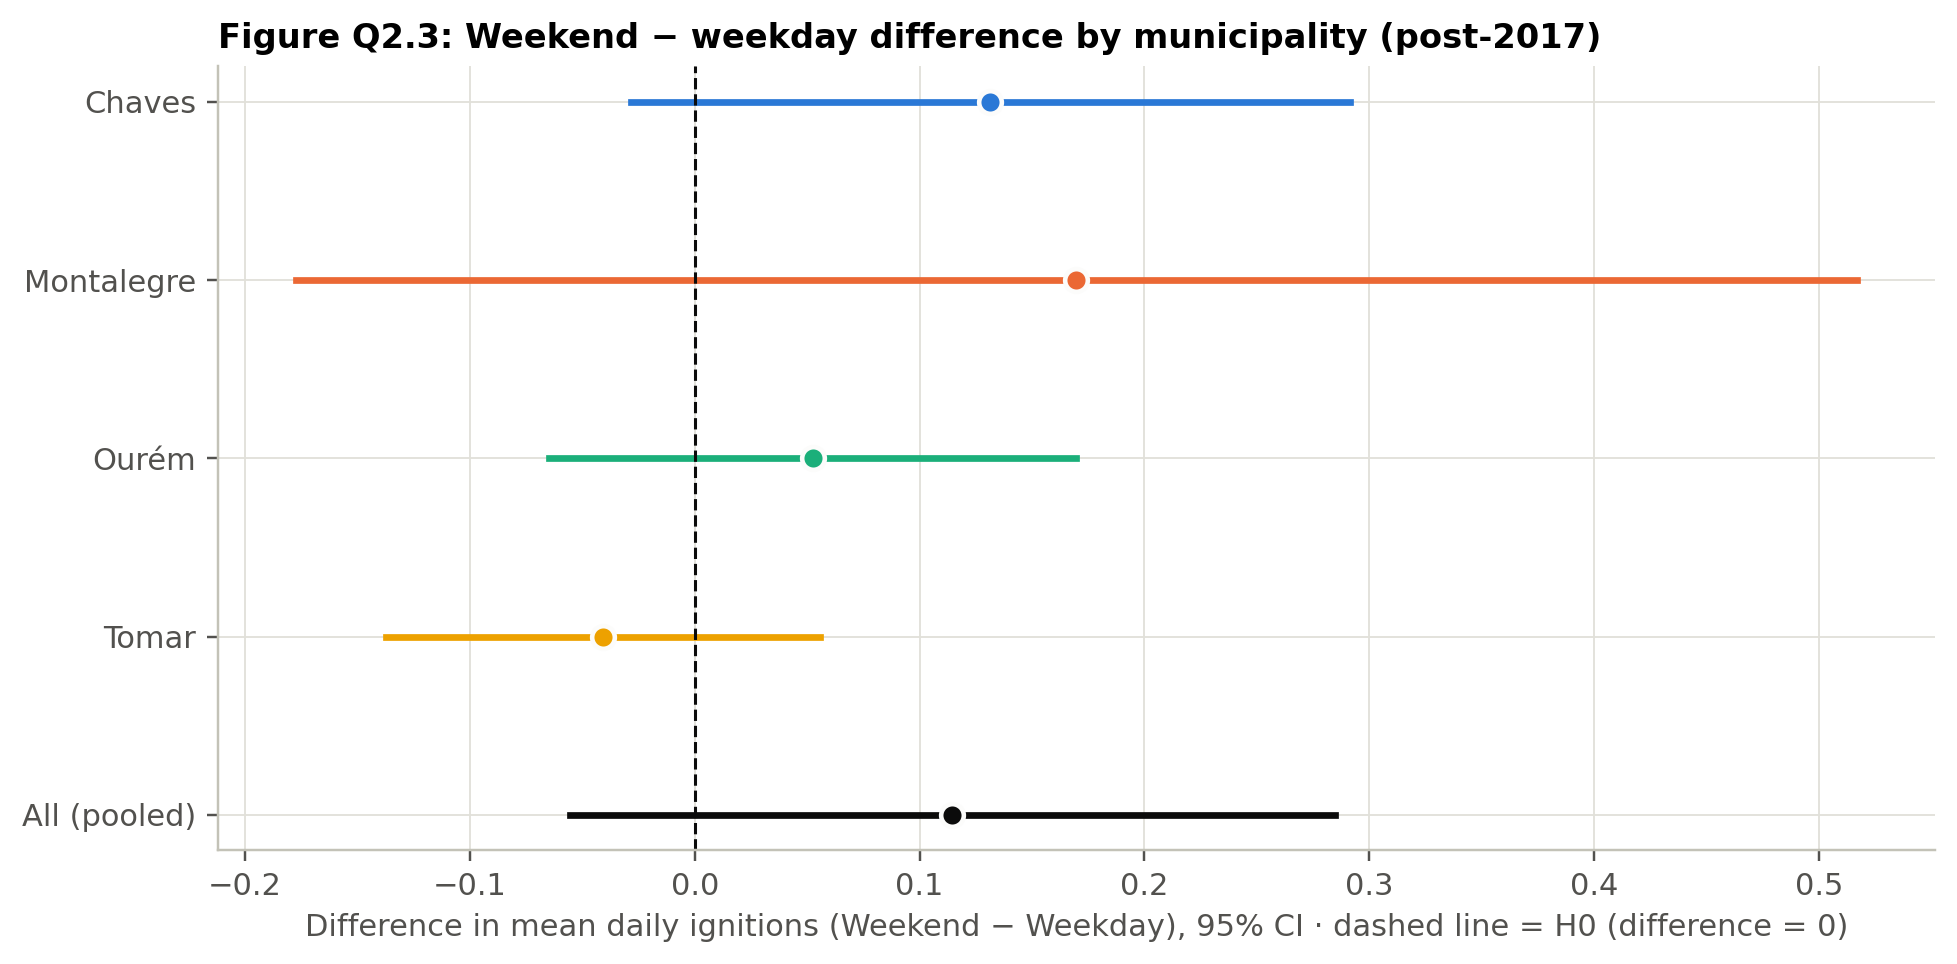

In [41]:
# Welch's t-test by municipality in the post-2017 period
alpha_bonf_mun = 0.05 / 4  # Bonferroni correction for 4 municipalities (0.0125)
mun_rows = []
for mun in MUNICIPALITIES:
    sub_m = post_data[post_data["Concelho"] == mun]
    wknd_m = sub_m[sub_m["Day_Type"] == "Weekend"]["Daily_Ignitions_Count"]
    wkdy_m = sub_m[sub_m["Day_Type"] == "Weekday"]["Daily_Ignitions_Count"]
    if len(wknd_m) >= 2 and len(wkdy_m) >= 2:
        t_m, p_m = stats.ttest_ind(wknd_m, wkdy_m, equal_var=False)
        v1_m, v2_m = wknd_m.var(ddof=1), wkdy_m.var(ddof=1)
        n1_m, n2_m = len(wknd_m), len(wkdy_m)
        se_m = np.sqrt(v1_m / n1_m + v2_m / n2_m)
        df_m = ((v1_m / n1_m + v2_m / n2_m) ** 2) / (((v1_m / n1_m) ** 2) / (n1_m - 1) + ((v2_m / n2_m) ** 2) / (n2_m - 1))
        diff_m = wknd_m.mean() - wkdy_m.mean()
        ci_l, ci_h = stats.t.interval(0.95, df=df_m, loc=diff_m, scale=se_m)
        mun_rows.append({
            "Municipality": mun,
            "n_Weekend": n1_m,
            "n_Weekday": n2_m,
            "Mean_Weekend": wknd_m.mean(),
            "Mean_Weekday": wkdy_m.mean(),
            "Diff (Wknd - Wkdy)": diff_m,
            "SE": se_m,
            "t_stat": t_m,
            "df": df_m,
            "p_value": p_m,
            "CI_95_low": ci_l,
            "CI_95_high": ci_h,
            "Alpha_Threshold": alpha_bonf_mun,
            "Significant": p_m < alpha_bonf_mun
        })

# Pooled row (all municipalities, post-2017) for visual comparison
mun_rows.append({
    "Municipality": "All (pooled)",
    "n_Weekend": n1,
    "n_Weekday": n2,
    "Mean_Weekend": weekend_post.mean(),
    "Mean_Weekday": weekday_post.mean(),
    "Diff (Wknd - Wkdy)": diff_mean,
    "SE": se_diff,
    "t_stat": t_stat,
    "df": df_welch,
    "p_value": p_val,
    "CI_95_low": ci_low,
    "CI_95_high": ci_high,
    "Alpha_Threshold": 0.05,
    "Significant": p_val < 0.05
})

mun_df = pd.DataFrame(mun_rows)
print(f"Welch's t-test by municipality (Bonferroni alpha = 0.05/4 = {alpha_bonf_mun:.4f}):")
display(mun_df.round(4))

# Forest plot of the 95% confidence intervals for (mu_Weekend - mu_Weekday)
fig, ax = plt.subplots(figsize=(9, 4.5))
y_pos = np.arange(len(mun_df))

for idx, row in mun_df.iterrows():
    col = INK if row["Municipality"] == "All (pooled)" else PAL_MUN[row["Municipality"]]
    ax.plot([row["CI_95_low"], row["CI_95_high"]], [idx, idx], color=col, linewidth=2.2)
    ax.scatter(row["Diff (Wknd - Wkdy)"], idx, s=55, color=col, zorder=3, edgecolor=SURFACE, linewidth=1.5)

ax.axvline(0, color=INK, linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(mun_df["Municipality"])
ax.invert_yaxis()
ax.set_xlabel("Difference in mean daily ignitions (Weekend − Weekday), 95% CI · dashed line = H0 (difference = 0)")
ax.set_title("Figure Q2.3: Weekend − weekday difference by municipality (post-2017)")
plt.tight_layout()
plt.show()

#### Complementary comparison: weekends before and after 2017

In [42]:
# Did the weekend mean change from pre-2017 to post-2017?
weekend_pre = q2[
    (q2["Period"] == "Pre-2017") & (q2["Day_Type"] == "Weekend")
]["Daily_Ignitions_Count"]

t_stat_evol, p_val_evol = stats.ttest_ind(
    weekend_pre, weekend_post, equal_var=False
)
print("Welch's t-test: weekends pre-2017 vs post-2017")
print(
    f"Mean Weekend Pre-2017: {weekend_pre.mean():.3f} vs Post-2017: {weekend_post.mean():.3f}"
)
print(f"t-statistic: {t_stat_evol:.4f}, p-value: {p_val_evol:.4f}")

Welch's t-test: weekends pre-2017 vs post-2017
Mean Weekend Pre-2017: 1.519 vs Post-2017: 1.570
t-statistic: -0.5662, p-value: 0.5715


---

### 4.3 Q3: One-way ANOVA

#### Hypotheses

- **H₀:** μ_Chaves = μ_Montalegre = μ_Ourém = μ_Tomar, where μ is the population mean of ln(burnt area).
- **H₁:** at least one of these means differs.

The records cover all fires registered in SGIF for these municipalities and years. They are treated as realisations of the fire-generating process in each municipality, so the tests refer to that process rather than to sampling from a finite list of records.

#### ANOVA assumptions and choice of scale

The one-way ANOVA model is yᵢⱼ = μᵢ + εᵢⱼ, with errors that are **independent**, **normal** and of **equal variance** in all groups. Normality and equal variances are checked on the residuals eᵢⱼ = yᵢⱼ − ȳᵢ.

**Independence** cannot be tested from these records; it depends on how the fires arise. Fires in the same municipality and season share weather, fuel and land-use conditions, and reignition records may be related to earlier fires. This possible temporal and spatial clustering is not proof of dependence, but if present it would make the p-values somewhat too small. It is therefore treated as a limitation, and the robustness checks below repeat the test allowing fires on the same day to be correlated.

**Normality and equal variances** are compared on three response scales. With 418–1,146 fires per group, the Shapiro-Wilk, Levene and Brown-Forsythe (median-centred Levene) tests detect even small departures, so the size of the departures (skewness, kurtosis, variance ratio) and the Q-Q plot are given more weight than their p-values.

In [43]:
def diagnostics(samples):
    resid = np.concatenate([x - x.mean() for x in samples])
    var = np.array([x.var(ddof=1) for x in samples])
    return pd.Series({"n": len(resid),
                      "residual skewness": stats.skew(resid),
                      "residual excess kurtosis": stats.kurtosis(resid),
                      "max |skewness| within groups": max(abs(stats.skew(x)) for x in samples),
                      "max excess kurtosis within groups": max(stats.kurtosis(x) for x in samples),
                      "min Shapiro-Wilk W (groups)": min(stats.shapiro(x).statistic for x in samples),
                      "largest / smallest variance": var.max() / var.min(),
                      "Levene p (mean)": stats.levene(*samples, center="mean").pvalue,
                      "Brown-Forsythe p (median)": stats.levene(*samples, center="median").pvalue})

raw_groups = [q3.loc[q3["Concelho"] == m, Y].to_numpy() for m in MUNICIPALITIES]
ln_groups = [q3_ln.loc[q3_ln["Concelho"] == m, "ln_area"].to_numpy() for m in MUNICIPALITIES]
diag = pd.DataFrame({"original (ha)": diagnostics(raw_groups),
                     "log(1 + area)": diagnostics([np.log1p(x) for x in raw_groups]),
                     "ln(area)": diagnostics(ln_groups)})
display(diag.map(lambda v: f"{v:.4g}"))
print("SD of ln(area) by municipality:", {m: round(float(x.std(ddof=1)), 3) for m, x in zip(MUNICIPALITIES, ln_groups)})

AttributeError: 'DataFrame' object has no attribute 'map'

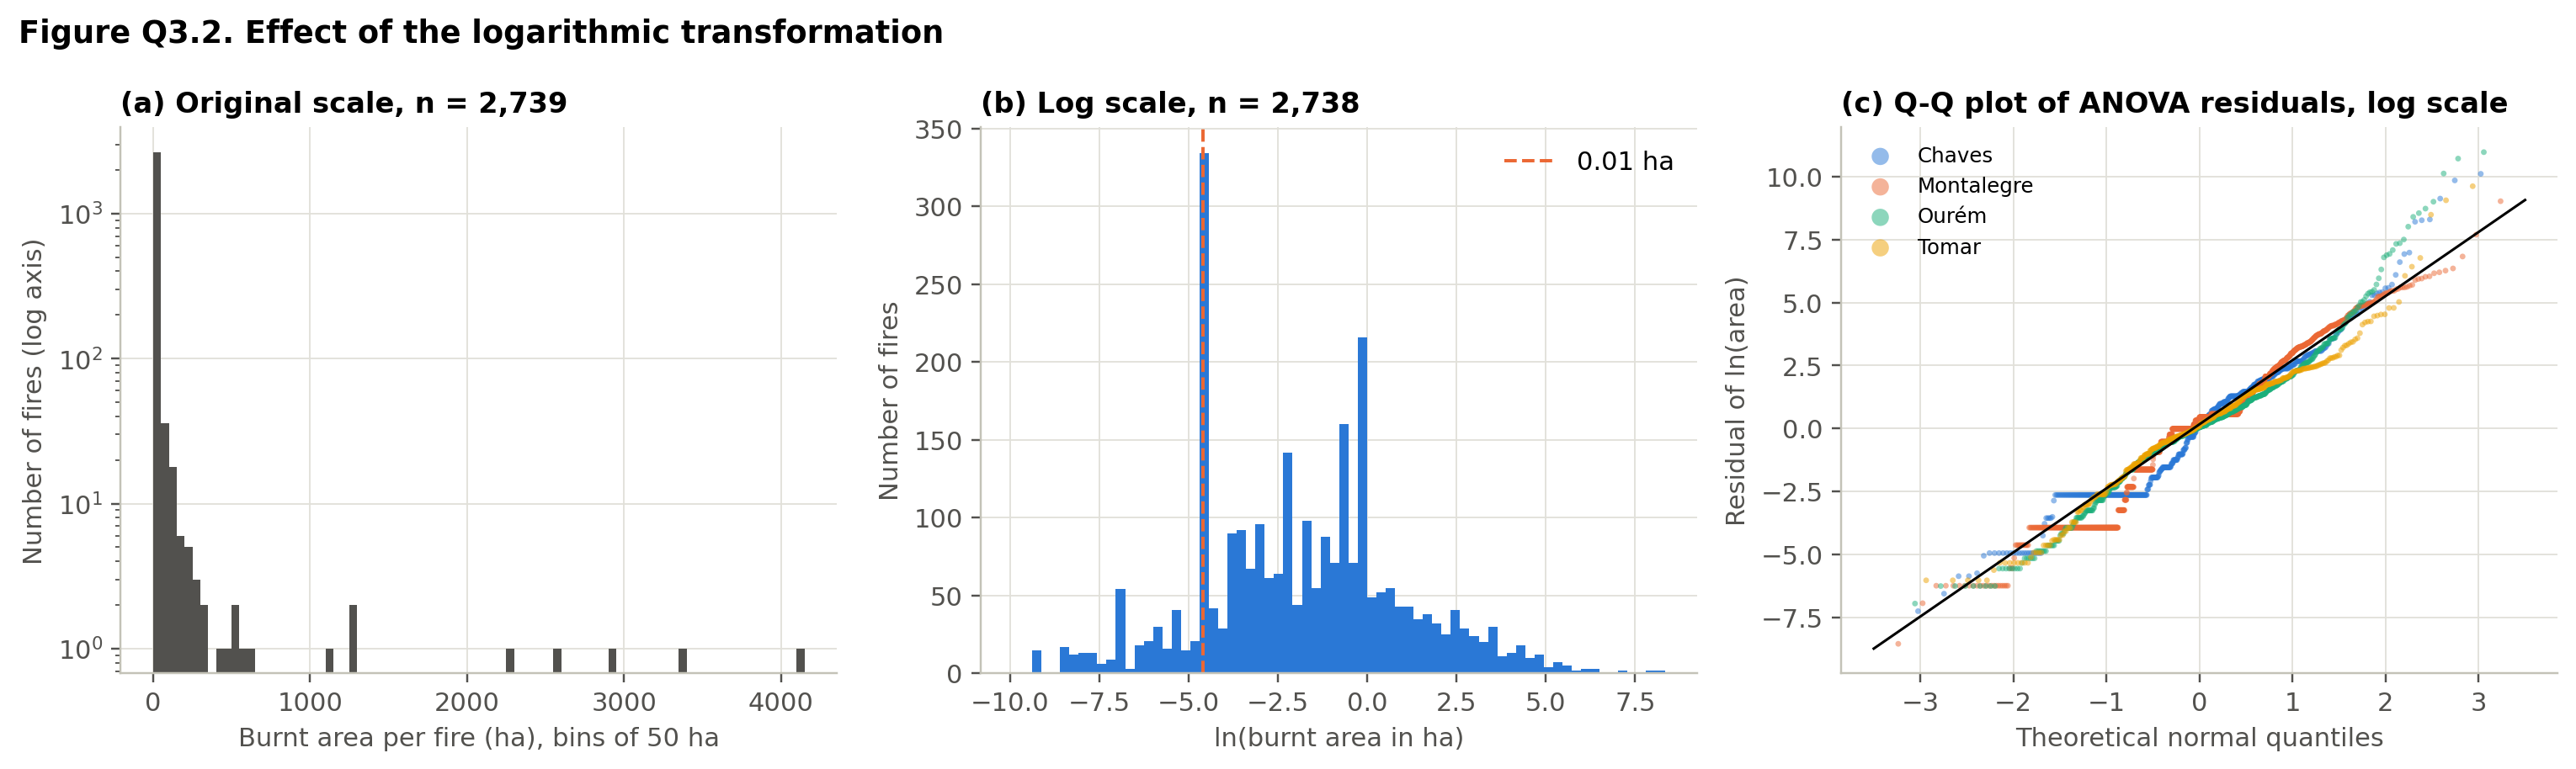

In [ ]:
# Figure Q3.2 - effect of the log transformation and normal Q-Q plot of the ANOVA residuals
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

axes[0].hist(q3[Y], bins=np.arange(0, q3[Y].max() + 50, 50), color="#52514e")
axes[0].set_yscale("log"); axes[0].set_xlabel("Burnt area per fire (ha), bins of 50 ha")
axes[0].set_ylabel("Number of fires (log axis)"); axes[0].set_title("(a) Original scale, n = 2,739")

axes[1].hist(q3_ln["ln_area"], bins=70, color="#2a78d6")
axes[1].axvline(np.log(0.01), color="#eb6834", linestyle="--", linewidth=1.3, label="0.01 ha")
axes[1].set_xlabel("ln(burnt area in ha)"); axes[1].set_ylabel("Number of fires")
axes[1].set_title("(b) Log scale, n = 2,738"); axes[1].legend(frameon=False)

resid = np.concatenate([x - x.mean() for x in ln_groups])
for m, x in zip(MUNICIPALITIES, ln_groups):
    (osm, osr), _ = stats.probplot(x - x.mean(), dist="norm")
    axes[2].scatter(osm, osr, s=5, alpha=.5, color=COLORS[m], edgecolor="none", label=m)
lo, hi = np.percentile(resid, [25, 75]); z = stats.norm.ppf(.75) - stats.norm.ppf(.25)
zz = np.linspace(-3.5, 3.5, 2)
axes[2].plot(zz, np.median(resid) + (hi - lo) / z * zz, color="black", linewidth=1)
axes[2].set_xlabel("Theoretical normal quantiles"); axes[2].set_ylabel("Residual of ln(area)")
axes[2].set_title("(c) Q-Q plot of ANOVA residuals, log scale"); axes[2].legend(frameon=False, markerscale=3, fontsize=8)

fig.suptitle("Figure Q3.2. Effect of the logarithmic transformation", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Assessment.**

| Assumption | Original scale (ha) | ln(area) |
|---|---|---|
| Independence | Not testable; possible clustering by place and time | Same |
| Normality of residuals | Severely violated: skewness 21.0, excess kurtosis 493 | Approximately symmetric: skewness 0.13, excess kurtosis 0.27; Shapiro-Wilk still rejects (W ≥ 0.96) |
| Equal variances | Variance ratio 29.2 (Levene p = 0.023). Brown-Forsythe p = 0.44: absolute deviations from the median do not differ significantly, because the large variance ratio is driven by a few extreme fires | Variance ratio 1.32 (SD 2.45–2.81), but Levene and Brown-Forsythe reject (p ≤ 0.0003) |

`log(1 + area)` is not used: because log(1 + x) ≈ x for areas below 1 ha (78 % of the fires), it leaves strong skewness (2.8). On the ln scale, the Q-Q plot follows the reference line closely except for stair-steps in the lower tail, produced by repeated rounded areas such as 0.01 ha, and a somewhat heavier upper tail in Ourém (excess kurtosis 1.4). Within-group skewness is at most 0.41 in absolute value.

**Decision.** The primary analysis is the **classical one-way ANOVA on ln(area)**, followed by **Tukey HSD**. The remaining departures are acknowledged rather than ignored:

- *Normality* is approximate. With at least 418 fires per group, the sampling distributions of the group means are close to normal, and the F test is robust to moderate departures of this kind.
- *Equal variances* cannot be claimed exactly, because Brown-Forsythe rejects homogeneity. The heterogeneity is small (variance ratio 1.32), and the largest group (Montalegre) also has the largest variance, which makes the classical F test conservative rather than liberal. Welch's ANOVA, which does not assume equal variances, is reported as a robustness check below.

The log scale was chosen on distributional grounds (the diagnostics above), not on the basis of test results, and the research question was then stated on that scale. Because this choice was informed by the data, the robustness checks below verify that the conclusion does not depend on it.

#### One-way ANOVA on ln(burnt area)

The ANOVA compares the variation between municipality means (SSB) with the variation of fires within municipalities (SSW): F = MSB / MSW, with k − 1 = 3 and N − k = 2,734 degrees of freedom. Under H₀, F is close to 1. The table is computed directly from the formulas and checked against `scipy.stats.f_oneway`. The effect size η² = SSB / SST is the share of the variance **of ln(area)** associated with municipality; ω², which is less biased, is reported alongside it.

In [ ]:
N, k = len(q3_ln), len(ln_groups)
grand = q3_ln["ln_area"].mean()
ssb = sum(len(x) * (x.mean() - grand) ** 2 for x in ln_groups)
ssw = sum(((x - x.mean()) ** 2).sum() for x in ln_groups)
df_b, df_w = k - 1, N - k
msb, msw = ssb / df_b, ssw / df_w
F, p_anova = msb / msw, stats.f.sf(msb / msw, df_b, df_w)
assert np.allclose((F, p_anova), stats.f_oneway(*ln_groups)), "manual ANOVA differs from scipy"
eta2, omega2 = ssb / (ssb + ssw), (ssb - df_b * msw) / (ssb + ssw + msw)

anova_tab = pd.DataFrame({"SS": [ssb, ssw, ssb + ssw], "df": [df_b, df_w, N - 1], "MS": [msb, msw, np.nan],
                          "F": [F, np.nan, np.nan], "p-value": [f"{p_anova:.3g}", "", ""]},
                         index=["Between municipalities", "Within (residual)", "Total"])
display(anova_tab.round(2))
print(f"F({df_b}, {df_w}) = {F:.2f}, p = {p_anova:.3g} | eta^2 = {eta2:.3f}, omega^2 = {omega2:.3f}")

# Group means on the log scale, back-transformed to geometric means (ha) with 95 % t-intervals
rows = {}
for m, x in zip(MUNICIPALITIES, ln_groups):
    half = stats.t.ppf(.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    rows[m] = {"n": len(x), "mean ln(area)": x.mean(), "sd ln(area)": x.std(ddof=1),
               "geometric mean (ha)": np.exp(x.mean()),
               "95% CI low (ha)": np.exp(x.mean() - half), "95% CI high (ha)": np.exp(x.mean() + half)}
gm = pd.DataFrame(rows).T.astype({"n": int})
display(gm.round(3))

,SS,df,MS,F,p-value
Between municipalities,3110.59,3,1036.86,140.43,1.27e-84
Within (residual),20186.83,2734,7.38,NaN,
Total,23297.42,2737,NaN,NaN,


F(3, 2734) = 140.43, p = 1.27e-84 | eta^2 = 0.134, omega^2 = 0.133


,n,mean ln(area),sd ln(area),geometric mean (ha),95% CI low (ha),95% CI high (ha)
Chaves,555,-1.977,2.712,0.139,0.110,0.174
Montalegre,1146,-0.683,2.813,0.505,0.429,0.594
Ourém,619,-2.973,2.712,0.051,0.041,0.063
Tomar,418,-3.200,2.452,0.041,0.032,0.052


**Interpretation.** F(3, 2734) = 140.4, p < 0.001, so H₀ is rejected at α = 0.05: the mean of ln(burnt area) is not the same in the four municipalities, which means that the geometric mean burnt area per fire differs between at least two of them. The geometric means are 0.50 ha (Montalegre), 0.14 ha (Chaves), 0.05 ha (Ourém) and 0.04 ha (Tomar).

The effect size is η² = 0.134 (ω² = 0.133): about 13 % of the variance of ln(burnt area) is associated with municipality, close to the conventional threshold for a large effect (0.14). It does not describe the variance of the area in hectares, and, as the data are observational, it is an association rather than a causal effect. Most of the variation (87 %) is between fires within the same municipality.

These geometric means differ from those reported by municipality for Q4 in Section 4.4 because the two analyses use different samples. Q3 does not depend on the cause of the fire and therefore includes all causes, whereas Q4 compares causes and includes only intentional and negligent fires; Q4 also covers both periods and uses log10(area) instead of ln(area).

#### Post-hoc comparisons (Tukey HSD)

Tukey HSD compares all six pairs while keeping the family-wise error rate at 5 %. With unequal group sizes, `scipy.stats.tukey_hsd` applies the Tukey-Kramer version. Each difference in ln(area) is exponentiated into a **ratio of geometric means**, with the municipality with the larger geometric mean placed first.

To express each difference in a way that does not depend on the log transformation, the table also gives the **probability of superiority**: the probability that a randomly chosen fire from the first municipality burnt a larger area than a randomly chosen fire from the second (ties count as one half; 0.5 means no difference). It is a descriptive effect size, computed from the Mann-Whitney U statistic on the original areas, and is not used as a test.

,difference in ln(area),ratio of geometric means,95% CI low,95% CI high,adjusted p,significant,P(first > second)
comparison,,,,,,,
Montalegre / Chaves,1.293,3.645,2.540,5.232,< 0.0001,True,0.629
Montalegre / Ourém,2.289,9.868,6.965,13.981,< 0.0001,True,0.730
Montalegre / Tomar,2.517,12.387,8.310,18.463,< 0.0001,True,0.754
Chaves / Ourém,0.996,2.707,1.799,4.072,< 0.0001,True,0.598
Chaves / Tomar,1.223,3.398,2.161,5.342,< 0.0001,True,0.619
Ourém / Tomar,0.227,1.255,0.807,1.953,0.5492,False,0.514


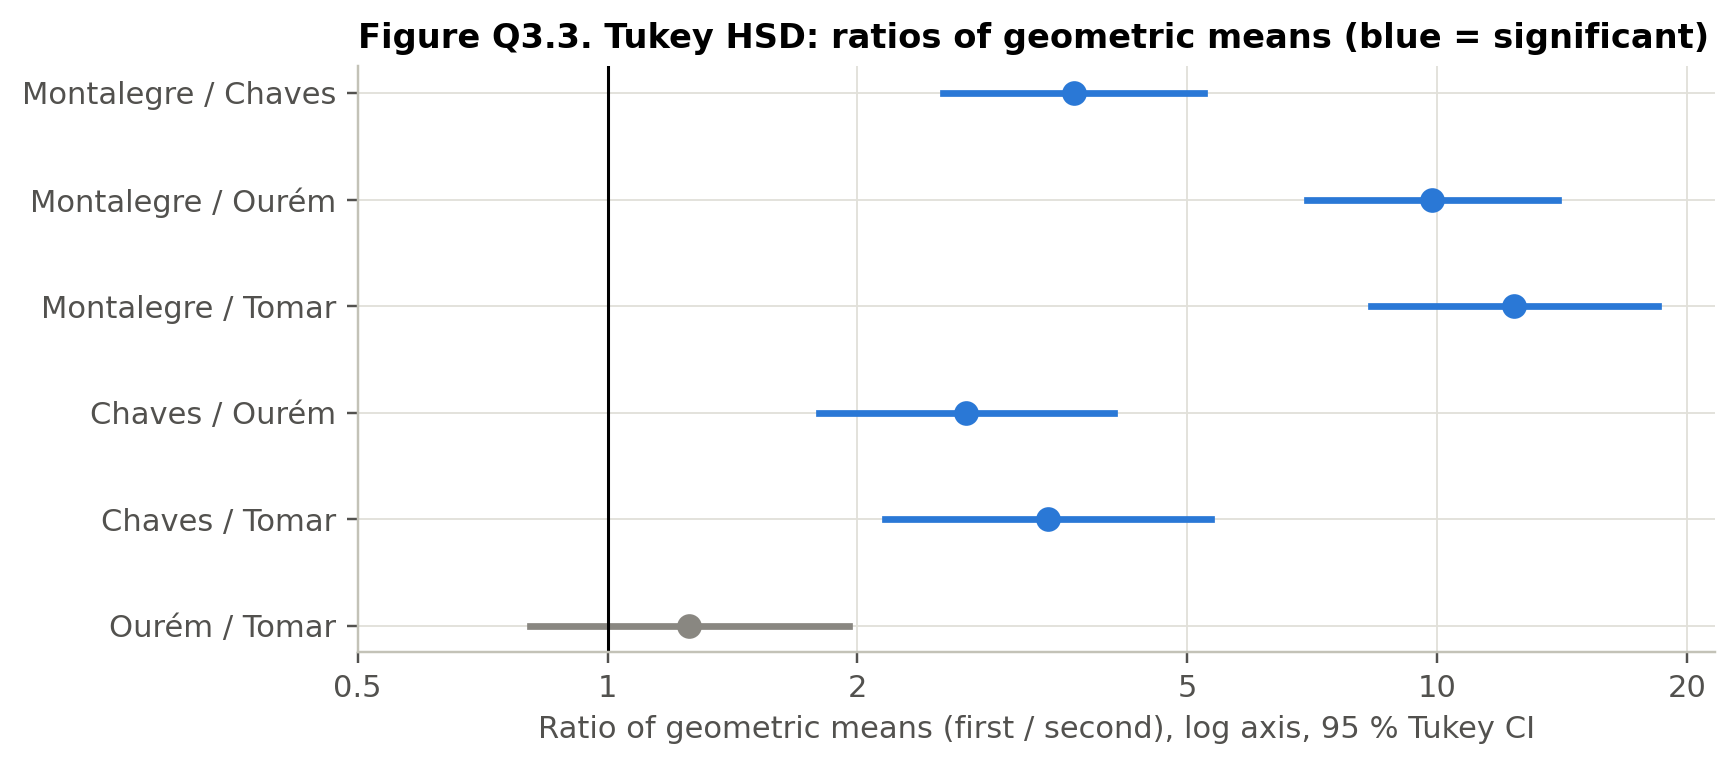

In [ ]:
tk = stats.tukey_hsd(*ln_groups)
ci = tk.confidence_interval(confidence_level=0.95)
order = np.argsort([-x.mean() for x in ln_groups])            # larger geometric mean first

rows = []
for a_pos in range(k):
    for b_pos in range(a_pos + 1, k):
        i, j = order[a_pos], order[b_pos]
        rows.append({"comparison": f"{MUNICIPALITIES[i]} / {MUNICIPALITIES[j]}",
                     "difference in ln(area)": tk.statistic[i, j], "ratio of geometric means": np.exp(tk.statistic[i, j]),
                     "95% CI low": np.exp(ci.low[i, j]), "95% CI high": np.exp(ci.high[i, j]),
                     "adjusted p": tk.pvalue[i, j], "significant": tk.pvalue[i, j] < 0.05,
                     "P(first > second)": stats.mannwhitneyu(raw_groups[i], raw_groups[j]).statistic
                                          / (len(raw_groups[i]) * len(raw_groups[j]))})
posthoc = pd.DataFrame(rows).set_index("comparison")
display(posthoc.round(3).assign(**{"adjusted p": posthoc["adjusted p"].map(lambda v: "< 0.0001" if v < 1e-4 else f"{v:.4f}")}))

# Figure Q3.3 - ratios of geometric means with 95 % Tukey confidence intervals
fig, ax = plt.subplots(figsize=(8, 3.6))
ypos = np.arange(len(posthoc))[::-1]
for y_, (_, r) in zip(ypos, posthoc.iterrows()):
    col = "#2a78d6" if r["significant"] else "#898781"
    ax.plot([r["95% CI low"], r["95% CI high"]], [y_, y_], color=col, linewidth=2.2)
    ax.scatter(r["ratio of geometric means"], y_, s=50, color=col, zorder=3)
ax.axvline(1, color="black", linewidth=1)
ax.set_xscale("log"); ax.set_yticks(ypos, posthoc.index)
ax.set_xticks([0.5, 1, 2, 5, 10, 20], ["0.5", "1", "2", "5", "10", "20"]); ax.minorticks_off()
ax.set_xlabel("Ratio of geometric means (first / second), log axis, 95 % Tukey CI")
ax.set_title("Figure Q3.3. Tukey HSD: ratios of geometric means (blue = significant)")
plt.tight_layout(); plt.show()

**Interpretation.** At a family-wise level of 5 %:

- **Montalegre** has a larger geometric-mean burnt area than each of the other municipalities: about 3.6 times that of Chaves, 9.9 times Ourém and 12.4 times Tomar (adjusted p < 0.001).
- **Chaves** exceeds Ourém (about 2.7 times) and Tomar (about 3.4 times) (adjusted p < 0.001).
- **Ourém and Tomar** do not differ significantly (ratio 1.26, 95 % CI 0.81–1.95, adjusted p = 0.55). This is not evidence that they are equal; the data are compatible with ratios from about 0.8 to 2.

Five of the six pairs therefore differ, giving the ordering Montalegre > Chaves > {Ourém, Tomar}.

**Practical size of the differences.** A randomly chosen fire in Montalegre burnt a larger area than one in Tomar in 75 % of pairs, than one in Ourém in 73 % and than one in Chaves in 63 %; a fire in Chaves exceeded one in Ourém or Tomar in about 60 % of pairs, whereas Ourém and Tomar were almost indistinguishable (51 %). The differences are therefore clear but far from a complete separation: the distributions of the four municipalities overlap considerably.

#### Robustness checks

The primary result is repeated under the alternative decisions that could most plausibly change it:

1. **Welch's ANOVA**, because Brown-Forsythe rejects equal variances on the log scale.
2. **Standard errors clustered by alert date**, which allow fires that start on the same day (and share weather conditions) to be correlated, as a partial check of independence.
3. **A common 0.01 ha floor** (all areas below 0.01 ha set to 0.01 ha, n = 2,739), because the recording precision of very small fires differs between municipalities (Section 3.3).
4. **log10(area + 0.001), keeping the fire with 0 ha**, as an alternative to the rule of Section 2.3, which excludes it, and as an alternative log scale.
5. **Excluding 2025**, because that year is incomplete (no records after early November).
6. **Year by year**, because the municipalities' fires are not spread evenly over the years (44 % of Tomar's fires occurred in 2018–2019, against about 24 % elsewhere) and some years were much more severe than others. Comparing the municipalities within each year removes this imbalance.

Kruskal-Wallis and permutation tests were not retained because they test hypotheses about whole distributions rather than about means of ln(area). Welch's ANOVA protects the overall test against unequal variances; for the pairwise comparisons, the heterogeneity is small (variance ratio 1.32), so Tukey–Kramer remains appropriate.

In [ ]:
def classical(samples):
    # classical one-way ANOVA: F, p-value, eta^2, n
    F_, p_ = stats.f_oneway(*samples)
    allv = np.concatenate(samples)
    eta_ = sum(len(x) * (x.mean() - allv.mean()) ** 2 for x in samples) / ((allv - allv.mean()) ** 2).sum()
    return F_, p_, eta_, len(allv)

def significant_pairs(samples):
    p = stats.tukey_hsd(*samples).pvalue
    return {(i, j) for i in range(k) for j in range(i + 1, k) if p[i, j] < 0.05}

floor = [np.log(np.clip(x, 0.01, None)) for x in raw_groups]          # all 2,739 fires, common 0.01 ha resolution
log10_var = [np.log10(q3.loc[q3["Concelho"] == m, Y].to_numpy() + 0.001) for m in MUNICIPALITIES]
no25 = [q3_ln.loc[(q3_ln["Concelho"] == m) & (q3_ln["Ano"] != 2025), "ln_area"].to_numpy() for m in MUNICIPALITIES]
welch = anova_oneway(ln_groups, use_var="unequal")

# Same model as the one-way ANOVA, with standard errors clustered by alert date (Wald F test of the 3 municipality terms)
by_date = q3_ln.assign(Concelho=q3_ln["Concelho"].astype(str), date=q3_ln["DataHoraAlerta"].dt.normalize())
clustered = smf.ols("ln_area ~ C(Concelho)", data=by_date).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(by_date["date"])[0]}).f_test(np.eye(k)[1:])

rows = [{"analysis": "Primary: classical ANOVA on ln(area)", "n": N, "df": f"{df_b}, {df_w}", "F": F, "p-value": p_anova,
         "eta^2": eta2, "same significant Tukey pairs": "-"},
        {"analysis": "Welch ANOVA on ln(area)", "n": N, "df": f"{welch.df_num:.0f}, {welch.df_denom:.0f}",
         "F": welch.statistic, "p-value": welch.pvalue, "eta^2": np.nan, "same significant Tukey pairs": "-"},
        {"analysis": f"ln(area), SE clustered by alert date ({by_date['date'].nunique()} days)", "n": N,
         "df": f"{clustered.df_num:.0f}, {clustered.df_denom:.0f}", "F": float(np.squeeze(clustered.fvalue)),
         "p-value": float(clustered.pvalue), "eta^2": np.nan, "same significant Tukey pairs": "-"}]
for label, samples in [("Classical, areas below 0.01 ha set to 0.01 ha", floor),
                       ("Classical, log10(area + 0.001)", log10_var),
                       ("Classical on ln(area), excluding 2025", no25)]:
    F_, p_, eta_, n_ = classical(samples)
    rows.append({"analysis": label, "n": n_, "df": f"{k - 1}, {n_ - k}", "F": F_, "p-value": p_, "eta^2": eta_,
                 "same significant Tukey pairs": significant_pairs(samples) == significant_pairs(ln_groups)})
robust = pd.DataFrame(rows).set_index("analysis")
robust["F"] = robust["F"].map("{:.1f}".format)
robust["p-value"] = robust["p-value"].map("{:.2e}".format)
robust["eta^2"] = robust["eta^2"].map(lambda v: "-" if np.isnan(v) else f"{v:.3f}")
display(robust)

# Ratios of geometric means: primary analysis vs common 0.01 ha floor
tk_floor = stats.tukey_hsd(*floor)
pos = {m: i for i, m in enumerate(MUNICIPALITIES)}
floor_ratio = [np.exp(tk_floor.statistic[pos[a], pos[b]]) for a, b in (c.split(" / ") for c in posthoc.index)]
display(pd.DataFrame({"primary": posthoc["ratio of geometric means"], "0.01 ha floor": floor_ratio},
                     index=posthoc.index).round(2))

# Year by year: geometric mean (ha) of each municipality and the resulting ordering
gm_year = q3_ln.groupby(["Ano", "Concelho"], observed=True)["ln_area"].mean().unstack().apply(np.exp)
display(gm_year.round(3).assign(ordering=gm_year.apply(lambda r: " > ".join(r.sort_values(ascending=False).index), axis=1)))
early = 100 * q3.loc[q3["Ano"] <= 2019, "Concelho"].value_counts(sort=False) / q3["Concelho"].value_counts(sort=False)
print("Share of each municipality's fires that occurred in 2018-2019 (%):", early.round(1).to_dict())

,n,df,F,p-value,eta^2,same significant Tukey pairs
analysis,,,,,,
Primary: classical ANOVA on ln(area),2738,"3, 2734",140.4,1.27e-84,0.134,-
Welch ANOVA on ln(area),2738,"3, 1238",142.8,1.83e-79,-,-
"ln(area), SE clustered by alert date (1160 days)",2738,"3, 1159",112.6,5.54e-64,-,-
"Classical, areas below 0.01 ha set to 0.01 ha",2739,"3, 2735",126.8,6.70e-77,0.122,True
"Classical, log10(area + 0.001)",2739,"3, 2735",139.4,4.58e-84,0.133,True
"Classical on ln(area), excluding 2025",2418,"3, 2414",110.5,4.89e-67,0.121,True


,primary,0.01 ha floor
comparison,,
Montalegre / Chaves,3.65,3.40
Montalegre / Ourém,9.87,6.82
Montalegre / Tomar,12.39,8.37
Chaves / Ourém,2.71,2.00
Chaves / Tomar,3.40,2.46
Ourém / Tomar,1.26,1.23


Concelho,Chaves,Montalegre,Ourém,Tomar,ordering
Ano,,,,,
2018,0.076,0.234,0.046,0.031,Montalegre > Chaves > Ourém > Tomar
2019,0.149,0.436,0.030,0.051,Montalegre > Chaves > Tomar > Ourém
2020,0.209,0.324,0.066,0.051,Montalegre > Chaves > Ourém > Tomar
2021,0.115,0.782,0.045,0.044,Montalegre > Chaves > Ourém > Tomar
2022,0.233,0.609,0.141,0.053,Montalegre > Chaves > Ourém > Tomar
2023,0.156,0.653,0.079,0.032,Montalegre > Chaves > Ourém > Tomar
2024,0.093,0.271,0.047,0.033,Montalegre > Chaves > Ourém > Tomar
2025,0.115,0.967,0.016,0.027,Montalegre > Chaves > Tomar > Ourém


Share of each municipality's fires that occurred in 2018-2019 (%): {'Chaves': 24.0, 'Montalegre': 25.0, 'Ourém': 23.4, 'Tomar': 44.0}


**Interpretation.** In every check the test remains highly significant (F between 110 and 143, p < 0.001), and wherever Tukey HSD applies it identifies the same five significant pairs. Allowing fires on the same day to be correlated lowers F only from 140.4 to 112.6. The answer to Q3 therefore does not depend on the assumption of equal variances, on same-day dependence between fires, on how very small fires are recorded, on the choice of log scale or on the incomplete year 2025.

The year-by-year table shows the same pattern within every year: Montalegre has the largest and Chaves the second-largest geometric mean in all eight years, while Ourém and Tomar share the last two places (Ourém is third in six years, Tomar in two), which is consistent with their non-significant difference. The result is therefore not produced by a few severe years or by the uneven distribution of each municipality's fires over time. The size of the differences does vary between years (Montalegre's geometric mean ranges from 0.23 to 0.97 ha), so the pooled ratios are averages over 2018–2025.

What does change is the **size** of the ratios. With a common 0.01 ha floor, the geometric means of Ourém and Tomar rise more than those of Chaves and Montalegre, and the Montalegre/Tomar ratio falls from 12.4 to 8.4 (Montalegre/Ourém from 9.9 to 6.8, Chaves/Tomar from 3.4 to 2.5, Chaves/Ourém from 2.7 to 2.0). The floor-based ratios compare the municipalities at a common recording resolution and are the more conservative estimates; the ratios of the post-hoc analysis partly reflect how very small fires are recorded.

---

### 4.4 Q4: Two-way ANOVA

A two-way ANOVA was chosen because the response variable (`Log_Total_Burnt_Area`) is quantitative and there are two qualitative factors with two levels each, `Cause_Type` (Intentional, Negligent) and `Period` (Pre-2017, Post-2017). This design gives four groups and allows us to test the effect of the cause, the effect of the period and the interaction between them. The research question is answered by the interaction term.

#### Hypotheses

(significance level α = 0.05)

| Effect | H₀ | H₁ |
|---|---|---|
| Cause_Type | The mean log burnt area is the same for intentional and negligent fires | The means differ |
| Period | The mean log burnt area is the same before and after 2017 | The means differ |
| Interaction | The difference between causes is the same in both periods | The difference between causes changes from one period to the other |

#### Checking the assumptions

ANOVA requires three conditions. The observations must be independent, the data within each group must be approximately normal, and the variability must be similar across groups.

Independence cannot be verified from observational records. Each row is a different fire, but fires are not necessarily independent of each other. Fires of the same year share the same weather conditions, several fires often occur on the same day in the same municipality, and some records are reignitions of earlier fires (see the independence check in Section 4.3). If observations are positively correlated, the standard errors of the ANOVA are underestimated and the p-values are too small. For this reason, effect sizes are reported alongside the p-values, and the trend and step model in the robustness checks uses standard errors clustered by year, which gives a more conservative test of the comparison between periods.

The other two conditions are checked below for each of the four Cause_Type x Period groups, using histograms and normal probability plots (Q-Q plots) for normality and comparing the standard deviations of the groups for constant variance.

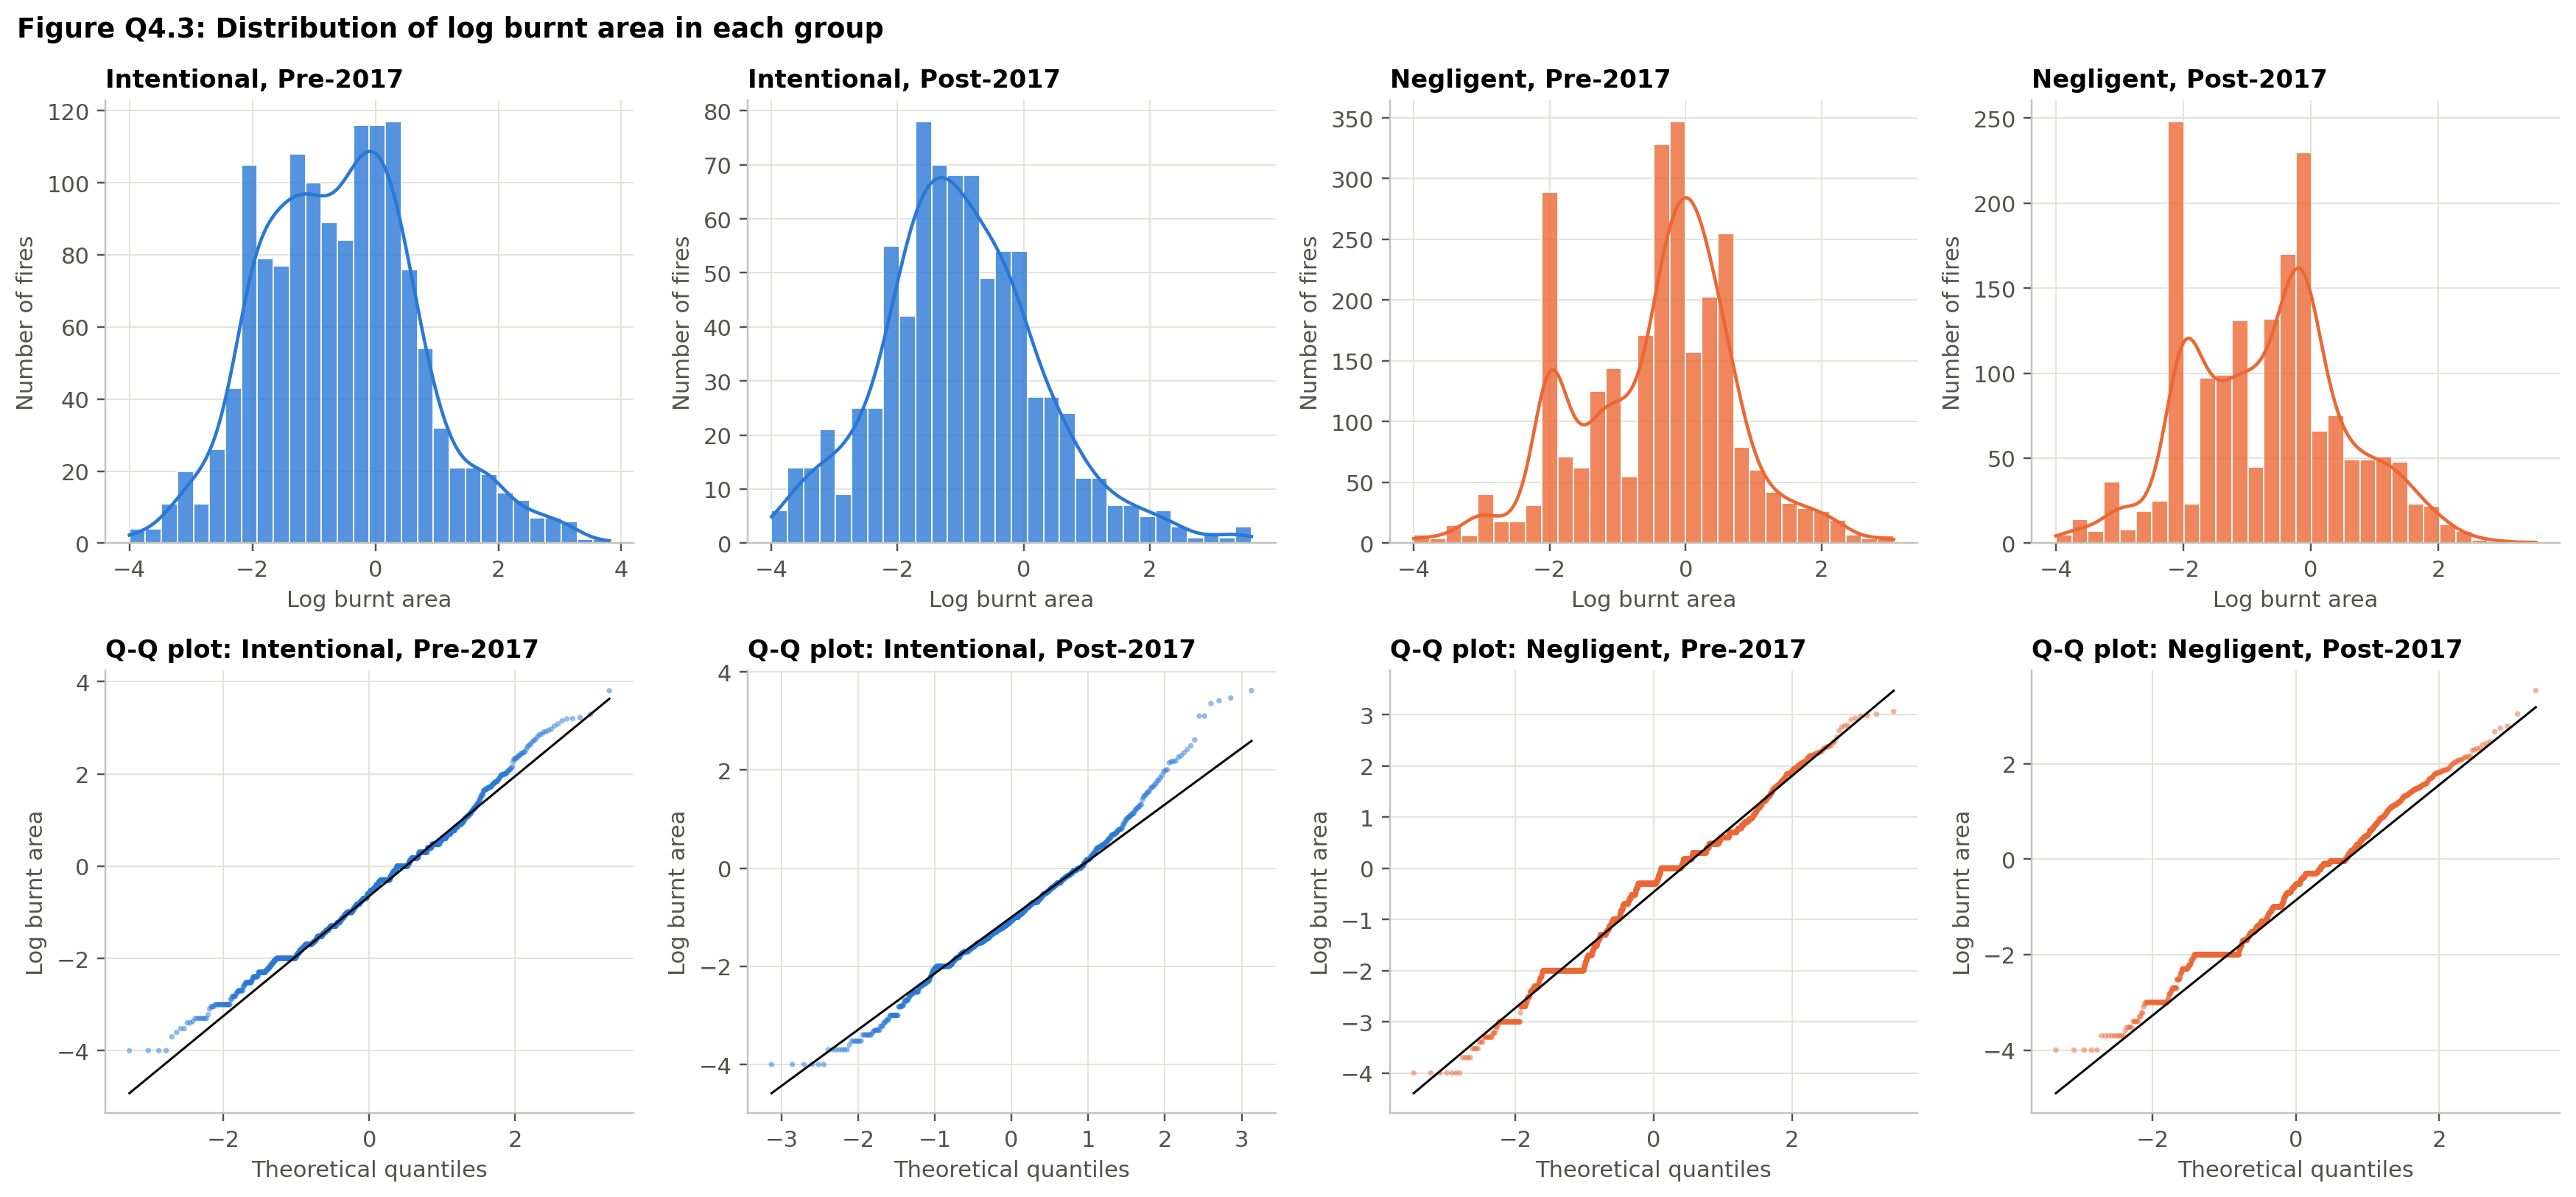

    Cause_Type     Period  Log_Total_Burnt_Area
0  Intentional   Pre-2017                 1.272
1  Intentional  Post-2017                 1.281
2    Negligent   Pre-2017                 1.149
3    Negligent  Post-2017                 1.221

Largest SD / smallest SD: 1.11
Levene test: W = 11.61, p = 1.39e-07


In [ ]:
# Normality within each group
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for i, ((cause, period), g) in enumerate(q4.groupby(["Cause_Type", "Period"], observed=True)):
    x = g["Log_Total_Burnt_Area"]
    sns.histplot(x, bins=30, kde=True, color=PAL_CAUSE[cause], alpha=0.8, edgecolor=SURFACE, ax=axes[0, i])
    axes[0, i].set_title(f"{cause}, {period}")
    axes[0, i].set_xlabel("Log burnt area")
    axes[0, i].set_ylabel("Number of fires")
    qq_panel(axes[1, i], x, PAL_CAUSE[cause], f"Q-Q plot: {cause}, {period}", ylabel="Log burnt area")
fig_title(fig, "Figure Q4.3: Distribution of log burnt area in each group")
plt.tight_layout()
plt.show()

# Constant variance: standard deviation of each group
sd_q4 = q4.groupby(["Cause_Type", "Period"], observed=True)["Log_Total_Burnt_Area"].std()
print(sd_q4.round(3).reset_index())
print(f"\nLargest SD / smallest SD: {sd_q4.max() / sd_q4.min():.2f}")

# Complementary test for equal variances (Levene, median-centred)
groups_q4 = [g["Log_Total_Burnt_Area"].values
             for _, g in q4.groupby(["Cause_Type", "Period"], observed=True)]
lev = stats.levene(*groups_q4, center="median")
print(f"Levene test: W = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")

**Normality.** On the log scale, the distributions are much closer to symmetric than the original data, but they are not normal. The intentional groups have a longer right tail, which corresponds to a small number of very large fires. The negligent groups show two peaks (at about -2 and 0) caused by the many fires recorded with exactly 0.01 ha and 1 ha. These peaks reflect the rounding of the recorded areas and also explain the horizontal steps in the Q-Q plots. There are no extreme outliers. Since ANOVA compares means and every group has at least 789 observations, the sampling distribution of each mean is approximately normal by the Central Limit Theorem, so this departure is not a concern.

**Constant variance.** The standard deviations range from 1.15 to 1.28, and the largest is only 1.11 times the smallest, so the variability is very similar across groups. The Levene test rejects equal variances (p < 0.001), but with more than 6,500 observations it detects differences too small to matter in practice. The condition of constant variance is considered satisfied.

#### Two-way ANOVA

The model includes the two main effects (Cause_Type and Period) and their interaction. Because the groups have different sizes, Type III sums of squares are used, so that each effect is tested after accounting for the others. Sum-to-zero coding is used so that each main effect is tested as an average across the levels of the other factor.

The effect size of each term is measured with partial eta squared (partial η²), which is the proportion of variability explained by the effect after removing the variability explained by the other effects. The usual reference values are 0.01 (small), 0.06 (medium) and 0.14 (large).

In [ ]:
model_q4 = smf.ols(
    "Log_Total_Burnt_Area ~ C(Cause_Type, Sum) * C(Period, Sum)", data=q4
).fit()

anova_q4 = sm.stats.anova_lm(model_q4, typ=3)
ss_res = anova_q4.loc["Residual", "sum_sq"]
anova_q4["partial_eta_sq"] = anova_q4["sum_sq"] / (anova_q4["sum_sq"] + ss_res)
anova_q4.loc[["Intercept", "Residual"], "partial_eta_sq"] = np.nan
anova_q4.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
anova_q4.round(4)

,sum_sq,df,F,PR(>F),partial_eta_sq
Intercept,2371.8246,1.0,1617.0371,0.0000,NaN
Cause_Type,82.0506,1.0,55.9396,0.0000,0.0085
Period,147.1931,1.0,100.3517,0.0000,0.0152
Cause_Type x Period,8.7289,1.0,5.9511,0.0147,0.0009
Residual,9551.6190,6512.0,NaN,NaN,NaN


All three effects are significant at α = 0.05.

- **Cause_Type** (F(1, 6512) = 55.94, p < 0.001). Negligent fires have a larger typical burnt area.
- **Period** (F(1, 6512) = 100.35, p < 0.001). The mean log burnt area is lower after 2017.
- **Interaction** (F(1, 6512) = 5.95, p = 0.015). The difference between causes changes between periods.

The effect sizes are small. Only Period reaches a small effect (partial η² = 0.015), Cause_Type is below this threshold (0.009) and the interaction is negligible (0.0009). The interaction is statistically significant because the large sample can detect very small differences, but its practical relevance is very limited. In other words, the difference between causes did change between periods, but by an amount that is small compared with the natural variation in burnt area from fire to fire.

#### Post-hoc analysis

Since the interaction is significant, the main effects alone do not fully describe the results. In a 2 x 2 design, the most direct follow-up is to compare each factor within each level of the other (simple effects). The two causes are compared within each period, which shows how the difference between causes behaves before and after 2017, and each cause is compared between periods, which shows how much each cause changed. Comparisons across both factors at once (for example, intentional fires before 2017 vs negligent fires after 2017) do not answer the research question and are not made.

In [ ]:
# Simple effects: each factor compared within each level of the other
# (Welch t-tests, Bonferroni correction over the 4 comparisons)
K = 4
alpha_bonf = 0.05 / K
y = "Log_Total_Burnt_Area"

def welch_row(label, a, b):
    t = stats.ttest_ind(a, b, equal_var=False)
    diff = a.mean() - b.mean()
    return {"comparison": label, "diff_log": diff,
            "ratio_geom_means": 10 ** diff,
            "t": t.statistic, "p_value": t.pvalue}

rows = []
for p in PERIOD_ORDER:                      # cause within each period
    sub = q4[q4["Period"] == p]
    rows.append(welch_row(f"Negligent - Intentional, {p}",
                          sub.loc[sub["Cause_Type"] == "Negligent", y],
                          sub.loc[sub["Cause_Type"] == "Intentional", y]))
for c in CAUSE_ORDER:                       # period within each cause
    sub = q4[q4["Cause_Type"] == c]
    rows.append(welch_row(f"Post-2017 - Pre-2017, {c}",
                          sub.loc[sub["Period"] == "Post-2017", y],
                          sub.loc[sub["Period"] == "Pre-2017", y]))

simple_q4 = pd.DataFrame(rows).set_index("comparison")
simple_q4["significant (Bonferroni)"] = simple_q4["p_value"] < alpha_bonf
print(f"Bonferroni significance level: 0.05 / {K} = {alpha_bonf:.4f}")
simple_q4.round(4)

Bonferroni significance level: 0.05 / 4 = 0.0125


,diff_log,ratio_geom_means,t,p_value,significant (Bonferroni)
comparison,,,,,
"Negligent - Intentional, Pre-2017",0.1660,1.4656,4.0630,0.0,True
"Negligent - Intentional, Post-2017",0.3267,2.1218,6.0049,0.0,True
"Post-2017 - Pre-2017, Intentional",-0.4103,0.3888,-7.1960,0.0,True
"Post-2017 - Pre-2017, Negligent",-0.2496,0.5628,-6.7238,0.0,True


Four comparisons were made, each factor within each level of the other, using Welch's t-test and a Bonferroni-corrected significance level of 0.05 / 4 = 0.0125.

- **Cause within each period.** Negligent fires have a significantly larger mean log burnt area than intentional fires both before and after 2017 (both p < 0.001). Back-transformed, the ratio of geometric means is about 1.5 before 2017 and about 2.1 after.

- **Period within each cause.** Both causes had significantly smaller fires after 2017 (both p < 0.001). The mean log burnt area fell by 0.41 log units for intentional fires and by 0.25 for negligent fires, which corresponds to geometric means about 61% and 44% lower, respectively.

Both causes decreased after 2017, but intentional fires decreased more, which moved the two causes further apart. The robustness checks below show whether this change in the gap between causes holds when municipality and the unequal number of years are taken into account.

#### Robustness checks

Three checks test whether the conclusions depend on choices made in the analysis: the equal-variance assumption and the rule for fires with 0 ha, the mix of municipalities in each group, and the unequal number of years before and after 2017.

##### Unequal variances and fires with 0 ha

1. **Unequal variances.** The ANOVA is repeated with heteroscedasticity-consistent standard errors (HC3). Normality is not a concern for the comparison of means, since every group has at least 789 observations and the sampling distribution of each mean is approximately normal by the Central Limit Theorem.

2. **Fires with 0 ha.** Following the rule in Section 2.3, the 3 fires with 0 ha are excluded. The ANOVA is repeated keeping them, with log10(area + 0.001), the scale used in the previous version of this analysis.

In [ ]:
# Check 1: ANOVA with heteroscedasticity-consistent errors (HC3)
anova_q4_hc3 = sm.stats.anova_lm(model_q4, typ=3, robust="hc3")
anova_q4_hc3.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
print(anova_q4_hc3[["F", "PR(>F)"]].round(4))

                             F  PR(>F)
Intercept            1514.4755  0.0000
Cause_Type             52.3916  0.0000
Period                 93.9869  0.0000
Cause_Type x Period     5.5737  0.0183
Residual                   NaN     NaN


In [ ]:
# Check 2: fires with 0 ha kept, using log10(area + 0.001)
q4_all = df_final[df_final["Cause_Type"].notna() & (df_final["Period"] != "Transition")].copy()
q4_all["log_shifted"] = np.log10(q4_all["Total_Burnt_Area"] + 0.001)

model_q4_all = smf.ols("log_shifted ~ C(Cause_Type, Sum) * C(Period, Sum)", data=q4_all).fit()
anova_q4_all = sm.stats.anova_lm(model_q4_all, typ=3)
anova_q4_all.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
print(f"n = {len(q4_all)} (including {int((q4_all['Total_Burnt_Area'] == 0).sum())} fires with 0 ha)")
print(anova_q4_all[["F", "PR(>F)"]].round(4))

n = 6519 (including 3 fires with 0 ha)
                             F  PR(>F)
Intercept            1587.4279  0.0000
Cause_Type             52.6953  0.0000
Period                 96.5346  0.0000
Cause_Type x Period     5.0036  0.0253
Residual                   NaN     NaN


**Interpretation.** With HC3 standard errors, the conclusions are the same (Cause_Type F = 52.39, Period F = 93.99, interaction F = 5.57, p = 0.018). Keeping the 3 fires with 0 ha and using log10(area + 0.001) gives F = 52.70 for Cause_Type, F = 96.53 for Period and F = 5.00 for the interaction (p = 0.025). The conclusions therefore do not depend on the equal-variance assumption or on how fires with 0 ha are handled.

##### Controlling for municipality

The four municipalities differ in typical fire size. Fires in Montalegre and Chaves are larger (geometric means of 0.66 ha and 0.34 ha), while fires in Ourém and Tomar are much smaller (0.07 ha and 0.08 ha). The municipalities also do not contribute equally to each group. Ourém accounts for 46% of intentional fires after 2017, compared with 26% before, while Montalegre accounts for more than half of all negligent fires. A change in the mix of municipalities could therefore create an apparent interaction. To check this, Municipality (`Concelho`) was added to the model as a blocking factor.

In [ ]:
# Typical burnt area in each municipality
mun_q4 = q4.groupby("Concelho").agg(
    n=("Log_Total_Burnt_Area", "size"),
    mean_log=("Log_Total_Burnt_Area", "mean"),
    median_ha=("Total_Burnt_Area", "median"),
)
mun_q4["geom_mean_ha"] = 10 ** mun_q4["mean_log"]
mun_q4.sort_values("mean_log", ascending=False).round(3)

,n,mean_log,median_ha,geom_mean_ha
Concelho,,,,
Montalegre,2682,-0.179,0.960,0.663
Chaves,1501,-0.464,0.500,0.344
Tomar,1134,-1.112,0.076,0.077
Ourém,1199,-1.142,0.064,0.072


In [ ]:
pd.crosstab(q4["Cause_Type_Period"], q4["Concelho"], normalize="index").round(2)

Concelho,Chaves,Montalegre,Ourém,Tomar
Cause_Type_Period,,,,
Intentional_Post-2017,0.18,0.11,0.46,0.25
Intentional_Pre-2017,0.29,0.15,0.26,0.31
Negligent_Post-2017,0.20,0.57,0.11,0.12
Negligent_Pre-2017,0.23,0.54,0.11,0.12


In [ ]:
model_q4_mun = smf.ols(
    "Log_Total_Burnt_Area ~ C(Concelho, Sum) + C(Cause_Type, Sum) * C(Period, Sum)",
    data=q4
).fit()
anova_q4_mun = sm.stats.anova_lm(model_q4_mun, typ=3)
anova_q4_mun.index = ["Intercept", "Municipality", "Cause_Type", "Period",
                      "Cause_Type x Period", "Residual"]
anova_q4_mun.round(4)

,sum_sq,df,F,PR(>F)
Intercept,2849.2668,1.0,2192.8991,0.0000
Municipality,1094.3772,3.0,280.7575,0.0000
Cause_Type,35.8052,1.0,27.5570,0.0000
Period,103.7255,1.0,79.8309,0.0000
Cause_Type x Period,0.5011,1.0,0.3857,0.5346
Residual,8457.2418,6509.0,NaN,NaN


With municipality in the model, cause type and period remain significant (p < 0.001), but the interaction does not (F = 0.39, p = 0.53). The wider gap after 2017 can therefore be explained by a change in where fires occurred, mainly the larger share of intentional fires in Ourém, and not necessarily by a change in the relationship between cause and fire size.

##### Balanced windows and pre-2017 trend

The pre-2017 period covers twice as many years as the post-2017 period, so a gradual change in fire size over time could appear as a Period effect. Two checks are applied:

1. **Balanced windows.** The two-way ANOVA is repeated with 8 years on each side of 2017 (2009–2016 vs 2018–2025).

2. **Trend and step model.** A linear regression with a separate linear trend and a separate step at 2017 for each cause (`Log_Total_Burnt_Area ~ neg * (year_c + post)`). The step answers whether fire size changed at 2017 beyond the trend, and the term `neg:post` answers whether that change differed between causes, which is the question of Q4. Standard errors are clustered by year.

In [ ]:
# Check 1: balanced windows (8 years before vs 8 years after 2017)
q4_bal = q4[q4["Ano"].between(2009, 2025)].copy()
print(pd.crosstab(q4_bal["Cause_Type"], q4_bal["Period"], margins=True))

model_q4_bal = smf.ols(
    "Log_Total_Burnt_Area ~ C(Cause_Type, Sum) * C(Period, Sum)", data=q4_bal
).fit()
anova_q4_bal = sm.stats.anova_lm(model_q4_bal, typ=3)
ss_res_bal = anova_q4_bal.loc["Residual", "sum_sq"]
anova_q4_bal["partial_eta_sq"] = anova_q4_bal["sum_sq"] / (anova_q4_bal["sum_sq"] + ss_res_bal)
anova_q4_bal.loc[["Intercept", "Residual"], "partial_eta_sq"] = np.nan
anova_q4_bal.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
anova_q4_bal.round(4)

Period       Pre-2017  Post-2017   All
Cause_Type                            
Intentional      1069        789  1858
Negligent        2294       1695  3989
All              3363       2484  5847


,sum_sq,df,F,PR(>F),partial_eta_sq
Intercept,2621.6905,1.0,1879.7813,0.0000,NaN
Cause_Type,115.9231,1.0,83.1182,0.0000,0.0140
Period,49.4454,1.0,35.4529,0.0000,0.0060
Cause_Type x Period,0.5367,1.0,0.3848,0.5351,0.0001
Residual,8149.1065,5843.0,NaN,NaN,NaN


In [ ]:
# Check 2: trend + step at 2017 for each cause (OLS, SE clustered by year)
q4_its = q4.assign(neg=(q4["Cause_Type"] == "Negligent").astype(int),
                   post=(q4["Period"] == "Post-2017").astype(int),
                   year_c=q4["Ano"] - 2017)

model_q4_its = smf.ols("Log_Total_Burnt_Area ~ neg * (year_c + post)", data=q4_its).fit(
    cov_type="cluster", cov_kwds={"groups": q4_its["Ano"].to_numpy()})

terms = {"year_c": "Trend per year, intentional",
         "neg:year_c": "Difference in trend (negligent - intentional)",
         "post": "Step at 2017, intentional",
         "neg:post": "Difference in step (negligent - intentional)"}
ci_its = model_q4_its.conf_int()
its_tab = pd.DataFrame({
    "estimate (log10 units)": model_q4_its.params[list(terms)],
    "95% CI low": ci_its.loc[list(terms), 0],
    "95% CI high": ci_its.loc[list(terms), 1],
    "p-value": model_q4_its.pvalues[list(terms)],
}).rename(index=terms)
print(its_tab.round(4).to_string())

step_neg = model_q4_its.t_test("post + neg:post = 0")
step_avg = model_q4_its.t_test("post + 0.5 * neg:post = 0")
print(f"\nStep at 2017, negligent      : {float(np.squeeze(step_neg.effect)):.4f} (p = {float(np.squeeze(step_neg.pvalue)):.4f})")
print(f"Step at 2017, average of both: {float(np.squeeze(step_avg.effect)):.4f} (p = {float(np.squeeze(step_avg.pvalue)):.4f})")

                                               estimate (log10 units)  95% CI low  95% CI high  p-value
Trend per year, intentional                                   -0.0797     -0.1309      -0.0286   0.0023
Difference in trend (negligent - intentional)                  0.0351      0.0012       0.0689   0.0425
Step at 2017, intentional                                      0.4271     -0.1597       1.0140   0.1537
Difference in step (negligent - intentional)                  -0.2578     -0.6325       0.1168   0.1774

Step at 2017, negligent      : 0.1693 (p = 0.4093)
Step at 2017, average of both: 0.2982 (p = 0.2106)


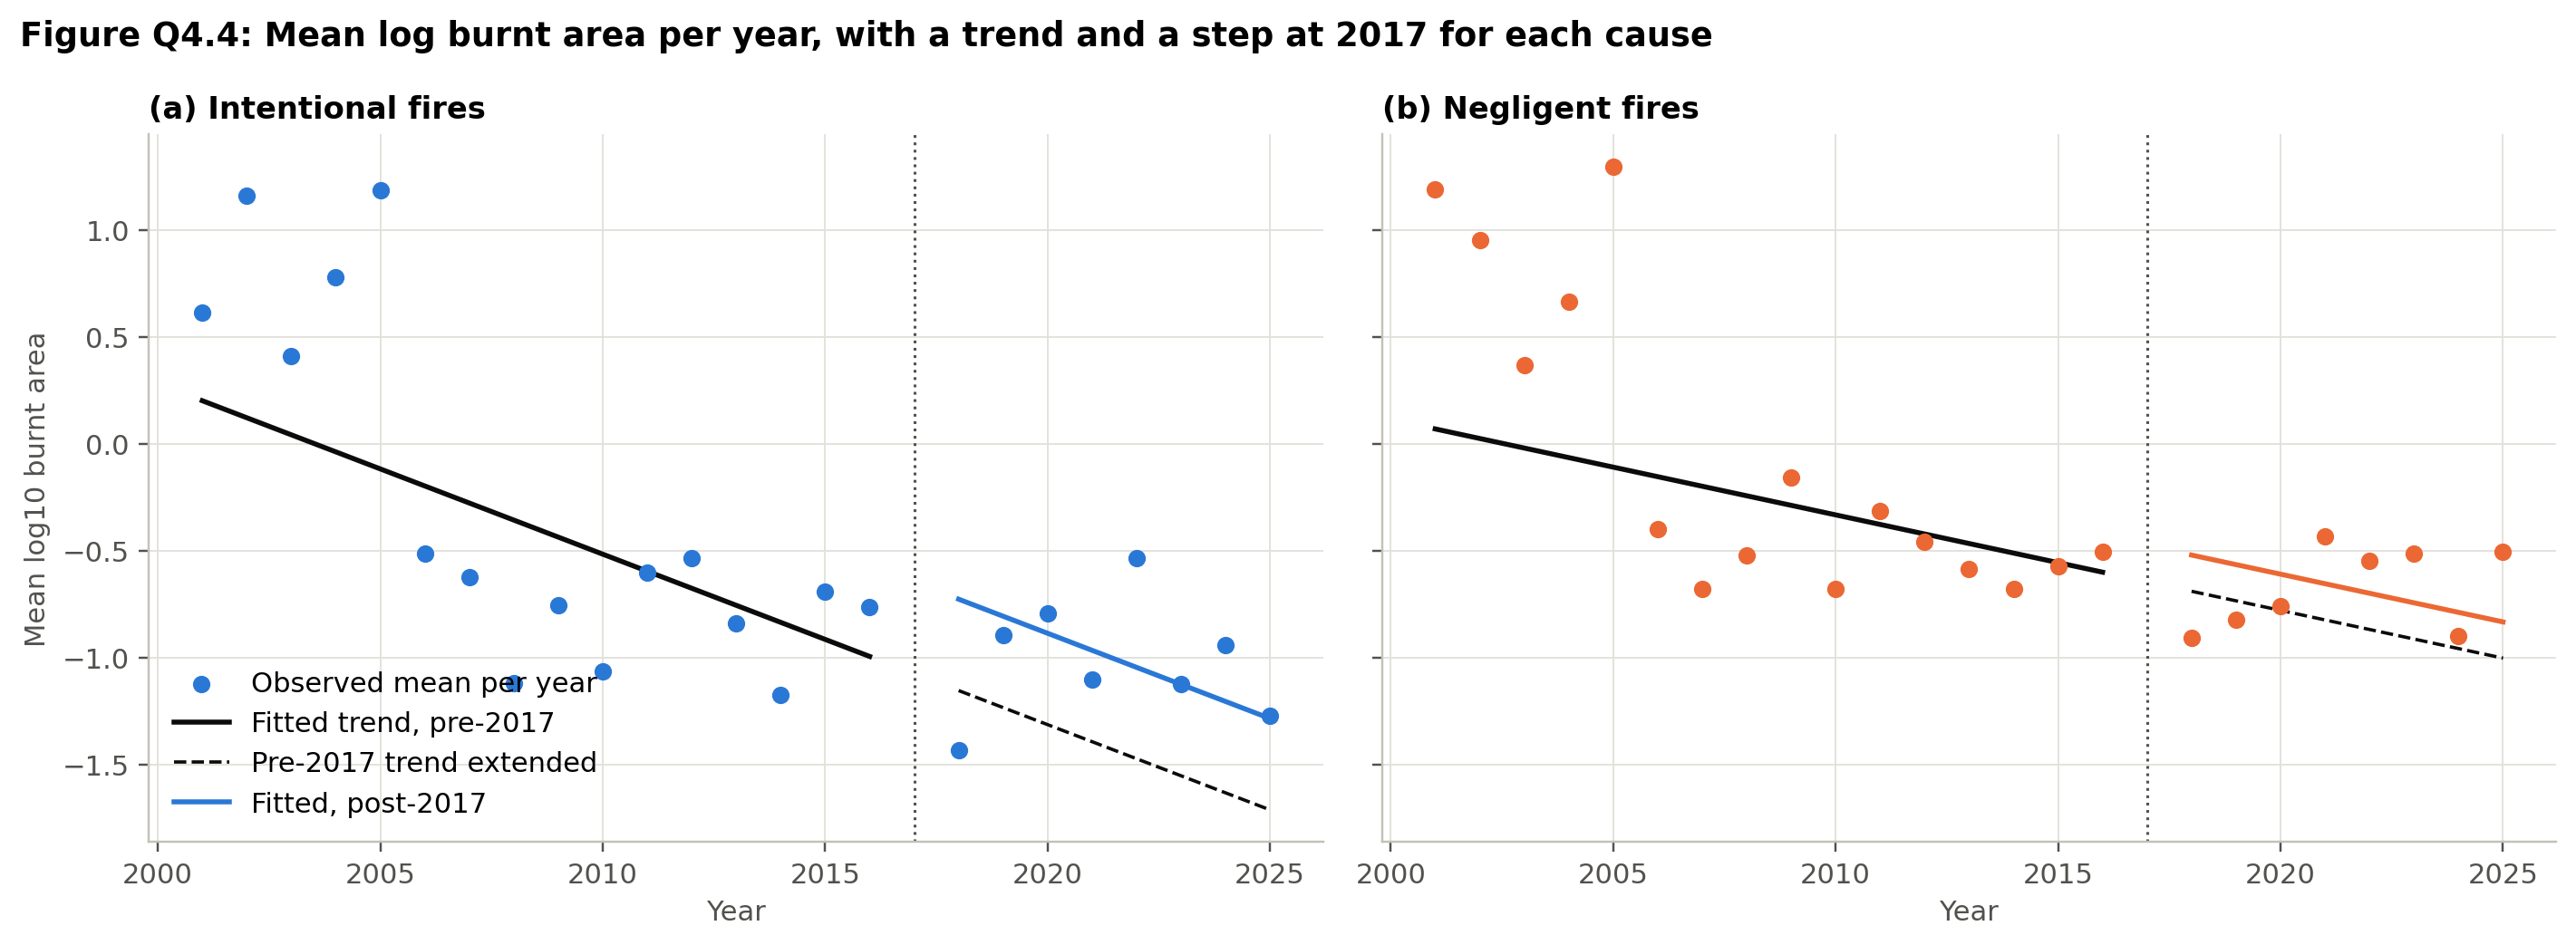

In [ ]:
yearly_q4 = (q4.groupby(["Ano", "Cause_Type"], observed=True)["Log_Total_Burnt_Area"]
               .mean().reset_index())
years_pre, years_post = np.arange(2001, 2017), np.arange(2018, 2026)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for tag, ax, cause in zip("ab", axes, CAUSE_ORDER):
    flag = int(cause == "Negligent")
    def pred(yrs, post):
        return model_q4_its.predict(pd.DataFrame({"neg": flag, "year_c": yrs - 2017, "post": post}))
    obs = yearly_q4[yearly_q4["Cause_Type"] == cause]
    ax.scatter(obs["Ano"], obs["Log_Total_Burnt_Area"], color=PAL_CAUSE[cause], s=28, zorder=3, label="Observed mean per year")
    ax.plot(years_pre, pred(years_pre, 0), color=INK, linewidth=1.8, label="Fitted trend, pre-2017")
    ax.plot(years_post, pred(years_post, 0), color=INK, linewidth=1.2, linestyle="--", label="Pre-2017 trend extended")
    ax.plot(years_post, pred(years_post, 1), color=PAL_CAUSE[cause], linewidth=1.8, label="Fitted, post-2017")
    ax.axvline(2017, color=MUTED, linestyle=":", linewidth=1)
    ax.set_title(f"({tag}) {cause} fires")
    ax.set_xlabel("Year")
axes[0].set_ylabel("Mean log10 burnt area")
axes[0].legend(loc="lower left")
fig_title(fig, "Figure Q4.4: Mean log burnt area per year, with a trend and a step at 2017 for each cause")
plt.tight_layout()
plt.show()

**Interpretation.** With balanced windows (2009–2016 vs 2018–2025), Cause_Type remains significant and becomes stronger (F = 83.12, p < 0.001, partial η² = 0.014). Period remains significant, but its effect is much smaller (F = 35.45, p < 0.001, partial η² = 0.006, below the threshold for a small effect, compared with F = 100.35 and 0.015 in the full analysis). The interaction is no longer significant (F = 0.38, p = 0.54), so the significant interaction found with the full period depends on the years 2001–2008.

In the trend and step model, fire size was already decreasing before 2017. The mean log burnt area of intentional fires fell by 0.080 log units per year (95% CI 0.029 to 0.131, p = 0.002) and that of negligent fires by about 0.045 log units per year, a significantly slower decrease (difference in trend p = 0.043). There is no step down at 2017. The average step is positive and not significant (0.30, p = 0.21), and so are the steps for intentional (0.43, p = 0.15) and negligent fires (0.17, p = 0.41). The difference in step between causes is not significant either (-0.26, p = 0.18).

Figure Q4.4 shows that much of the pre-2017 trend comes from 2001–2005, whose yearly means are far above those of later years, followed by a sharp drop around 2006. From 2006 onwards the yearly means change little. This pattern may reflect differences in how small fires were recorded in the oldest files rather than a real change in fire size, so the linear trend should be read with caution.

The Period effect of the two-way ANOVA therefore mostly reflects a decrease in fire size that was already under way before 2017, and cannot be attributed to the post-2017 period itself. There is no evidence that the gap between causes changed at 2017. In both analyses, the gap did not narrow.

---

## 5) Formulate Conclusions

This section gathers the answer to each secondary research question, based on the inferences drawn in Section 4.

### 5.1 Q1: Changes in Negligent Causes

**Critical period**

The two-proportion Z-test gives Z = -4.79 and p = 1.678 × 10⁻⁶. Since p < 0.05, we reject H₀. The proportion of fires caused by negligence decreased significantly, from 55.7% before 2017 to 47.4% after 2017.

**Non-critical period**

The test gives Z = 4.10 and p = 4.109 × 10⁻⁵. Again, since p < 0.05, we reject H₀. However, the opposite pattern is observed: the proportion of negligent fires increased from 82.6% to 88.2%.

**Were the changes similar across seasons?**

No. The Breslow-Day test (χ²(1) = 36.50, p < 0.001) and the logistic regression interaction test (χ²(1) = 36.83, p < 0.001) both confirm that the changes differ significantly between seasons.

The odds of a fire being classified as negligent decreased after 2017 during the critical period (OR = 0.72, 95% CI: 0.62–0.82). In the non-critical period, they increased instead (OR = 1.57, 95% CI: 1.26–1.95). This confirms that the change after 2017 was not the same throughout the year.

**Overall conclusion**

The results show that changes in negligent fire causes after 2017 were different across seasons. During the critical summer period, the proportion of negligent fires decreased significantly. This could suggest an improvement in prevention during the period of highest fire risk.

Outside this period, the opposite happened: negligent fires became even more common, increasing from 82.6% to 88.2%. This suggests that negligence remains a major issue throughout the non-critical months.

### 5.2 Q2: Daily Negligent Ignitions on Weekends and Weekdays

**Statistical decision**

- **Significance level:** $\alpha = 0.05$.
- **Two-sample Welch's t-test (post-2017 Weekend vs. Weekday):**
  - Weekday: $\bar{x} = 1.455$ ($s = 1.161$, $\text{median} = 1.0$, $\text{IQR} = 0.0$, $n_{\text{Weekday}} = 802$)
  - Weekend: $\bar{x} = 1.570$ ($s = 1.402$, $\text{median} = 1.0$, $\text{IQR} = 1.0$, $n_{\text{Weekend}} = 337$)
  - Difference in sample means ($\bar{x}_{\text{Weekend}} - \bar{x}_{\text{Weekday}}$): $+0.115$ ignitions/day ($\text{SE} = 0.0867$).
  - Test statistic and critical value: Welch's $t_{\text{obs}}(538.57) = 1.3223$, two-sided critical value $t_{\text{crit}} = \pm 1.9644$, $p\text{-value} = 0.1866$.
  - 95% confidence interval for $(\mu_{\text{Weekend}} - \mu_{\text{Weekday}})$: $[-0.056, \, 0.285]$.

Because $|t_{\text{obs}}| = 1.3223 < t_{\text{crit}} = 1.9644$ (falling outside the rejection region) and the $p\text{-value} = 0.1866 > \alpha = 0.05$, we **fail to reject the null hypothesis ($H_0$)** at the 5% significance level (the test is inconclusive). Consistently, the 95% confidence interval contains zero. Within the observed sample of active fire days, there is insufficient statistical evidence to claim that the population mean number of daily negligent ignitions differs between weekends and weekdays in the post-2017 period.

**Contextual discussion**

1. **Weekend vs. weekday patterns:** While the sample mean is nominally higher on weekends by $0.115$ ignitions/day, this variation is fully compatible with random sampling variability under $H_0$. The median daily count remains stable at $1.0$ across both subsets, which **suggests** that the typical active fire day involves isolated single occurrences rather than systematic weekend clusters.
2. **Consistency across municipalities (robustness check):** When disaggregating the post-2017 analysis by municipality (`Chaves`, `Montalegre`, `Ourém`, and `Tomar`), all four 95% confidence intervals in Figure Q2.3 cross zero and every municipal $p\text{-value}$ exceeds both the nominal $\alpha = 0.05$ and the Bonferroni-adjusted threshold ($\alpha_{\text{Bonf}} = 0.0125$). This is **consistent with** the conclusion that the absence of a significant weekend effect holds across the individual municipalities rather than being an artifact of pooling.
3. **Temporal consistency (pre vs. post on weekends):** The complementary comparison of weekend ignitions between periods yielded $t(657.32) = -0.5662$ ($p = 0.5715$), failing to reveal a statistically detectable difference in mean daily intensity on active weekends between the pre-2017 and post-2017 timeframes.

### 5.3 Q3: Burnt Area across Municipalities

**Answer to Q3.** The mean log-transformed burnt area per fire differed significantly across the four municipalities in 2018–2025 (one-way ANOVA, F(3, 2734) = 140.4, p < 0.001, η² = 0.13; n = 2,738). The geometric mean was highest in Montalegre (0.50 ha), followed by Chaves (0.14 ha), Ourém (0.05 ha) and Tomar (0.04 ha). Tukey HSD showed that Montalegre's geometric mean was 3.6 to 12.4 times those of the other municipalities and that Chaves's was 2.7 to 3.4 times those of Ourém and Tomar, while Ourém and Tomar could not be distinguished (ratio 1.26, 95 % CI 0.81–1.95). The result held with Welch's ANOVA and with standard errors clustered by alert date, with log10(area + 0.001) keeping the fire with 0 ha, and when all areas below 0.01 ha were set to 0.01 ha. Montalegre had the largest and Chaves the second-largest geometric mean in each of the eight years. In the last case, which compares the municipalities at a common recording resolution, the ratios were smaller (for example, 8.4 instead of 12.4 for Montalegre/Tomar): the ordering is robust, but the size of the ratios partly reflects how very small fires are recorded.

**Interpretation.** These results compare geometric means, that is, differences on a multiplicative scale; they are not a comparison of arithmetic mean burnt areas in hectares, for which the descriptive ranking is different (Chaves has the highest arithmetic mean) because a few very large fires dominate each mean. Because arithmetic means are dominated by a few extreme fires, these data do not support a reliable comparison of the expected burnt area per fire or of total burnt area, and Q3 makes no claim about either. In relative terms the differences are substantial (a fire in Montalegre burnt more than one in Tomar in 75 % of pairs), but in absolute terms they are small: all geometric means are below 1 ha, whereas most of the total burnt area comes from rare extreme fires, which the log scale deliberately down-weights.

### 5.4 Q4: Burnt Area by Cause Type and Period

The disparity in final burnt area between intentional and negligent fires did not narrow after 2017. The typical negligent fire was larger than the typical intentional fire in both periods, and this effect of the cause type is the most stable result of Q4, holding in every version of the analysis. The two-way ANOVA with the full period found a significant interaction (p = 0.015), but with a negligible effect size (partial η² = 0.0009), and it disappears both when municipality is included in the model (p = 0.53) and when the comparison is limited to 8 years on each side of 2017 (p = 0.54). There is therefore no consistent evidence that the gap between causes changed between periods.

Fires of both causes were smaller after 2017, but this reduction cannot be attributed to the post-2017 period. With balanced windows the period effect is much smaller (partial η² = 0.006), and the yearly data show a decrease that was already under way before 2017, mostly concentrated in the early 2000s, with no step at 2017 (Section 4.4). Over the whole period, the typical intentional fire became smaller faster than the typical negligent one, although intentional fires include the largest events, as shown by their much higher arithmetic mean.

Since this is an observational study, and the post-2017 period mixes years before and after the 2021 law, none of these changes can be attributed to specific policy measures.

### 5.5 Overall Answer

<!-- Draft: only the Q3 paragraph is written so far; Q1, Q2 and Q4 are to be added by the group. -->

**Burnt area across municipalities (Q3).** The main research question concerns burnt areas in four municipalities before and after 2017. Q3 addresses the municipal part of this question for the post-2017 period only (2018–2025) and does not compare the two periods. In that period the typical burnt area per fire differed clearly between the municipalities: it was largest in Montalegre, followed by Chaves, while Ourém and Tomar could not be distinguished, and this ordering held in each of the eight years. Two consequences matter for the project as a whole. First, results that pool the four municipalities depend on how many fires each one contributes, so a change in that mix between periods can change the pooled typical fire even if no municipality changes; in Q4, the interaction between cause and period was no longer significant once municipality was added to the model. Second, these differences concern the typical fire, with geometric means below 1 ha, and not total burnt area, which in every municipality is dominated by a few very large fires.

---

## 6) Look Back and Ahead

### 6.1 Limitations

#### Dataset

Five limitations affect interpretation and should be kept in mind when reading the results:

1. The Period split is set at 2017, but the law was only implemented in 2021. The post-2017 group therefore mixes years before and after the law took effect, so any change attributed to the post-2017 period cannot be separated from the effect of the law itself without a further split.

2. Initial_Response_Time and Fire_Duration depend on how consistently timestamps are recorded across municipalities. The alert source (FonteAlerta) also varies, and response time depends partly on who reported the fire. These differences may introduce variation between municipalities that is not caused by fire behaviour, and may indirectly affect the burnt areas compared in Q3 and Q4.

3. Burnt area appears to be estimated rather than measured for small fires, since rounded values such as 0.01, 0.5, 1 and 2 ha are much more frequent than intermediate values. This adds measurement error to the response variable of Q3 and Q4 and explains why the log burnt area is not normally distributed.

4. The four municipalities contribute unequally to each group, and their share changed between periods. In Q4, this change in composition was enough to produce a significant interaction that disappeared once municipality was added to the model, so results based on the pooled data should be read with this in mind.

5. The pre-2017 period covers 16 years and the post-2017 period only 8, with 2025 incomplete. This does not bias the tests, which compare proportions and means, but the two periods are centred about 13 years apart, so a gradual change over time can look like a post-2017 effect. For Q4, this was checked in Section 4.4 with balanced windows of 8 years on each side of 2017 and with a model including a trend and a step at 2017. The effect of the cause type holds and the interaction is no longer significant. The period effect remains significant, but its size becomes negligible (partial η² below 0.01), and it reflects a decrease in fire size that started well before 2017. The high burnt areas recorded in 2001–2005 are discussed in the Q4 limitations below.

#### Q2: Daily negligent ignitions

1. **Truncated/conditional sampling on active ignition days ($Y \ge 1$).** The SGIF database only records days on which at least one fire occurred in a given municipality. Municipal days with zero ignitions ($0$ fires) are unobserved in this aggregated table. As a result, the test evaluates the *operational density of ignitions given that an event occurred*, rather than the unconditional daily risk or overall community fire incidence rate.
2. **Spatial and temporal dependency (assumption of independence).** The two-sample t-test assumes mutually independent observations. In wildfire dynamics, ignitions occurring in neighbouring municipalities (e.g., Chaves and Montalegre) or on consecutive calendar days are often subject to common synoptic meteorological systems (such as heat waves or dry winds), introducing potential unmodelled spatial and temporal autocorrelation.
3. **Distributional shape and discrete nature.** Daily counts are non-negative integers bounded at 1 with strong right skewness (skewness $\approx 4$, excess kurtosis $\approx 20$). Although the Central Limit Theorem provides asymptotic approximation for the distribution of the sample mean given the substantial sample sizes ($n_1 = 337, n_2 = 802$), strong skewness slows convergence, and count-based generalized linear models would account more naturally for discrete structures.
4. **Retention of zero-area records ($0\text{ ha}$).** In this analysis, occurrences with a recorded burnt area of $0\text{ ha}$ (such as immediate interventions extinguished before spreading) were **explicitly retained** when computing `Daily_Ignitions_Count`, assuming that any validated negligent record in SGIF represents an actual ignition occurrence regardless of final area burned. However, maintaining or excluding these minor records shifts daily event counts, underscoring the sensitivity of empirical metrics to institutional reporting thresholds.

#### Q3: Burnt area across municipalities

The comparison is observational and unadjusted: the municipalities differ in vegetation, terrain, land use, weather and mix of ignition causes, so the differences cannot be attributed to any specific factor or policy. Independence of the records cannot be verified: allowing for correlation between fires on the same day leaves the conclusion unchanged, but other forms of clustering (for example, by parish or week) cannot be ruled out, so the p-values should be read as approximate. On the log scale, normality is approximate and variances are not exactly equal. Recorded areas are often rounded, and the recording precision of very small fires differs between municipalities, which affects the size of the ratios but not their ordering. One fire with 0 ha was excluded, 2025 is incomplete, and the 2018–2025 period combines years before and after the 2021 legislation.

#### Q4: Burnt area by cause type and period

1. **Selection of fires with a determined cause.** Q4 only includes fires classified as intentional or negligent. The first years of the series contribute far fewer of these fires: of the 4,032 pre-2017 fires in Q4, 3,363 are from 2009–2016, so 2001–2008 contribute only about 80 fires per year, compared with about 420 per year in 2009–2016. If, in the early years, causes were investigated mainly for larger fires, the pre-2017 sample overrepresents large fires. This would explain the high mean burnt areas of 2001–2005 (Figure Q4.4) and inflate the period effect. The interaction is less exposed, because this selection affects both causes, unless it differed between intentional and negligent fires.

2. **Changes in recording over time.** The data come from three ICNF files covering different decades, and the way burnt areas were estimated and recorded may have changed over time, especially for small fires (rounded values such as 0.01 ha and very small areas). Such changes can shift the mean log burnt area of a period for reasons unrelated to fire behaviour, which adds to the uncertainty of the period comparison.

3. **Incomplete 2025.** The 2025 records end on 4 November, so November and December, months of traditional burnings in which most fires are negligent, are missing. This slightly changes the composition of the post-2017 group, although the effect on the results is expected to be small.

### 6.2 Alternative Approaches and Future Work



#### Q1: Changes in negligent causes

Looking back at Q1, the two separate Z-tests answered whether the negligent share changed in each season, but not directly whether the change was the same in both. Section 4.1 therefore adds a chi-square analysis of the 2 × 2 × 2 table: the Breslow-Day test and a logistic regression with a `Period × Season` interaction show that the change differed significantly between seasons. Running this test from the start, instead of only the separate Z-tests, would have been the more direct design.

The comparison is still unadjusted. The four municipalities differ in fire size and in the mix of causes, and in Q4 adding municipality changed the conclusion about the interaction, so a pooled result for Q1 could also reflect a change in where fires occurred. Looking ahead, a logistic regression with `Period * Season_Risk_Period` plus `Municipality` would show whether the seasonal pattern holds within each municipality. The post-2017 period could also be split into 2018-2020 and 2021-2025 to separate the years before and after the 2021 law.

#### Q2: Daily negligent ignitions

1. **Full calendar reconstruction and hurdle models.** Construct an exhaustive daily panel grid (365 days $\times$ 25 years $\times$ 4 municipalities) and estimate a two-part Hurdle or Zero-Inflated Poisson / Negative Binomial model to simultaneously evaluate the probability of ignition occurrence ($P(Y > 0)$) and conditional count severity ($E[Y \mid Y > 0]$).
2. **Integration of environmental covariates.** Control for daily meteorological hazard indicators (such as the Fire Weather Index, Drought Code, and wind speed) as interacting covariates to assess whether weekend differences emerge specifically under critical atmospheric thresholds.

#### Q3: Burnt area across municipalities

Looking back at Q3, the recording precision of very small fires differs between municipalities, so the analysis with all areas below 0.01 ha set to 0.01 ha could have been the primary analysis rather than a robustness check: it compares the municipalities at a common resolution and gives more conservative ratios. The comparison is also unadjusted; adding the year or the cause of the fire as a second factor would show how much of the difference between municipalities reflects when and why the fires started.

Looking ahead, Q3 could be extended to both periods (municipality x period) to relate it directly to the main research question. Because burnt area is recorded for every fire, including those whose cause was not classified, this comparison would not depend on the cause classification. Since most of the total burnt area comes from a few very large fires, the probability that a fire exceeds a given size (for example 1 ha or 10 ha) would also complement the comparison of typical fires.

#### Q4: Burnt area by cause type and period

Looking back at Q4, municipality was only added as a robustness check. Since it explained much more variability than cause type or period, including it in the model from the start, for example with a three-way ANOVA (Cause_Type x Period x Municipality), would have been a more appropriate design. It would also show whether the change between periods differed between municipalities.

Looking ahead, the post-2017 period could be split into 2018-2020 and 2021-2025 to separate the years before and after the law. Since burnt area is skewed and contains many rounded values, a model for the median, such as quantile regression, would also be a useful alternative to the comparison of means.